# Single-stage KG-GT notebook (Using `main` module)

**Original single-stage notebook (pre Package 2 Phase B). The Phase-B experiment lives in `main_p2p.ipynb`; the EEG-residual experiment in `main_1stage_residual.ipynb`.**

This notebook is a copy of `main.ipynb` that trains **one stage**: the full KG-GT model
(Transformer encoder → muscle-node projection → kinematics-guided GAT → per-muscle decoder,
plus the kinematic skip highway and lag alignment) is trained **jointly from scratch**, with
every parameter trainable from the first epoch.

**What is different from `main.ipynb`**

| | `main.ipynb` (two-stage) | `main_1stage.ipynb` (this notebook) |
|---|---|---|
| Stage 1 | Transformer-only EEG model, `stage1_lr`=1e-3, 75 epochs, early stop after 10 epochs (`stage1_early_stop_patience`) | — (none) |
| Stage 2 / training | KG-GT, encoder/node-proj loaded from stage 1, everything except GAT, decoder, kin-skip, node-proj and the last 1–2 encoder layers **frozen**, `stage2_lr`=1e-4, `reduce` scheduler, no warmup, early stop after 25 epochs | KG-GT, **nothing frozen**, `single_stage.lr`=1e-3, `cosine` + 5 warmup epochs (AdamW), `single_stage.epochs`=200, early stop after 20 epochs (`single_stage.early_stop_patience`) |
| GAT / decoder init | re-initialised between stages | trained together with the encoder from epoch 1 |
| Checkpoints | `outputs/checkpoints_main_stage1/…`, `outputs/checkpoints_main_stage2/…` | `outputs/checkpoints_1stage/{subject}/` (`last.pt` + `best.pt`, resumable) |
| Results | `results/evaluation_report.md`, `results/magnitude_report.*`, `results/magnitude_by_load.*`, `results/input_ablation.*`, `outputs/interpretability/`, `outputs/interpretability_event/`, `outputs/losocv_results.csv` | `results/evaluation_report_1stage.md`, `results/magnitude_report_1stage.*`, `results/magnitude_by_load_1stage.*`, `outputs/interpretability_1stage/`, `outputs/interpretability_1stage_event/`, `outputs/losocv_results_1stage.csv`, `results/input_ablation_1stage.*` |

Everything else is identical to `main.ipynb`: same participants and condition-stratified
train/val/test split, same preprocessing and **same cache** (`data/cache_main_stride500_square_pose_force_sg51`;
preprocessing is identical, only training differs), same 24 kinematic inputs (10 hand-pose + 2
hand-near-object gated forces F_L, F_G → GAT edge bias; the gated forces + 10 SG-51 pose velocities +
2 gated-force velocities → additive kin skip highway), same loss (asymmetry 1.5, rest over-prediction
term, Huber δ=2.5, active-level term w_height 0.5, per-muscle weights), batch size,
gradient accumulation, grad clipping, AMP and seed. The parameter groups used by `train_model`
are the same as in stage 1 of `main.ipynb` (`transformer_lr_scale`=0.1 → encoder + node projection at
1e-4, GAT/decoder at 1e-3, kin-skip at lr/3 with stronger weight decay).

After the evaluation come the magnitude evaluation (burst height / rest level per test series and
hold-phase level per weight / surface) and the cell **"How much does the model use EEG vs kinematics?"**
— Pearson r on the test set with the kinematics zeroed / time-shuffled and with the EEG time-shuffled.
Both cells are the ones of `main.ipynb` (only the output file names differ), and so are the
interpretability / diagnostic cells: every prediction of a whole series goes through
`main.inference.predict_series_stitched` (1 s windows of the training window size). The interpretability
figures (per 10 s stretch: prediction, exact split of the output into EEG/graph path + kinematic path,
muscle-graph attention; event-locked over all test lifts, with EEG evidence only if the EEG measurably
changes the output) are described in the markdown cell above them.

Early stopping and the choice of the best epoch use a **smoothed** validation loss (mean of the last
5 epochs, `main/training.py`): `best.pt` is the epoch at which that moving average was lowest.

**How to compare with `main.ipynb`:** run both notebooks on the same `subject_list`; compare
`results/evaluation_report.md` (two-stage) with `results/evaluation_report_1stage.md` (this one) —
same test series, same metrics — and the best epoch / final val loss printed by the training loops;
`results/input_ablation.csv` vs `results/input_ablation_1stage.csv` shows whether the two training
schemes rely on EEG and kinematics differently.


In [1]:
import torch
import numpy as np
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import copy
from pathlib import Path

# Import from main
from main import (
    get_device, set_seed,
    load_participant, get_split_series,
    series_conditions, stratified_split, describe_split,
    preprocess_eeg, preprocess_eeg_from_config,
    preprocess_emg, preprocess_emg_from_config, EMGNormalizer,
    preprocess_kinematics, preprocess_kinematics_from_config, KinNormalizer,
    extract_kt, extract_kt_raw,
    WAYEEGDataset,
    KGGTModel, build_kg_gt_from_config, CNN1dAligner,
    build_transformer_only_from_config,
    CombinedEMGLoss, CompositeEMGLoss, CCCLoss, PearsonCorrelationLoss, TemporalSmoothnessLoss,
    build_loss_from_config,
    train_model, TrainConfig, TrainResult,
    collect_predictions, compute_metrics, EvalMetrics,
    prepare_batch_factory, save_checkpoint, load_checkpoint,
    print_gpu_info,
    compute_muscle_edge_prior,   # for edge-prior computation (follow-up step)
)

ROOT = Path(".")

In [2]:
set_seed(42)
device = get_device()
torch.backends.cudnn.benchmark = True
print(f"Device: {device}")


Device: cuda


In [3]:
CONFIG = {
    # ── Step 1: magnitude (on top of Package 1) ─────────────────────────────────
    # * gated load / grip force also feed the additive kin skip highway (amplitude path),
    #   not only the GAT edge bias; the velocities of the gated forces are kept as
    #   force-rate inputs → 24 kin features (same 26-column cache, other drop_indices)
    # * loss: asymmetry 1.5, huber_delta 2.5, new active-level term w_height 0.5
    # * stage 2: lr 1e-4 + early stop after 25 epochs without val improvement
    # * stage 1: early stop after 10 epochs without val improvement (stage1_early_stop_patience)
    # * single stage (this notebook): early stop after 20 epochs (single_stage.early_stop_patience)
    # move aside outputs/checkpoints_1stage (this notebook; main.ipynb uses its own two-stage folders)
    # before the first run (model input is now 24 features; resume=True would
    # otherwise try to load checkpoints of the old shape).
    "outputs":{
        "figures_dir": "docs/figure/method1",
        "run_tag": "step1",   # appended to the results/P{id}/main/<config> plot folder → no overwrite of older runs
    },
    "data": {
        "participant": "P1",       
        "data_root": "data/way-eeg/raw",
        "cache_dir": "data/cache_main_stride500_square_pose_force_sg51",  # new folder: hand pose + hand-near-object gated forces (26 cached kin cols)
        # window_size=4000 @ 500 Hz = 8 s window; stride=250 = 0.5 s step
        # chunked transformer: 4000 / chunk_size=500 = 8 chunks of 500 → O(500²) not O(4000²)
        "window_size": 500,
        "stride": 500,
        # latency_shift_ms eliminated: Transformer attention learns asymmetric corticomuscular conduction delay
        "fs_eeg": 500,                   # Hz
        "fs_emg": 4000,                  # Hz (raw); downsampled to fs_eeg after preprocess
        "fs_kin": 500,                   # Hz
        "n_eeg_channels": 32,
        "n_emg_channels": 5,
        "n_kin_raw": 36,                 # raw kin cols in hs.kin.sig
        "n_kin_features": 24             # model input: hand pose (10) + gated F_L, F_G (2) + pose velocity (10) + gated F_L, F_G velocity (2)
    },
    "preprocessing": {
        "eeg": {
            "bp_low": 0.5,                  # Hz, bandpass lower bound
            "bp_high": 40.0,                # Hz, bandpass upper bound
            "artifact_method": "ica_auto",  # "asr" | "ica_auto" | "ica_manual"
            "filter_order": 4,
            "notch_freq": 50.0,             # Hz, power-line
            "asr_window_ms": 500,           # ms, ASR sliding window
            "asr_std_thresh": 5.0,          # sigma, ASR rejection threshold
            "delta_low": 0.5,               # Hz, delta-band lower bound
            "delta_high": 40.0,             # Hz, delta-band upper bound
            "use_car": False,
            "use_tkeo": True,
            #"target_channels": ["FC1", "FC2", "C3", "Cz", "C4", "CP1", "CP2", "CP6"]
        },
        "emg": {
            "bp_low": 30.0,              # Hz
            "bp_high": 300.0,            # Hz
            "filter_order": 4,
            "lp_cutoff": 8.0,            # Hz, near-DC → flat-top square-like activation bursts
            "lp_order": 4,               # 8th-order → brick-wall roll-off, flat plateau between bursts
            "downsample_factor": 8,      # 4000 -> 500 Hz
            "envelope_method": "tkeo", # strictly causal full-wave rectification default
            "causal": True,              # strict forward-only causal filtering (no lookahead)
        },
        "kinematics": {
            "include_velocity": True,      # if true, output includes velocity
            "include_acceleration": False, # off: the SG 2nd derivative amplifies marker jitter at rest
            # Object forces count only while the hand is at the object: F_L, F_G are multiplied by a gate
            # (1 while index-object distance <= near_cm, linear ramp to 0 at far_cm, 0.1 s zero-phase
            # smoothing) BEFORE velocities are computed. Loading of the object by someone else while the
            # hand is parked (~28 cm away) is removed. None / absent = forces not gated.
            "gated_force": {"near_cm": 12.0, "far_cm": 20.0, "smooth_s": 0.1},
            "drop_indices": [12, 25],  # = POSE_FORCE_RATE_DROP_INDICES: drop rho_GL and its velocity → 24 = [hand pose 10, F_L_gated, F_G_gated, pose velocity 10, v_F_L_gated, v_F_G_gated]
            "velocity_method": "sg",     # 'sg' (Savitzky-Golay) | 'bw' (Butterworth diff)
            "sg_window": 51,             # SG window length (samples, must be odd); 51 = 102 ms at 500 Hz → less jitter at rest
            "sg_poly": 3,                # SG polynomial order
            "bw_cutoff": 20.0,           # LP cutoff Hz before diff (used when method='bw')
            "bw_order": 4,               # Butterworth order (used when method='bw')
            "normalize": True            # per-feature z-score over training set
        },
    },
    "model": {
        "type": "transformer_regressor",
        "transformer": {
            "n_layers": 4,
            "n_heads": 8,
            "d_model": 128,
            "d_k": 32,
            "d_v": 32,
            "ffn_dim": 512,
            "dropout": 0.2,
            # chunk_size=500 with window_size=4000 → 8 chunks of 500
            # → O(500²)=250K scores per head (not O(4000²)=16M)
            # MUST divide window_size evenly or a RuntimeWarning fires and
            # full O(T²) attention is used (catastrophically slow).
            "chunk_size": 500
        },
        "gat": {
            "n_layers": 2,
            "node_dim": 64,
            "hidden_dim": 64,
            "heads": 4,
            "dropout": 0.2,
            "use_kinematic_guidance": True,
            "kin_gat_dim": 12,             # first 12 kin features (pose 10 + gated F_L, F_G) → GAT edge bias
            "kin_skip_indices": list(range(10, 24)),  # → kin skip highway (adds to the node embeddings = amplitude path): gated F_L, F_G + all 12 velocities
        },
        "decoder": {
            "out_channels": 5            # predicted EMG channels
        }
    },
    "training": {
        "loss": {
            "w_peak":          1.0,     # Peak-weighted MSE weight
            "w_ccc":           0.5,     # Concordance Correlation Coefficient weight (prevents Mean Collapse)
            "w_pearson":       0.2,     # Pearson correlation timing weight
            "w_diff":          0.1,     # First-order temporal smoothness weight
            "w_rest":          0.05,    # Resting baseline L1 penalty
            "w_reg":           0.001,   # GAT EdgePrior KL divergence anchor
            "peak_alpha":      3.0,     # Multiplier for burst tips in PeakMSE
            "asymmetry":       1.5,     # Under-prediction penalty (Package 1: 1.2 — too weak a pull towards burst height; 2.0 before)
            "rest_threshold":  0.15,    # Rest threshold fraction
            "eps":             1e-6,    # Denominator clamp for AMP FP16 numerical stability
            "use_peak_weight": True,    # set False for ablation back to standard MSE
            "w_rest_over":     1.0,     # one-sided squared over-prediction where the target is at rest (baseline recovery)
            "huber_delta":     2.5,     # robust peak-weighted error (z units): squared inside ±2.5, linear outside; None = squared (Package 1: 1.0)
            "channel_weights": "auto",  # per-muscle weights ∝ 1/p95(|z|) of the training targets, mean 1 (computed per subject)
            "w_height":        0.5,     # active-level term: per window/muscle, relative error of the mean level above the window minimum over the non-rest samples (under-prediction × asymmetry, smooth-L1)
            "height_eps":      0.5,     # its denominator floor (z units) so noise-only windows do not give huge relative errors
        },
        # ── optimizer ─────────────────────────────────────────────────────
        "optimizer":   "adamw",   # 'adam' | 'adamw'
        "weight_decay": 1e-2,     # AdamW weight decay (ignored for adam)
        # ── scheduler ─────────────────────────────────────────────────────
        "scheduler":   "cosine",  # 'reduce' | 'cosine'
        # reduce-specific
        "lr_patience": 5,
        "lr_factor":   0.5,
        # cosine-specific
        "cosine_t_max":   None,   # None → use max_epochs
        "cosine_eta_min": 1e-6,
        # ── common ────────────────────────────────────────────────────────
        "loss_lambda":  1.0,      # 1.0 = plain MSE; <1.0 enables Soft-DTW (O(T²), DO NOT use at T=4000)
        "stage1_lr": 1e-3,
        "warmup_epochs": 5,
        "stage2_lr": 1e-4,          # two-stage only (unused here)
        # Early stopping (main/training.py): the "best" epoch is the one with the lowest
        # SMOOTHED validation loss = mean of the last 5 epochs' val losses (the raw val loss
        # during the first 4 epochs); best.pt holds the weights of the epoch at which that
        # value was reached, and patience counts epochs without a new smoothed best.
        "stage1_early_stop_patience": 10,   # two-stage only (unused here)
        "stage2_early_stop_patience": 25,   # two-stage only (unused here)
        "transformer_lr_scale": 0.1,
        # batch_size=4 with T=4000 keeps VRAM safe on GTX 1660 Ti (6 GB).
        # effective batch = batch_size * gradient_accumulation_steps = 4 * 8 = 32
        # Tune batch_size up (e.g. 8) if VRAM is available; reduce grad_accum_steps proportionally.
        "batch_size":          32,
        "gradient_accumulation_steps": 2,
        "early_stop_patience": 50,   # shared default (not used by the single stage: single_stage.early_stop_patience)
        "grad_clip_norm":      1.0,
        "stage1_epochs":       75,  # two-stage only (unused here)
        "max_epochs":          200,
        # use_amp=True: enables FP16 mixed precision via torch.autocast + GradScaler.
        # GTX 1660 Ti (sm_75 Turing) has FP16 tensor cores → ~1.5-2x speedup.
        # Requires PyTorch >= 2.0. Set False only if you see NaN losses.
        "use_amp":             True,
        "log_memory_every":    50,
        "losocv": True,           # leave-one-subject-out cross-validation
        "checkpoint_every":     1,
        # ── single-stage (this notebook) ──────────────────────────────────
        # Checkpoints -> outputs/checkpoints_1stage/{subject}/ — never the two-stage folders.
        "checkpoint_dir": "outputs/checkpoints_1stage",
        # The full KG-GT model is trained ONCE, jointly, nothing frozen.
        # Only lr / epochs / patience live here; everything else is the shared key above:
        #   optimizer="adamw", scheduler="cosine" (eta_min 1e-6), warmup_epochs=5,
        #   transformer_lr_scale=0.1 (encoder+node-proj at lr*0.1, as in stage 1),
        #   grad_clip_norm, use_amp, batch_size, gradient_accumulation_steps, seed.
        "single_stage": {
            "lr":     1e-3,     # = stage1_lr (GAT/decoder group; encoder x transformer_lr_scale)
            "epochs": 200,      # = max_epochs
            # epochs without a new best of the SMOOTHED val loss (5-epoch moving average,
            # main/training.py; best.pt is selected on that smoothed value too)
            "early_stop_patience": 20,
        },
        "seed":                42,
    },
    "dataset": {
        # Keep in sync with data.window_size / data.stride above
        "window_size": 500,
        "stride": 500,
    }
}
# Plot folders (main.plots.get_dynamic_fig_dir) are keyed on training["lr"], which
# otherwise falls back to stage2_lr (= the two-stage folder) — point them at the
# single-stage LR so saved figures do not overwrite main.ipynb's.
CONFIG["training"]["lr"] = CONFIG["training"]["single_stage"]["lr"]
notebook_cfg = copy.deepcopy(CONFIG)

### EMG channel names (true order)

`hs.emg.names` of every `HS_P{p}_S{1..9}.mat` lists the five EMG channels in this order (checked for P1–P12: identical for all participants and series):

| channel | muscle (name in the data files) | label used in this notebook | label in outputs made before this fix |
|---|---|---|---|
| 0 | Anterior Deltoid | AD | "FDI" |
| 1 | Brachoradial (brachioradialis) | BR | "APB" |
| 2 | Flexor Digitorum | FD | "ADM" |
| 3 | Common Extensor Digitorum | ED | "ECR" |
| 4 | First Dorsal Interosseus | FDI | "FCR" |

Every cell now takes the names per subject from `main.dataloader.emg_channel_names(participant, data_dir)`, which reads them from that participant's HS files (and raises if the series of a participant disagree). Earlier versions hard-coded `["FDI", "APB", "ADM", "ECR", "FCR"]`, which is **not** the channel order of the data: figures, tables, CSV files and reports produced before this fix (including cell outputs saved in this notebook that have not been re-run) carry the wrong labels — translate them with the table above. Only the labels were wrong; channel order, data, model and metrics are unchanged.


### Train / val / test split (per participant, condition-stratified)

Each participant has 9 series: 5×**W** (weight varies, surface fixed), 2×**S** (surface varies, weight fixed), 2×**B** (both vary), read from `BlockType` in `P{p}_AllLifts.mat`. Series 7, 8, 9 are always W; series 1–6 hold 2 W + 2 S + 2 B in a participant-specific order.

- **test** = the *later* W and the *later* B among series 1–6 → {W, B}
- **val** = series 9 → {W}
- **train** = the earlier W of 1–6, series 7 and 8, both S series, the *earlier* B → {3 W, 2 S, 1 B}

`WAYEEGDataset` applies this automatically (`stratified_split(p)` / `get_split_series(split, p)`); a missing AllLifts file or a composition other than 5W/2S/2B raises an error. The test series ids therefore differ per participant (no longer fixed to 3 and 4). `describe_split(p)` prints the table.

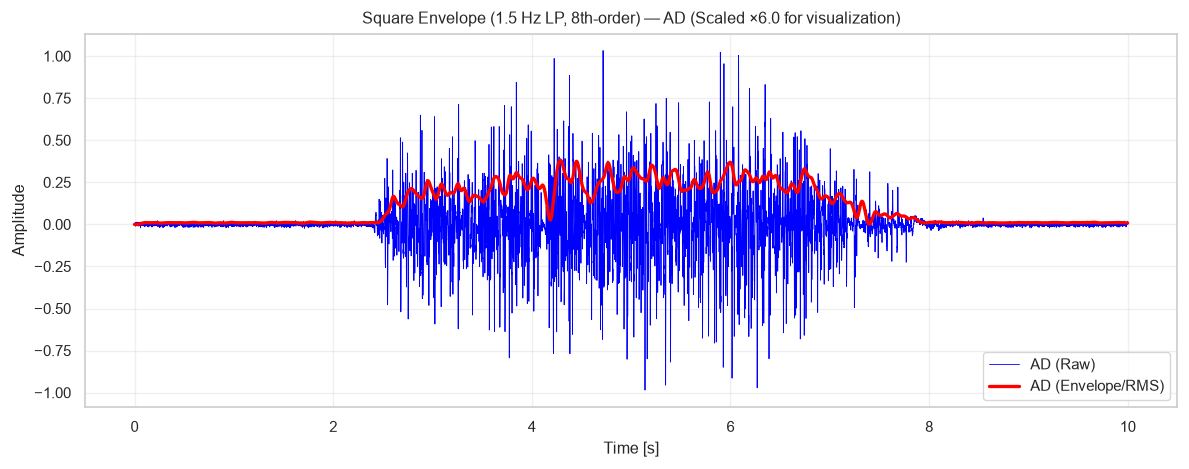

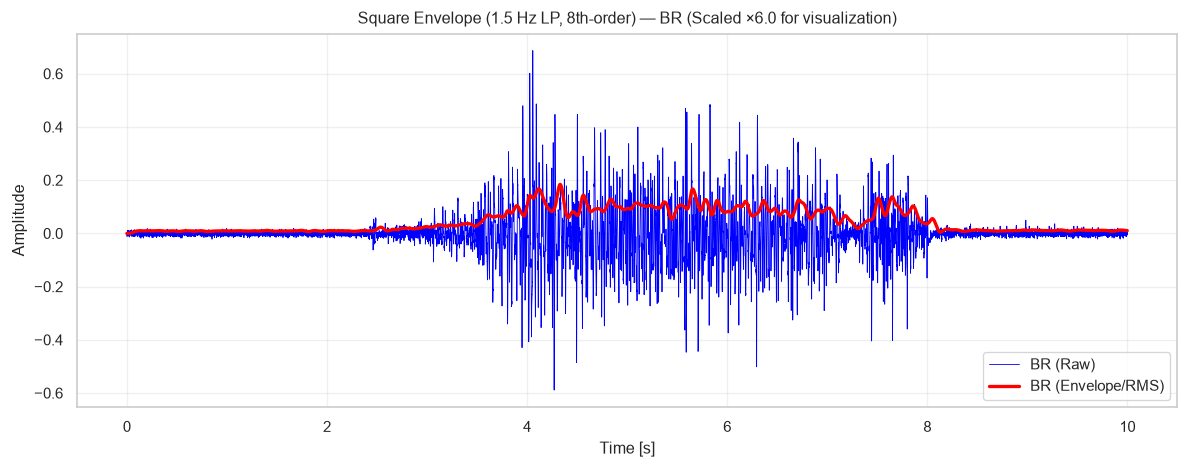

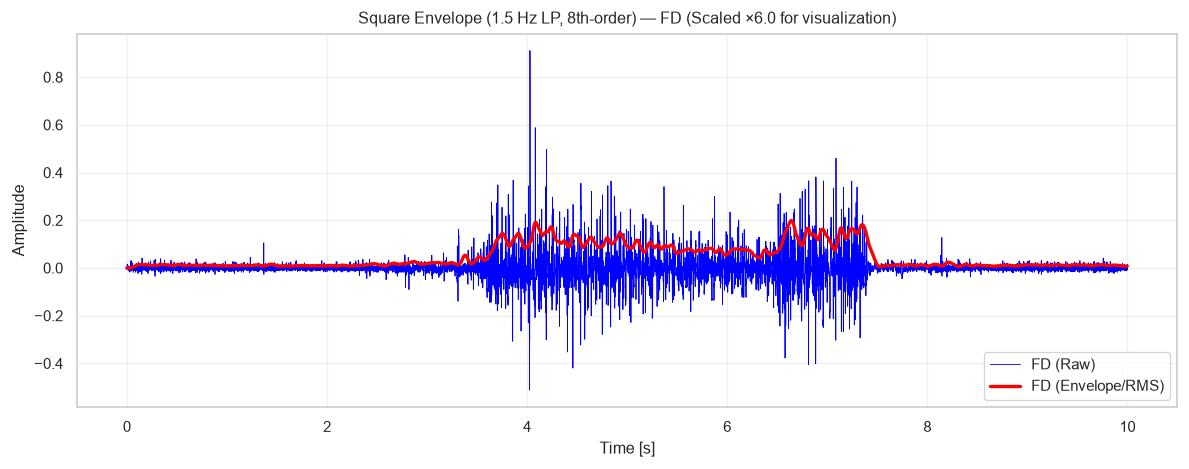

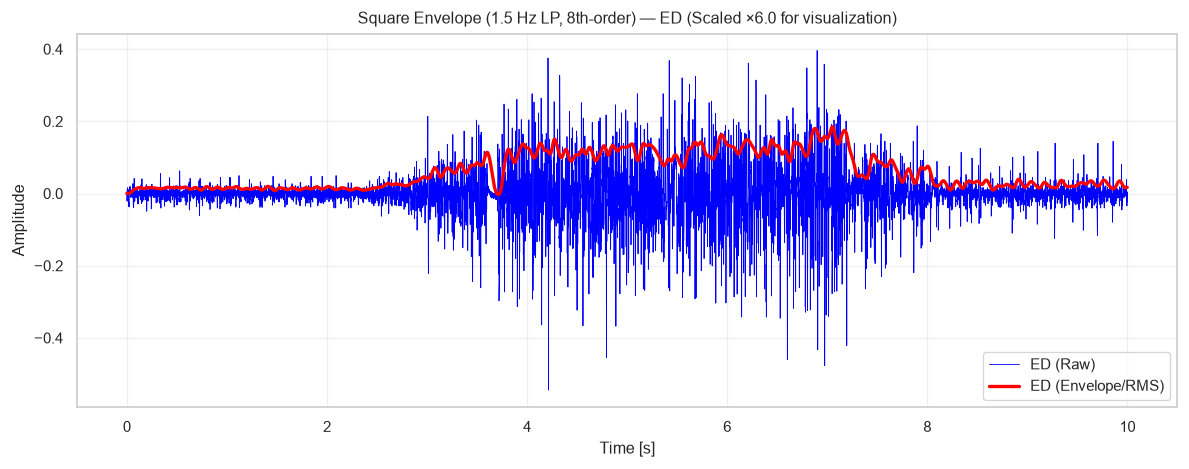

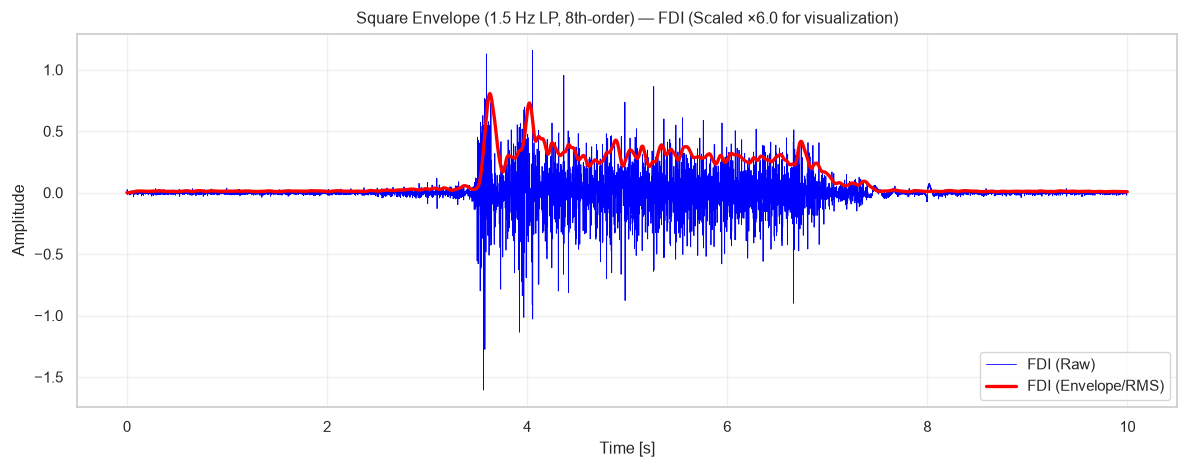

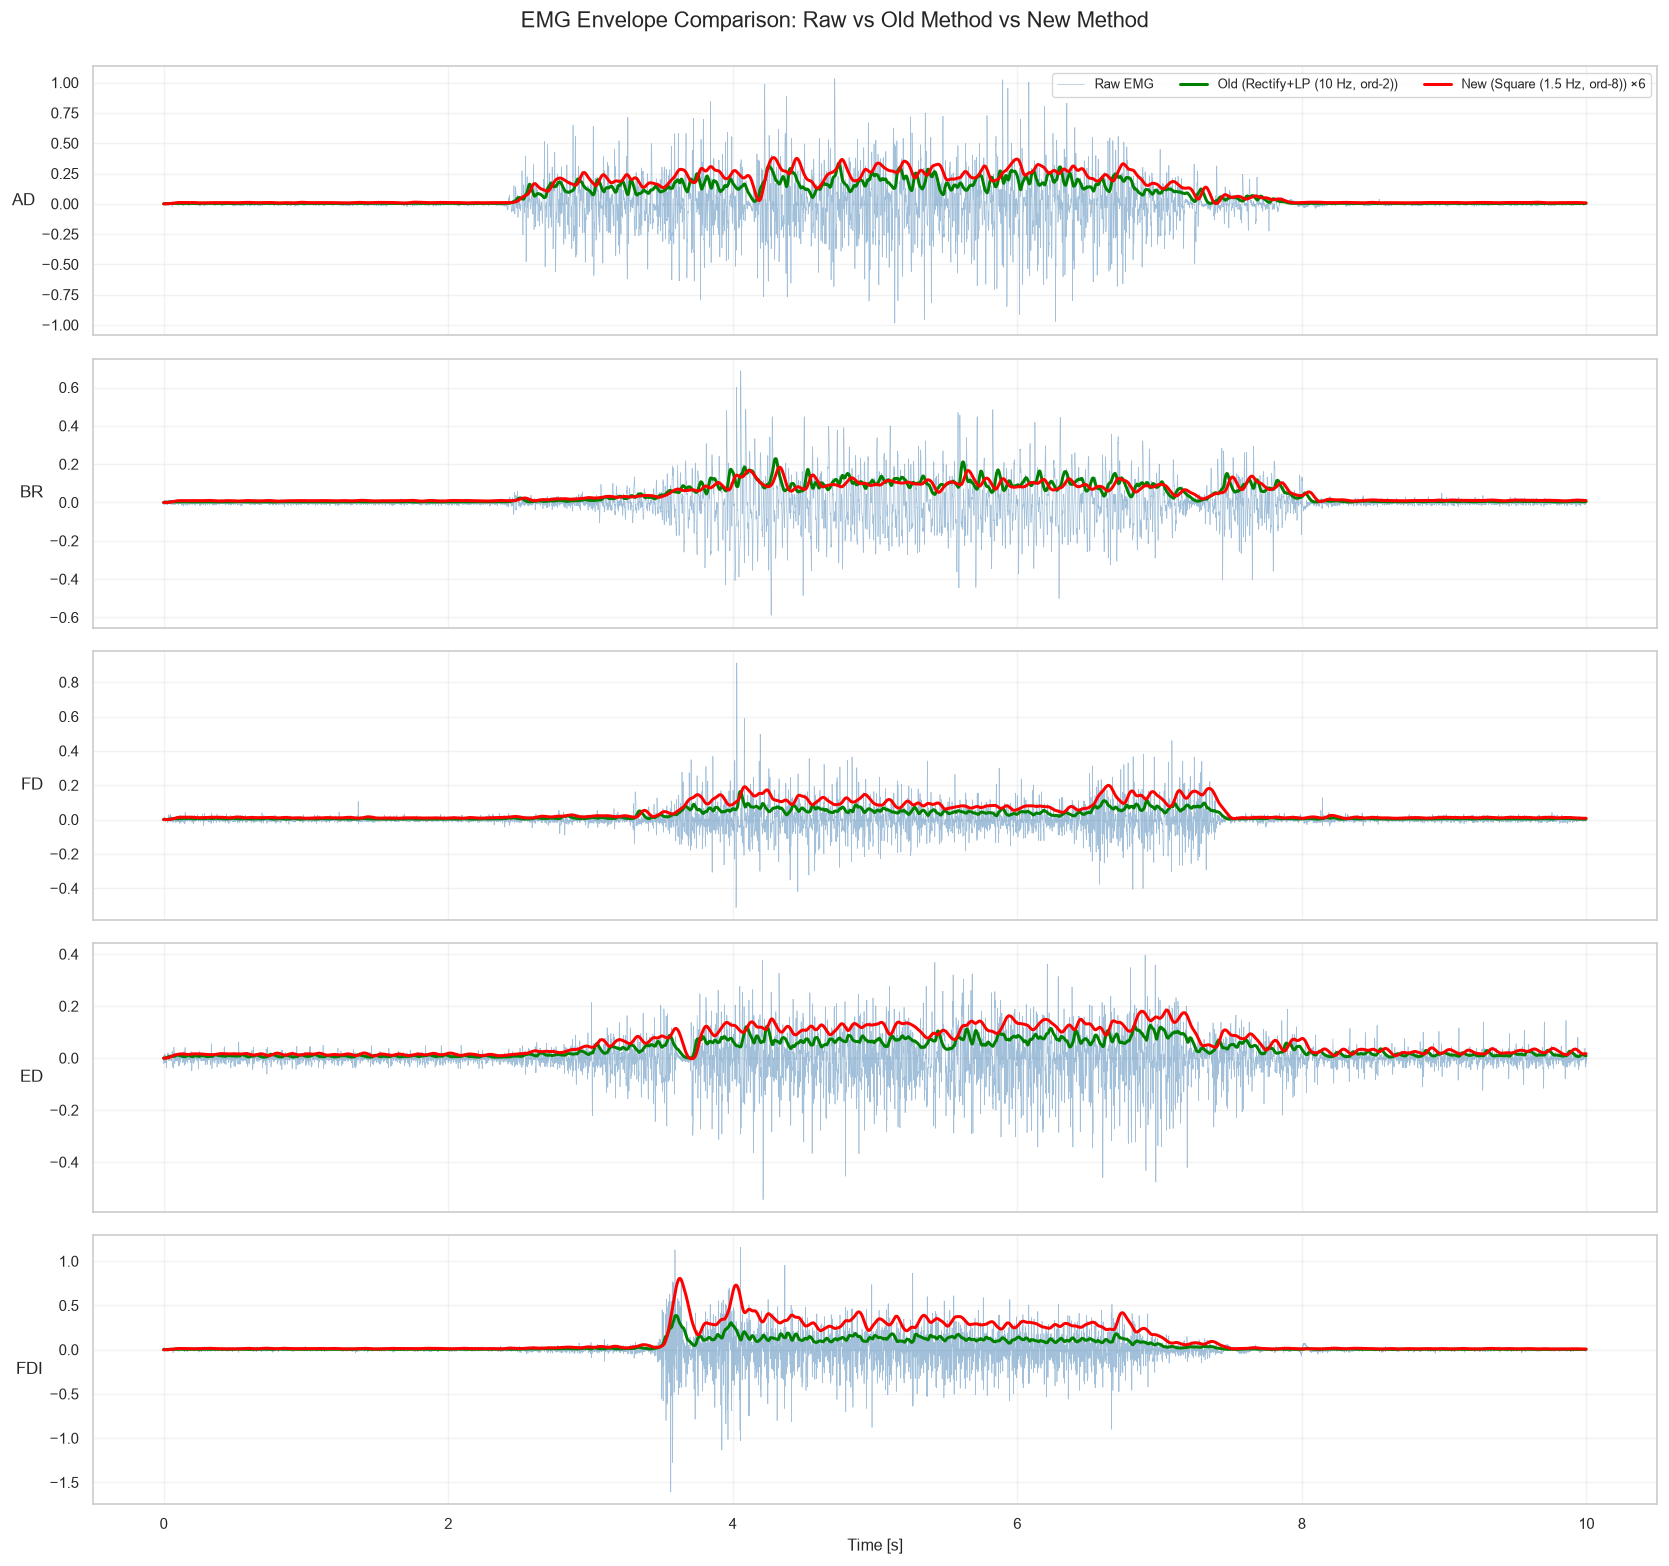

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from main.dataloader import load_hs, short_emg_label
from main.preprocessing_emg_kin import preprocess_emg_from_config
from main.plots import plot_emg_envelope_overlay, plot_emg_method_comparison_grid

# 1. Load the continuous series dictionary
data_path = "data/way-eeg/raw/P1/HS_P1_S4.mat"  # Adjust as needed
hs_data = load_hs(data_path)
emg_raw = hs_data["emg"]
fs_raw  = float(hs_data["fs_emg"])
fs_env  = 500.0   # Standard downsampled rate

# true channel order, read from the file that is plotted (AD, BR, FD, ED, FDI)
MUSCLE_NAMES = [short_emg_label(n) for n in hs_data["emg_names"]]

# 2. Old method baseline (Rectify + 10 Hz LP, 2nd-order)
cfg_old = {
    "bp_low": 30.0, "bp_high": 300.0,
    "lp_cutoff": 10.0, "lp_order": 2,
    "use_tkeo": False,
}
emg_old = preprocess_emg_from_config(emg_raw, fs=fs_raw, cfg=cfg_old)

# 3. New method — square-like bursts (Rectify + 1.5 Hz LP, 8th-order brick-wall)
cfg_new = {
    "bp_low": 30.0, "bp_high": 300.0,
    "lp_cutoff": 8.0, "lp_order": 4,          # ← matches CONFIG
    "use_tkeo": True,
}
emg_square = preprocess_emg_from_config(emg_raw, fs=fs_raw, cfg=cfg_new)

# ── Slice a window ────────────────────────────────────────────────────────────
start_sec, end_sec = 0, 10

start_raw, end_raw = int(start_sec * fs_raw), int(end_sec * fs_raw)
start_env, end_env = int(start_sec * fs_env), int(end_sec * fs_env)

emg_raw_slice    = emg_raw[start_raw:end_raw]
emg_old_slice    = emg_old[start_env:end_env]
emg_square_slice = emg_square[start_env:end_env]

empirical_scale_factor = 6.0   # cosmetic amplitude match for overlay

# ── 5A. Per-muscle overlay (raw + new square envelope) ───────────────────────
emg_square_scaled = emg_square_slice * empirical_scale_factor

for ch in range(emg_raw_slice.shape[1]):
    name = MUSCLE_NAMES[ch] if ch < len(MUSCLE_NAMES) else f"Ch {ch + 1}"
    fig = plot_emg_envelope_overlay(
        raw_emg=emg_raw_slice,
        env_emg=emg_square_scaled,
        fs_raw=fs_raw,
        fs_env=fs_env,
        channel_idx=ch,
        channel_name=name,
        title=f"Square Envelope (1.5 Hz LP, 8th-order) — {name} "
              f"(Scaled ×{empirical_scale_factor} for visualization)",
    )
    plt.show()

# ── 5B. Comparison grid: Old (10 Hz) vs New (1.5 Hz square) ─────────────────
fig_combined = plot_emg_method_comparison_grid(
    raw_emg=emg_raw_slice,
    env_old=emg_old_slice,
    env_new=emg_square_slice,
    fs_raw=fs_raw,
    fs_env=fs_env,
    muscle_names=MUSCLE_NAMES,
    new_method_label="Square (1.5 Hz, ord-8)",
    old_method_label="Rectify+LP (10 Hz, ord-2)",
    new_scale_factor=empirical_scale_factor,
    start_sec=start_sec,
)
plt.show()

Old: 39 cached columns → 36 model features
New: 26 cached columns → 24 model features


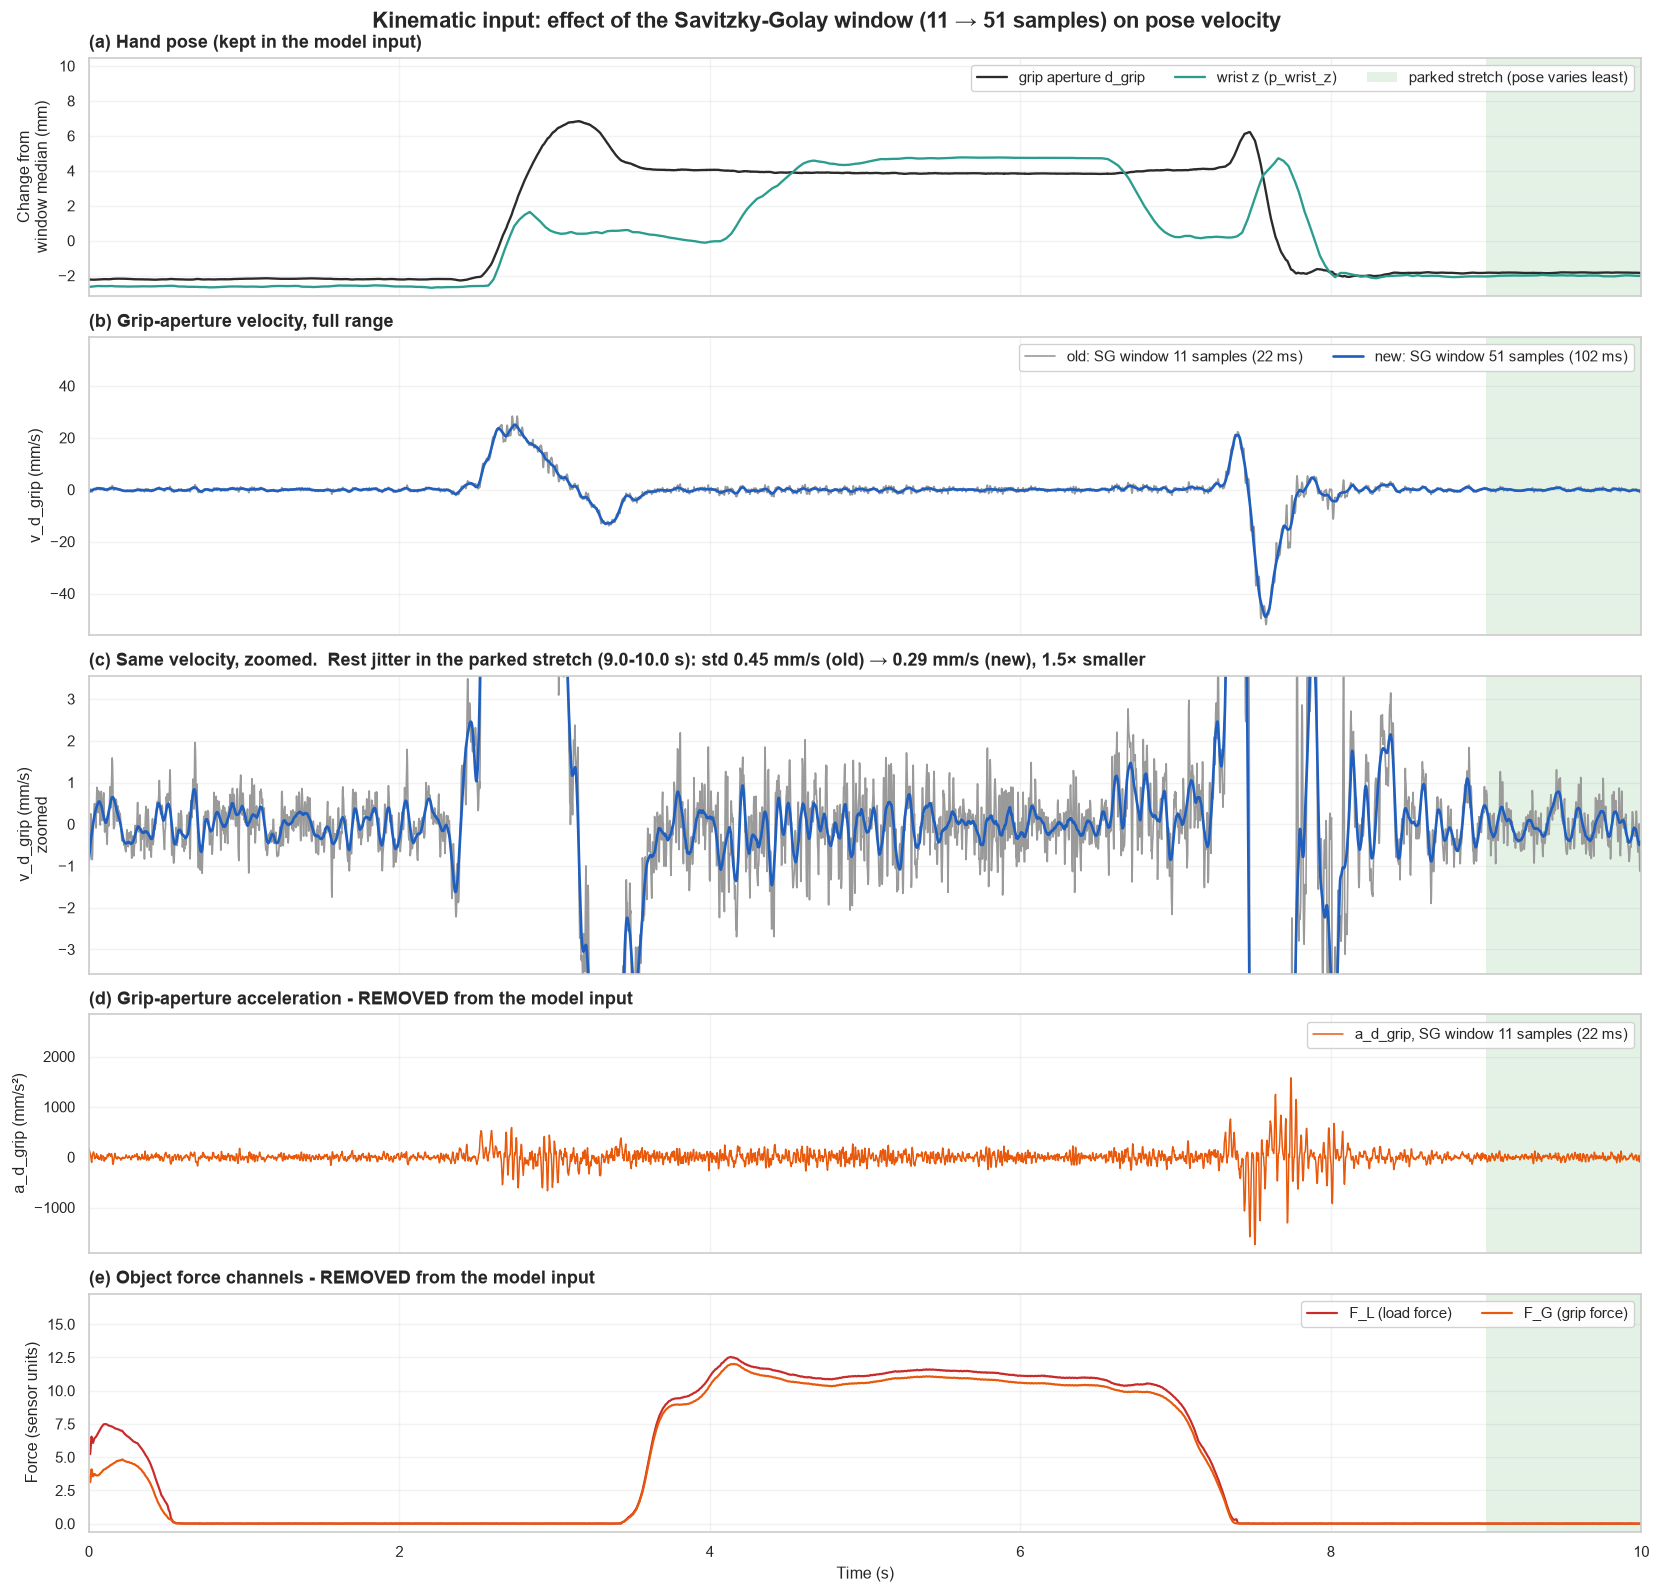

Rest jitter of v_d_grip (9.0-10.0 s): std 0.45 → 0.29 mm/s (1.5× smaller)

Model kinematic input (24 features):
['p_wrist_x', 'p_wrist_y', 'p_wrist_z', 'p_index_x', 'p_index_y', 'p_index_z', 'p_thumb_x', 'p_thumb_y', 'p_thumb_z', 'd_grip', 'F_L_gated', 'F_G_gated', 'v_p_wrist_x', 'v_p_wrist_y', 'v_p_wrist_z', 'v_p_index_x', 'v_p_index_y', 'v_p_index_z', 'v_p_thumb_x', 'v_p_thumb_y', 'v_p_thumb_z', 'v_d_grip', 'v_F_L_gated', 'v_F_G_gated']


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from main.dataloader import load_hs
from main.preprocessing_emg_kin import preprocess_kinematics_from_config, kin_feature_names
from main.plots import plot_kin_smoothing_comparison

# 1. Load the continuous series dictionary
data_path = "data/way-eeg/raw/P1/HS_P1_S4.mat"  # Adjust as needed
hs_data = load_hs(data_path)
kin_raw = hs_data["kin"]            # (T, 36) raw kinematic signal
fs_kin  = float(hs_data["fs_kin"])  # 500 Hz

# 2. New method — hand pose + gated forces + their velocities, SG window 51, no acceleration (= CONFIG)
kin_cfg_new = CONFIG["preprocessing"]["kinematics"]

# 3. Old method baseline — pos + vel + acc, SG window 11, object forces kept
kin_cfg_old = dict(kin_cfg_new, include_acceleration=True, sg_window=11,
                   drop_indices=[12, 25, 38], gated_force=None)

def model_kin_input(kin, kin_cfg):
    """Raw kin → cached columns → columns the model sees (as prepare_batch drops them)."""
    cached = preprocess_kinematics_from_config(kin, fs_kin, kin_cfg)
    return np.delete(cached, kin_cfg["drop_indices"], axis=-1), cached.shape[1]

kin_old, n_cached_old = model_kin_input(kin_raw, kin_cfg_old)
kin_new, n_cached_new = model_kin_input(kin_raw, kin_cfg_new)
print(f"Old: {n_cached_old} cached columns → {kin_old.shape[1]} model features")
print(f"New: {n_cached_new} cached columns → {kin_new.shape[1]} model features")

# ── Slice a window ────────────────────────────────────────────────────────────
start_sec, end_sec = 0, 10

fig = plot_kin_smoothing_comparison(
    kin_raw,
    fs=fs_kin,
    sg_window_old=kin_cfg_old["sg_window"],
    sg_window_new=kin_cfg_new["sg_window"],
    sg_poly=kin_cfg_new["sg_poly"],
    start_sec=start_sec,
    end_sec=end_sec,
)
plt.show()

_j = fig.rest_jitter
print(f"Rest jitter of {_j['signal']} ({_j['rest_start_sec']:.1f}-{_j['rest_end_sec']:.1f} s): "
      f"std {_j['std_old']:.2f} → {_j['std_new']:.2f} {_j['unit']} ({_j['ratio']:.1f}× smaller)")

# Features that go into the model (follows CONFIG)
KIN_INPUT_NAMES = kin_feature_names(
    kin_cfg_new["include_velocity"], kin_cfg_new["include_acceleration"], kin_cfg_new["drop_indices"],
    gated_force=kin_cfg_new.get("gated_force"),
)
print(f"\nModel kinematic input ({len(KIN_INPUT_NAMES)} features):")
print(KIN_INPUT_NAMES)

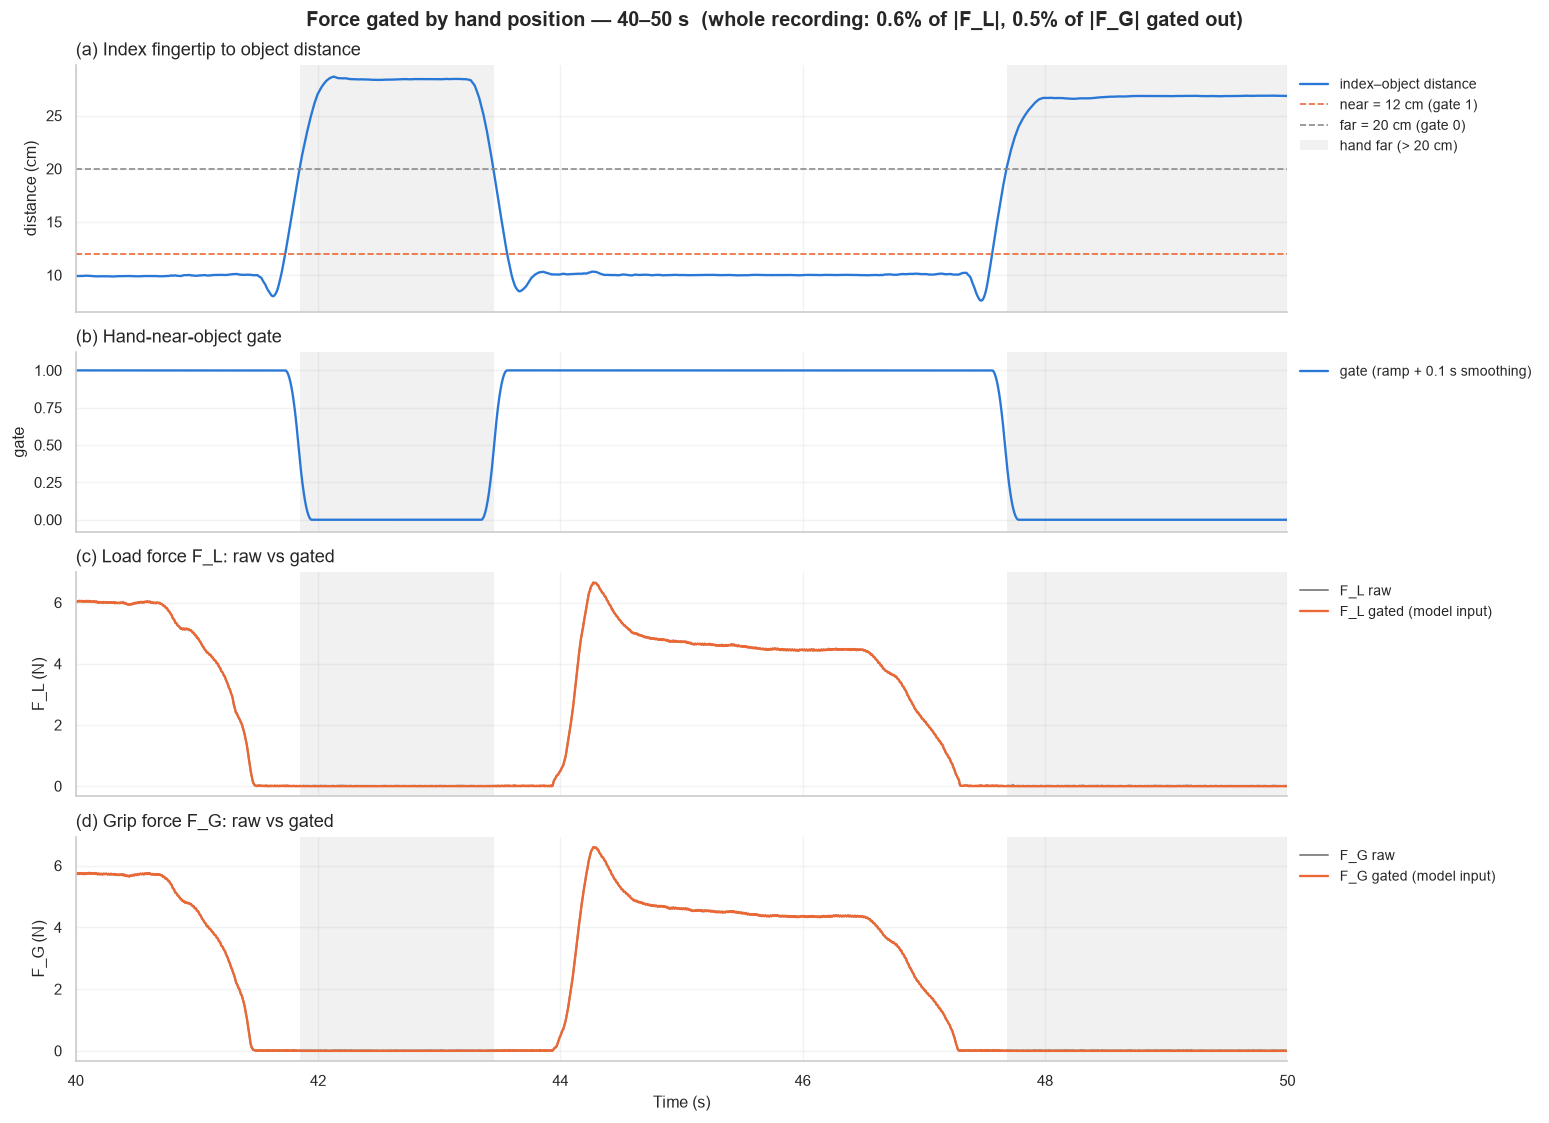

P1 S4: hand near 60% / far 36% of the time | gated out 0.6% of |F_L|, 0.5% of |F_G| | min gate while near = 1.00


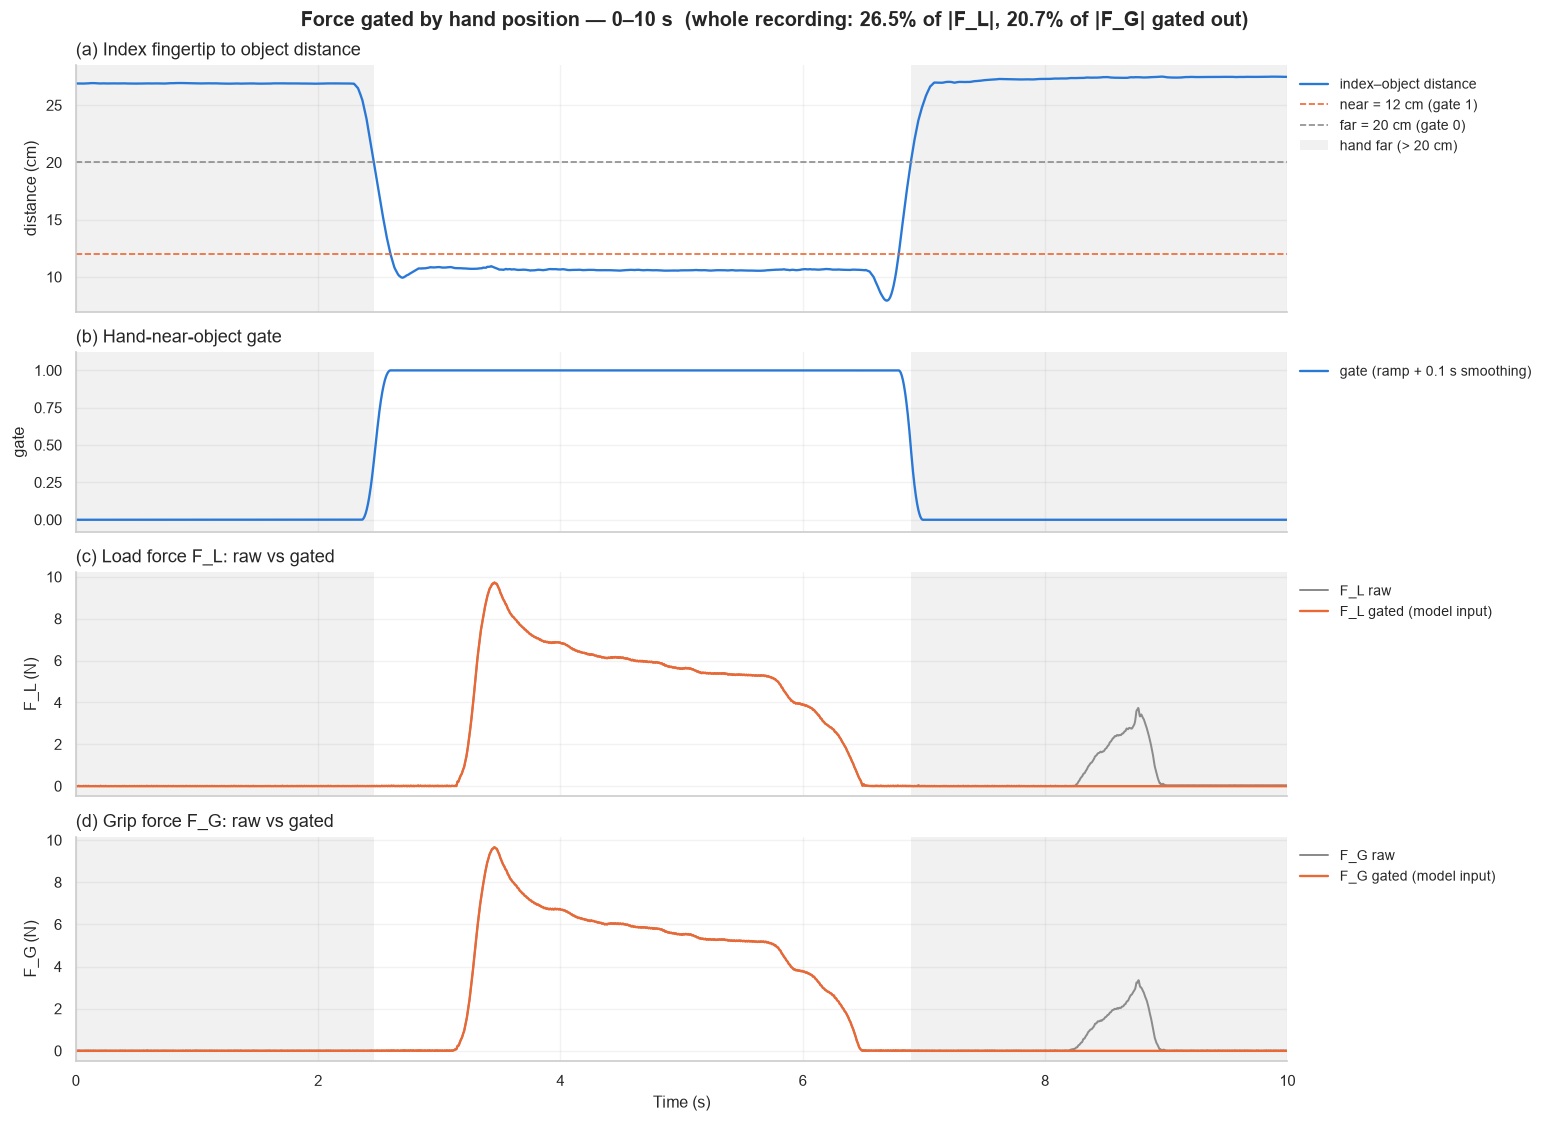

P1 S3: hand near 28% / far 70% of the time | gated out 26.5% of |F_L|, 20.7% of |F_G| | min gate while near = 1.00


In [6]:
# ── Hand-near-object force gate (sanity check: raw .mat only, no model) ─────────
# F_L / F_G are model inputs again, but only while the index fingertip is near the
# object (CONFIG preprocessing.kinematics.gated_force). When the hand is parked,
# someone else loading the object between trials no longer reaches the model.
# Panels: index-object distance with the near / far lines, the gate, raw vs gated forces.
import os
import matplotlib.pyplot as plt
from main.dataloader import load_hs
from main.plots import plot_kin_force_gate

_gate_cfg = CONFIG["preprocessing"]["kinematics"]["gated_force"]
os.makedirs("outputs/kin_gate", exist_ok=True)
for _series, (_t0, _t1) in ((4, (40, 50)), (3, (0, 10))):
    _hs = load_hs(f"data/way-eeg/raw/P1/HS_P1_S{_series}.mat")
    fig = plot_kin_force_gate(_hs["kin"], fs=float(_hs["fs_kin"]), **_gate_cfg,
                              start_sec=_t0, end_sec=_t1)
    fig.savefig(f"outputs/kin_gate/P1_S{_series}_{_t0}s-{_t1}s.png", dpi=130, bbox_inches="tight")
    plt.show()
    _s = fig.gate_stats
    print(f"P1 S{_series}: hand near {100 * _s['near_frac']:.0f}% / far {100 * _s['far_frac']:.0f}% of the time | "
          f"gated out {100 * _s['removed_frac_F_L']:.1f}% of |F_L|, {100 * _s['removed_frac_F_G']:.1f}% of |F_G| | "
          f"min gate while near = {_s['gate_min_near']:.2f}")


In [7]:
def make_preprocess_fn(cfg):
    eeg_cfg = cfg["preprocessing"]["eeg"]
    emg_cfg = cfg["preprocessing"]["emg"]
    kin_cfg = cfg["preprocessing"]["kinematics"]
    def preprocess_fn(series):
        series = dict(series)
        series["eeg"] = preprocess_eeg_from_config(
            series["eeg"],
            float(series["fs_eeg"]),
            eeg_cfg,
            channel_names=series.get("eeg_names"),
        )
        series["emg"] = preprocess_emg_from_config(
            series["emg"],
            float(series["fs_emg"]),
            emg_cfg,
        )
        series["kin"] = preprocess_kinematics_from_config(                                           
              series["kin"],                                                                           
              float(series["fs_kin"]),                                                                 
              kin_cfg,                                                                                 
        ) 
        return series

    return preprocess_fn


def resolve_participants(participant_spec):
    """Resolve participant spec to a list of int IDs.
    
    Accepts:
      "all"        -> [1, 2, ..., 12]
      "P3"         -> [3]
      3            -> [3]
      [1, 2, 3]   -> [1, 2, 3]
      ["P1", "P3"] -> [1, 3]
    """
    ALL_PARTICIPANTS = list(range(1, 13))
    if participant_spec == "all":
        return ALL_PARTICIPANTS
    if isinstance(participant_spec, (list, tuple)):
        return [int(str(p).replace("P", "")) for p in participant_spec]
    # single string like "P2" or int like 2
    return [int(str(participant_spec).replace("P", ""))]


def build_dataset_split(cfg, participants=None, split="train", root_dir=ROOT):
    """Build WAYEEGDataset for the given split.
    
    participants: list of int IDs, or None (uses cfg["data"]["participant"]).
    split: "train" | "val" | "test" | "all" | "stability"
    """
    data_cfg = cfg["data"]
    if participants is None:
        participants = resolve_participants(data_cfg["participant"])
    return WAYEEGDataset(
        data_dir=root_dir / data_cfg["data_root"],
        participants=participants,
        split=split,
        window_size=cfg["dataset"]["window_size"],
        stride=cfg["dataset"]["stride"],
        latency_shift_ms=0.0,
        preprocess_fn=make_preprocess_fn(cfg),
        cache_dir=root_dir / data_cfg["cache_dir"]
    )

# ─────────────────────────────────────────────────────────────────────────────
# Helper utilities (used by both the per-subject loop and LOSOCV loop below)
# ─────────────────────────────────────────────────────────────────────────────

def unique_series_arrays(ds):
    """Return deduplicated (eeg, kin, emg) arrays from a WAYEEGDataset."""
    seen, eegs, kins, emgs = set(), [], [], []
    for eeg_all, kin_all, emg_all, _ in ds._windows:
        key = id(eeg_all)
        if key in seen:
            continue
        seen.add(key)
        eegs.append(eeg_all)
        kins.append(kin_all)
        emgs.append(emg_all)
    return eegs, kins, emgs


def local_prepare_batch_factory(emg_mean, emg_std, kin_mean, kin_std, device,
                                drop_kin_indices=None):
    """Return a per-subject prepare_batch closure with frozen normalization stats."""
    def prepare_batch(eeg, kin, emg):
        eeg = eeg.to(device, non_blocking=True)
        kin = kin.to(device, non_blocking=True)
        emg = emg.to(device, non_blocking=True)
        kin_norm = (kin - kin_mean) / kin_std
        if drop_kin_indices is not None:
            keep_idx = [i for i in range(kin_norm.shape[-1]) if i not in drop_kin_indices]
            kin_norm = kin_norm[..., keep_idx]
        emg_norm = (emg - emg_mean) / emg_std
        return {"eeg": eeg, "kin": kin_norm}, emg_norm
    return prepare_batch


# ─────────────────────────────────────────────────────────────────────────────
# SINGLE-STAGE TRAINING ROUTINE (used by the per-subject loop and LOSOCV below)
# ─────────────────────────────────────────────────────────────────────────────
def train_single_stage(cfg, subj, eeg_dim, kin_dim, edge_prior,
                       train_loader, val_loader, prepare_batch, loss_fn, device):
    """Train the full KG-GT model jointly in ONE stage (no Transformer-only
    pre-training, nothing frozen).

    Hyper-parameters: lr / epochs / early_stop_patience from
    cfg["training"]["single_stage"]; optimizer, scheduler (cosine), warmup_epochs,
    transformer_lr_scale, grad clipping, AMP and grad accumulation from the shared
    cfg["training"] keys.
    Early stopping and best.pt use the SMOOTHED validation loss (mean of the last 5
    epochs' val losses, main/training.py): best.pt = the epoch at which that moving
    average was lowest; patience = epochs without a new smoothed best.
    Checkpoints: {cfg["training"]["checkpoint_dir"]}/{subj}/ (last.pt + best.pt);
    an interrupted run resumes from last.pt.

    Returns (end_of_training_model, best_model, TrainResult, ckpt_dir).
    """
    tr = cfg["training"]
    ss = tr["single_stage"]
    ckpt_dir = str(Path(tr["checkpoint_dir"]) / subj)
    # never write into the two-stage notebook's folders
    assert "checkpoints_main" not in Path(ckpt_dir).as_posix(), ckpt_dir

    model = build_kg_gt_from_config(
        cfg, input_dim=eeg_dim, kin_dim=kin_dim, edge_prior=edge_prior,
    ).to(device)
    for p in model.parameters():          # everything trainable from the start
        p.requires_grad = True
    n_all = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert n_trainable == n_all

    tc = TrainConfig.from_config(tr, max_epochs=ss["epochs"], lr=ss["lr"])
    tc.checkpoint_dir = ckpt_dir
    # single-stage patience (the shared early_stop_patience stays for other uses)
    tc.early_stop_patience = ss.get("early_stop_patience", tc.early_stop_patience)
    print(f"  Trainable parameters : {n_trainable:,} / {n_all:,}")
    print(f"  Optimizer / schedule : {tc.optimizer} | {tc.scheduler} | warmup {tc.warmup_epochs} ep "
          f"| lr {tc.lr:.1e} (encoder x{tc.transformer_lr_scale}) | max {tc.max_epochs} ep "
          f"| early-stop patience {tc.early_stop_patience}")
    print(f"  Checkpoints          : {ckpt_dir}")

    result = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        prepare_batch=prepare_batch,
        loss_fn=loss_fn,
        device=device,
        cfg=tc,
        resume=True,
    )

    # ── Load BEST checkpoint from disk into a clean model copy ────────────
    best = copy.deepcopy(model)
    best_path = Path(ckpt_dir) / "best.pt"
    if best_path.exists():
        load_checkpoint(str(best_path), best, device)
        print(f"  Loaded best checkpoint: {best_path}")
    else:
        print(f"  [WARNING] best.pt not found at {best_path}; using end-of-training weights.")
    best.eval()
    return model, best, result, ckpt_dir


In [8]:
# ============================================================================
# PER-SUBJECT PRE-PROCESSING LOOP
# ============================================================================
# This cell runs BEFORE training.  For each subject it:
#   1. Builds train / val / test WAYEEGDatasets  (uses cache_dir → loads fast
#      on second run because the dataset caches preprocessed arrays to disk)
#      Split is per participant and condition-stratified (from P{p}_AllLifts.mat):
#        test  = later W + later B of series 1-6              -> {W, B}
#        val   = series 9                                     -> {W}
#        train = earlier W of 1-6, S7, S8, both S, earlier B  -> {3W, 2S, 1B}
#      (W = weight varies, S = surface varies, B = both vary)
#   2. Computes per-subject normalization stats (emg_mean/std, kin_mean/std)
#   3. Builds the prepare_batch closure
#   4. Stores everything in `subject_data[f"P{p_id}"]`
#
# Edit `subject_list` ↓ to choose which subjects to process.
# ─────────────────────────────────────────────────────────────────────────────
import gc, os, time
import numpy as np
import torch
from torch.utils.data import DataLoader
from main.losses import channel_weights_from_config
from main.dataloader import emg_channel_names

# ── USER CONFIG ───────────────────────────────────────────────────────────────
subject_list = [1,2,3,4,5,6,7,8,9,10,11,12]   # ← EDIT: list of participant IDs to process/train ,2,3,4,5,6,7,8,9,10,11,12

# ─────────────────────────────────────────────────────────────────────────────
subject_data = {}   # populated below; keyed by "P{id}"

for p_id in subject_list:
    _t0 = time.time()
    _subj = f"P{p_id}"
    print(f"\n{'='*70}")
    print(f"  PRE-PROCESSING SUBJECT {_subj}")
    print(f"{'='*70}")

    # ── 1. Per-subject config ──────────────────────────────────────────────
    _cfg = copy.deepcopy(notebook_cfg)
    _cfg["data"]["participant"] = p_id

    # ── 2. Build datasets (cached on disk → fast after first run) ─────────
    _train_ds = build_dataset_split(_cfg, participants=[p_id], split="train")
    _val_ds   = build_dataset_split(_cfg, participants=[p_id], split="val")
    _test_ds  = build_dataset_split(_cfg, participants=[p_id], split="test")

    print(f"  Train windows : {len(_train_ds)}")
    print(f"  Val   windows : {len(_val_ds)}")
    print(f"  Test  windows : {len(_test_ds)}")
    print(describe_split(p_id, ROOT / _cfg["data"]["data_root"]))

    # ── 3. Compute normalization stats from training data ──────────────────
    _train_eegs, _train_kins, _train_emgs = unique_series_arrays(_train_ds)

    _kin_all = np.concatenate(_train_kins, axis=0)
    _emg_all = np.concatenate(_train_emgs, axis=0)

    _emg_mean = torch.tensor(_emg_all.mean(axis=0), dtype=torch.float32, device=device)
    _emg_std  = torch.tensor(_emg_all.std(axis=0),  dtype=torch.float32, device=device)
    _kin_mean = torch.tensor(_kin_all.mean(axis=0), dtype=torch.float32, device=device)
    _kin_std  = torch.tensor(_kin_all.std(axis=0),  dtype=torch.float32, device=device)

    _emg_std = torch.clamp(_emg_std, min=1e-6)
    _kin_std = torch.clamp(_kin_std, min=1e-6)

    # ── 4. Build prepare_batch closure (captures per-subject stats) ───────
    _drop_indices = _cfg["preprocessing"]["kinematics"]["drop_indices"]
    _prepare_batch = local_prepare_batch_factory(
        _emg_mean, _emg_std, _kin_mean, _kin_std, device,
        drop_kin_indices=_drop_indices,
    )

    # ── 5. Infer model input dimensions ───────────────────────────────────
    _sample_eeg, _sample_kin, _sample_emg = _train_ds[0]
    _dummy_eeg = torch.as_tensor(_sample_eeg).unsqueeze(0)
    _dummy_kin = torch.as_tensor(_sample_kin).unsqueeze(0)
    _dummy_emg = torch.as_tensor(_sample_emg).unsqueeze(0)
    _batch_in, _ = _prepare_batch(_dummy_eeg, _dummy_kin, _dummy_emg)
    _true_eeg_dim = _sample_eeg.shape[-1]
    _true_kin_dim = _batch_in["kin"].shape[-1]

    # ── 6. Edge prior + loss ───────────────────────────────────────────────
    _prior_np   = compute_muscle_edge_prior(_train_emgs)
    _edge_prior = torch.from_numpy(_prior_np)
    # Per-muscle loss weights (loss.channel_weights): "auto" → w_c ∝ 1/p95(|z_c|) of the
    # z-scored TRAINING targets (same mean/std as prepare_batch), normalised to mean 1.
    _emg_z = (_emg_all - _emg_mean.cpu().numpy()) / _emg_std.cpu().numpy()
    _channel_weights = channel_weights_from_config(_cfg["training"], _emg_z)
    del _emg_z
    if _channel_weights is not None:
        print("  Loss channel weights: " + ", ".join(
            f"{_n}={_w:.2f}" for _n, _w in zip(emg_channel_names(p_id, ROOT / _cfg["data"]["data_root"]), _channel_weights)))
    _loss_fn    = build_loss_from_config(_cfg["training"], channel_weights=_channel_weights)

    # ── 7. DataLoaders ────────────────────────────────────────────────────
    _bs = _cfg["training"]["batch_size"]
    _train_loader = DataLoader(_train_ds, batch_size=_bs, shuffle=True,
                               drop_last=True, pin_memory=True, num_workers=0)
    _val_loader   = DataLoader(_val_ds,   batch_size=_bs, shuffle=False,
                               pin_memory=True, num_workers=0)
    _test_loader  = DataLoader(_test_ds,  batch_size=_bs, shuffle=False,
                               pin_memory=True, num_workers=0)

    # ── 8. Store ──────────────────────────────────────────────────────────
    subject_data[_subj] = dict(
        cfg=_cfg,
        train_ds=_train_ds, val_ds=_val_ds, test_ds=_test_ds,
        train_loader=_train_loader, val_loader=_val_loader, test_loader=_test_loader,
        emg_mean=_emg_mean, emg_std=_emg_std,
        kin_mean=_kin_mean, kin_std=_kin_std,
        prepare_batch=_prepare_batch,
        edge_prior=_edge_prior, loss_fn=_loss_fn,
        true_eeg_dim=_true_eeg_dim, true_kin_dim=_true_kin_dim,
        train_emgs=_train_emgs,
        drop_indices=_drop_indices,
        channel_weights=_channel_weights,
    )

    elapsed = time.time() - _t0
    print(f"  [{_subj}] Pre-processing done in {elapsed:.1f}s")

print(f"\n✓  subject_data ready for {list(subject_data.keys())}")



  PRE-PROCESSING SUBJECT P1
  Train windows : 2188
  Val   windows : 231
  Test  windows : 653
P1 stratified split (W=weight, S=surface, B=both varies):
  train [S1:W, S2:S, S3:B, S6:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S4:W, S5:B]  lifts=62
  Loss channel weights: AD=1.07, BR=1.01, FD=0.96, ED=1.01, FDI=0.95
  [P1] Pre-processing done in 6.4s

  PRE-PROCESSING SUBJECT P2
  Train windows : 2704
  Val   windows : 294
  Test  windows : 715
P2 stratified split (W=weight, S=surface, B=both varies):
  train [S1:B, S2:S, S3:W, S4:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S5:W, S6:B]  lifts=62
  Loss channel weights: AD=1.10, BR=1.02, FD=0.98, ED=1.06, FDI=0.85
  [P2] Pre-processing done in 7.3s

  PRE-PROCESSING SUBJECT P3
  Train windows : 2043
  Val   windows : 223
  Test  windows : 624
P3 stratified split (W=weight, S=surface, B=both varies):
  train [S1:W, S2:B, S3:S, S5:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S4:B, S6:W]  lif

e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\env\Lib\site-packages\sklearn\decomposition\_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 8.4s.
  Train windows : 2095
  Val   windows : 247
  Test  windows : 620
P8 stratified split (W=weight, S=surface, B=both varies):
  train [S1:B, S2:S, S3:W, S4:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S5:W, S6:B]  lifts=62
  Loss channel weights: AD=1.00, BR=0.92, FD=1.19, ED=0.91, FDI=0.97
  [P8] Pre-processing done in 116.4s

  PRE-PROCESSING SUBJECT P9
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 6.3s.
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 13.8s.
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 6.7s.
Fit

e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\env\Lib\site-packages\sklearn\decomposition\_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 9.3s.
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 3.7s.
  Train windows : 2211
  Val   windows : 251
  Test  windows : 679
P9 stratified split (W=weight, S=surface, B=both varies):
  train [S1:W, S2:B, S3:S, S5:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S4:B, S6:W]  lifts=62
  Loss channel weights: AD=1.17, BR=1.02, FD=0.95, ED=1.03, FDI=0.83
  [P9] Pre-processing done in 120.9s

  PRE-PROCESSING SUBJECT P10
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 11.2s.
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 10.8s.
F

e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\env\Lib\site-packages\sklearn\decomposition\_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 7.8s.
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 11.9s.
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 8.7s.
  Train windows : 2324
  Val   windows : 273
  Test  windows : 713
P11 stratified split (W=weight, S=surface, B=both varies):
  train [S1:B, S2:W, S3:S, S5:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S4:W, S6:B]  lifts=62
  Loss channel weights: AD=1.05, BR=0.98, FD=1.04, ED=0.96, FDI=0.97
  [P11] Pre-processing done in 149.6s

  PRE-PROCESSING SUBJECT P12
Fitting ICA to data using 32 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 32 components
Fitting ICA took 9.4s.



  TRAINING P1  (fold 1/12)

--- SINGLE-STAGE: Full KG-GT joint training [P1] ---
  Mean-predictor baseline MSE: 3.6649
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P1
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 543.4 MB
  OK  VRAM reserved   : 3292.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Resumed from checkpoint: outputs\checkpoints_1stage\P1\last.pt
  Comple

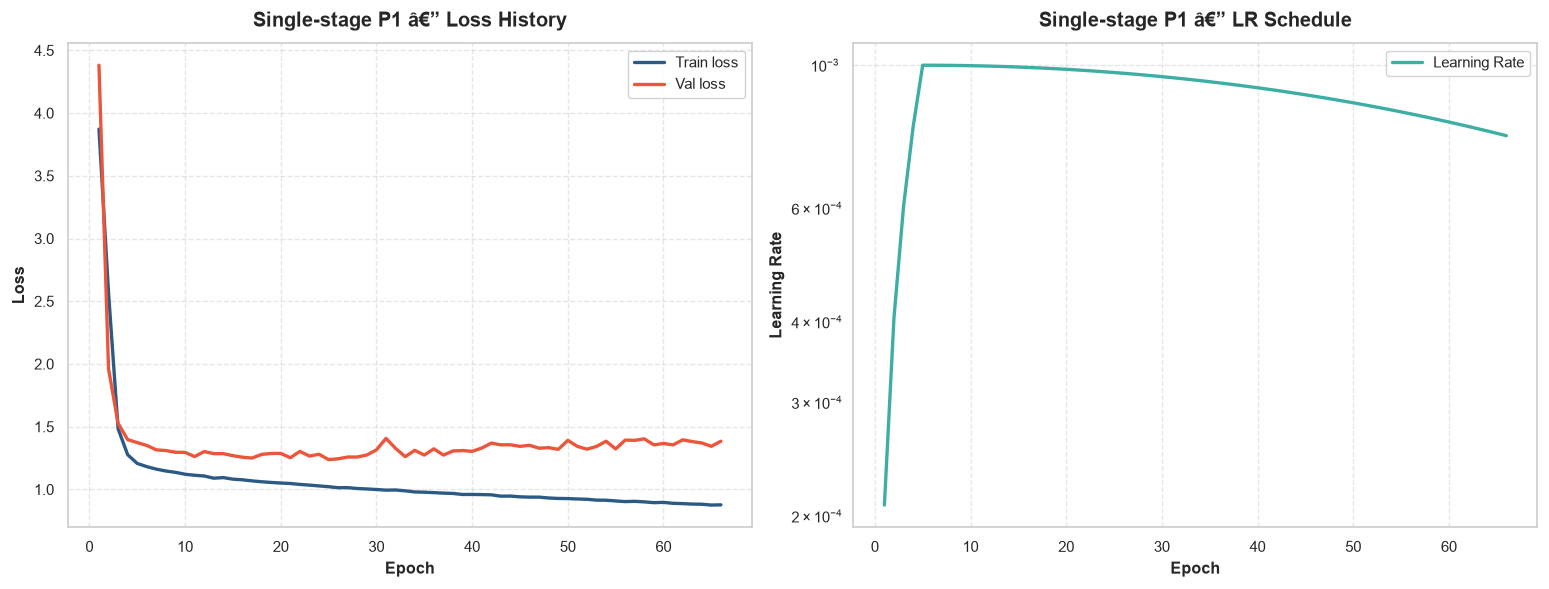


  [P1] Complete in 0.0 min

  TRAINING P2  (fold 2/12)

--- SINGLE-STAGE: Full KG-GT joint training [P2] ---
  Mean-predictor baseline MSE: 3.5739
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P2
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 550.5 MB
  OK  VRAM reserved   : 928.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Resumed from checkpoint: outputs\checkpoints

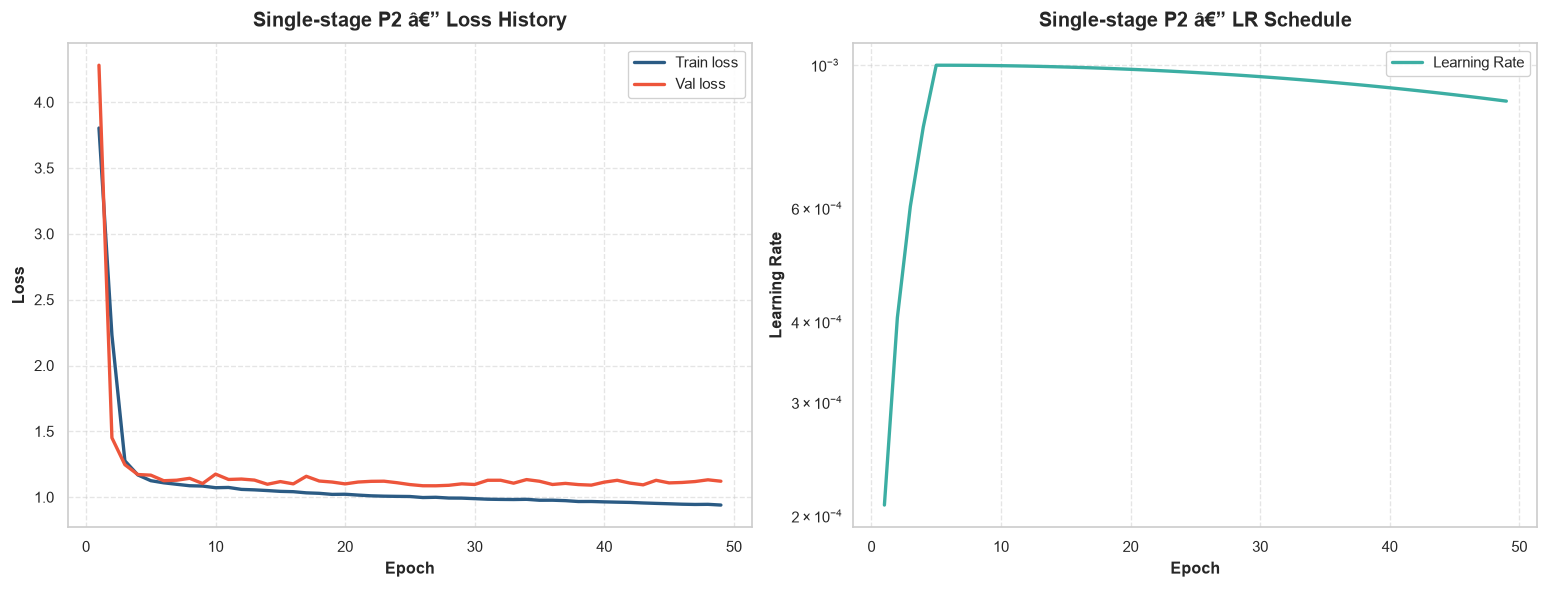


  [P2] Complete in 0.1 min

  TRAINING P3  (fold 3/12)

--- SINGLE-STAGE: Full KG-GT joint training [P3] ---
  Mean-predictor baseline MSE: 3.4263
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P3
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 557.6 MB
  OK  VRAM reserved   : 928.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Resumed from checkpoint: outputs\checkpoints

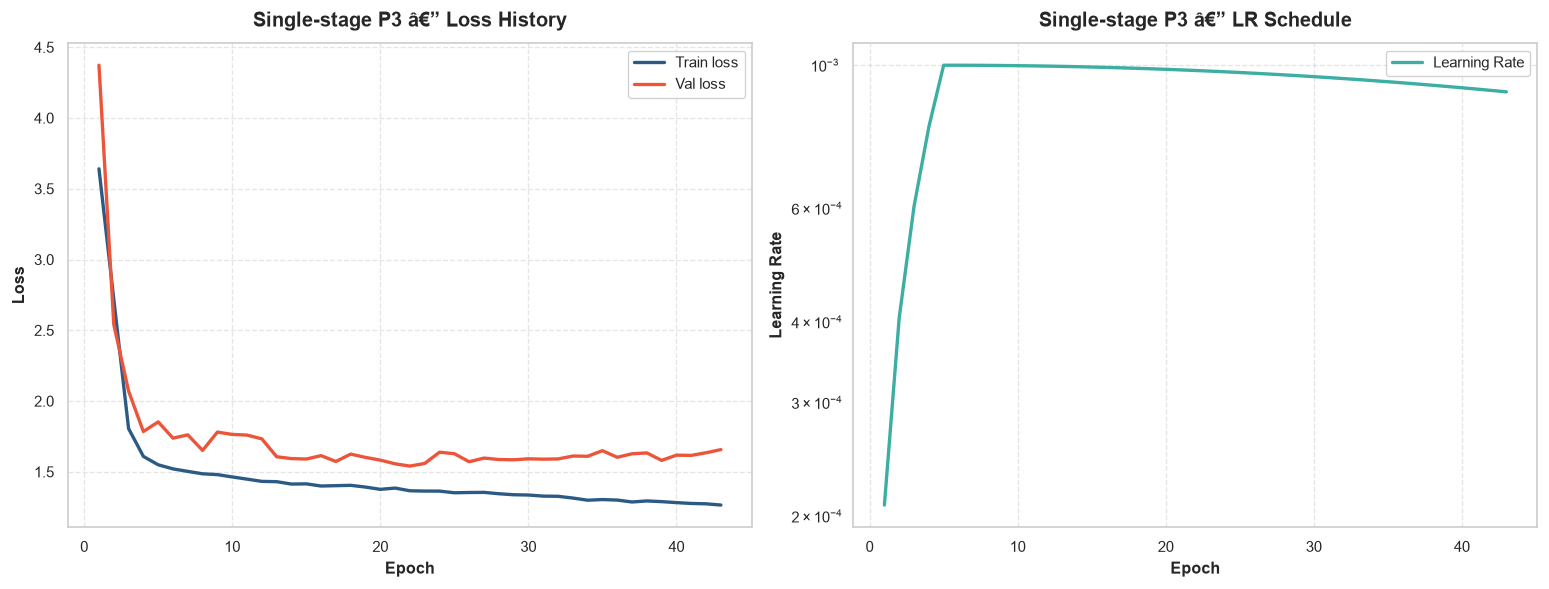


  [P3] Complete in 0.0 min

  TRAINING P4  (fold 4/12)

--- SINGLE-STAGE: Full KG-GT joint training [P4] ---
  Mean-predictor baseline MSE: 3.5440
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P4
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 565.0 MB
  OK  VRAM reserved   : 928.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Resumed from checkpoint: outputs\checkpoints

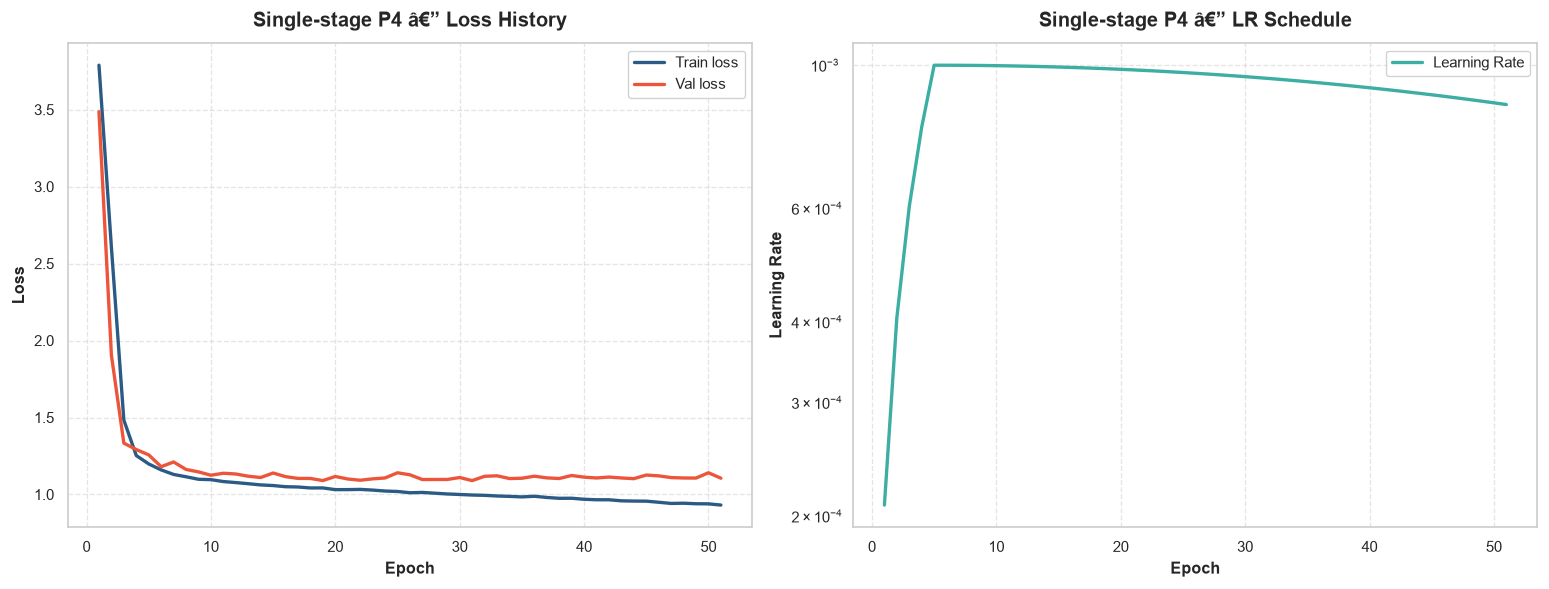


  [P4] Complete in 0.0 min

  TRAINING P5  (fold 5/12)

--- SINGLE-STAGE: Full KG-GT joint training [P5] ---
  Mean-predictor baseline MSE: 3.3726
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P5
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 572.1 MB
  OK  VRAM reserved   : 928.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Resumed from checkpoint: outputs\checkpoints

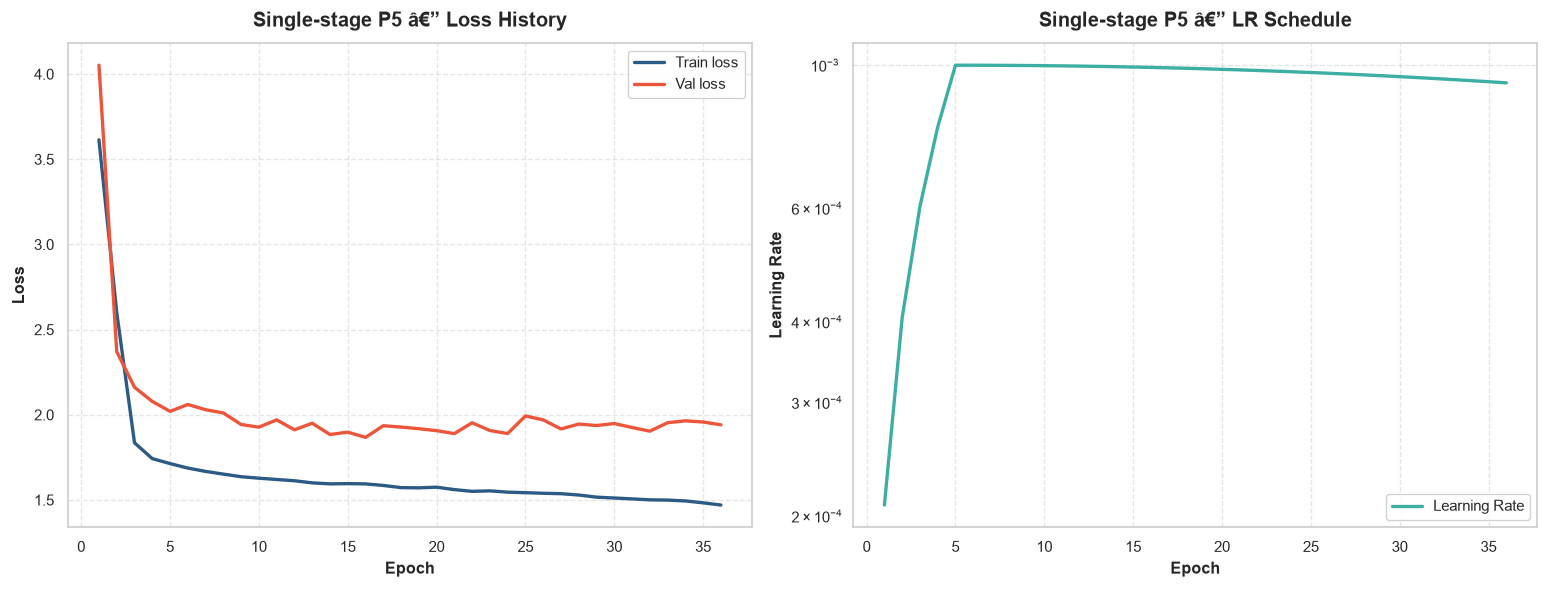


  [P5] Complete in 0.1 min

  TRAINING P6  (fold 6/12)

--- SINGLE-STAGE: Full KG-GT joint training [P6] ---
  Mean-predictor baseline MSE: 3.5796
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P6
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 579.1 MB
  OK  VRAM reserved   : 928.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Resumed from checkpoint: outputs\checkpoints

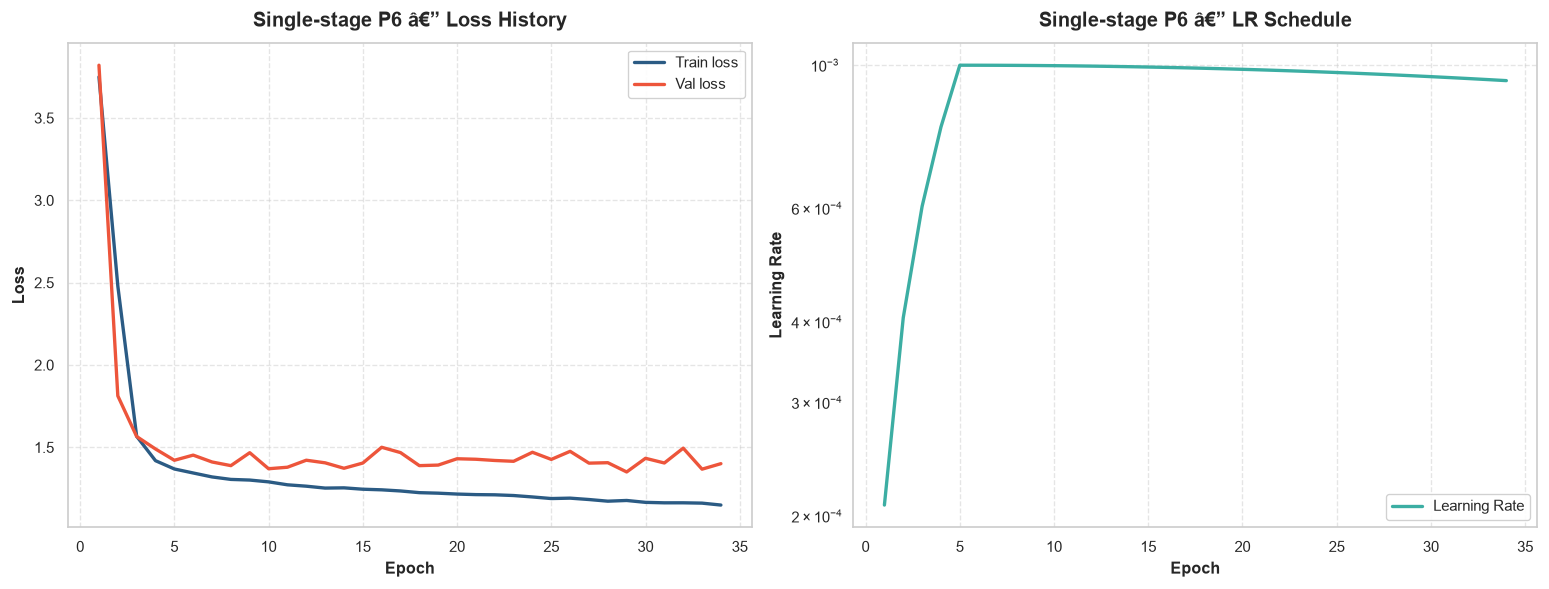


  [P6] Complete in 0.0 min

  TRAINING P7  (fold 7/12)

--- SINGLE-STAGE: Full KG-GT joint training [P7] ---
  Mean-predictor baseline MSE: 3.5613
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P7
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 586.7 MB
  OK  VRAM reserved   : 928.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Resumed from checkpoint: outputs\checkpoints

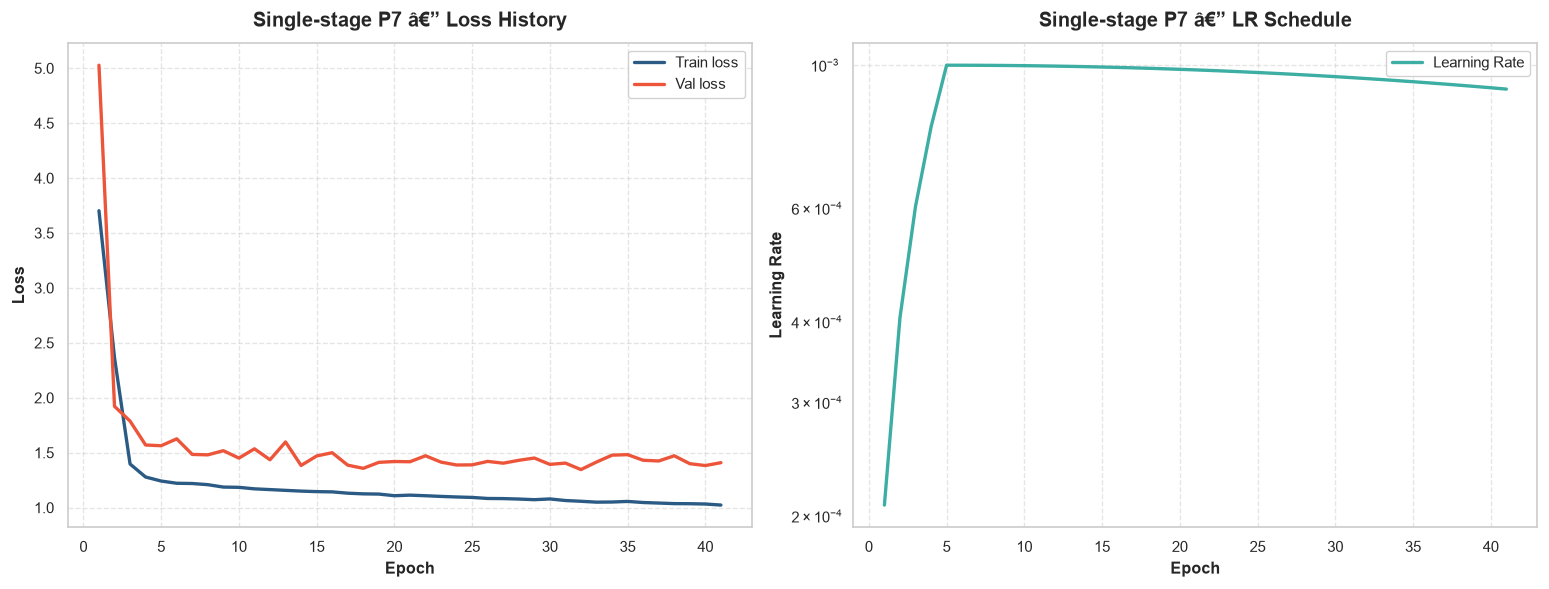


  [P7] Complete in 0.0 min

  TRAINING P8  (fold 8/12)

--- SINGLE-STAGE: Full KG-GT joint training [P8] ---
  Mean-predictor baseline MSE: 3.4200
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P8
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 593.8 MB
  OK  VRAM reserved   : 932.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Resumed from checkpoint: outputs\checkpoints

  Ep   22 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep   22 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   23 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep   23 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep   52 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep   52 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   53 [train]:   0%|          | 0/65 [00:00<?, ?batch/s]

  Ep   53 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 53 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.8328 (Epoch 33)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_1stage\P8
Metrics & Report saved: outputs\checkpoints_1stage\P8\metrics.json | outputs\checkpoints_1stage\P8\metrics.csv | outputs\checkpoints_1stage\P8\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_1stage\P8\best.pt  (best_val=1.8328)
  Loaded best checkpoint: outputs\checkpoints_1stage\P8\best.pt
  Single-stage final train loss : 1.3904
  Single-stage final val   loss : 1.8816
  Best val loss                 : 1.8328


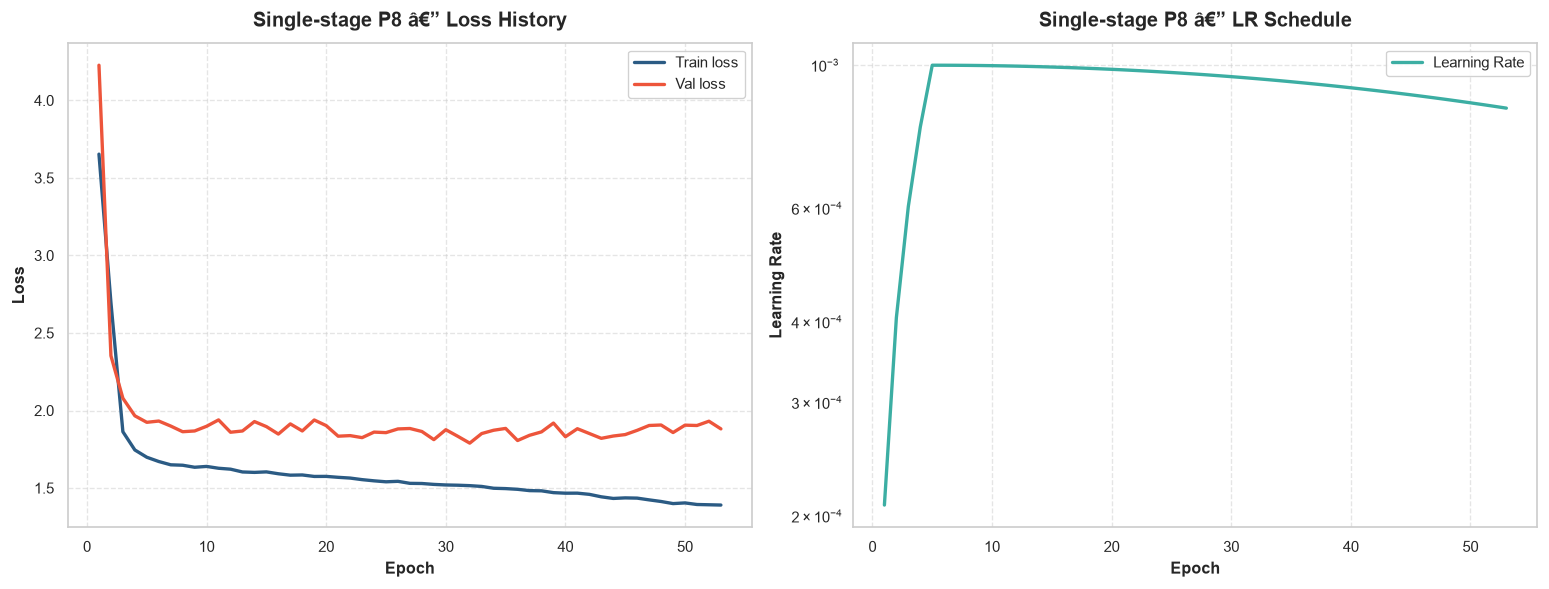


  [P8] Complete in 20.6 min

  TRAINING P9  (fold 9/12)

--- SINGLE-STAGE: Full KG-GT joint training [P9] ---
  Mean-predictor baseline MSE: 3.5815
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P9
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 959.4 MB
  OK  VRAM reserved   : 1452.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run  (checkpoint_d

  Ep    1 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep   34 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep   34 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   35 [train]:   0%|          | 0/69 [00:00<?, ?batch/s]

  Ep   35 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 35 (no val improvement for 20 epochs).

Training done.  Best val loss = 0.9310 (Epoch 15)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_1stage\P9
Metrics & Report saved: outputs\checkpoints_1stage\P9\metrics.json | outputs\checkpoints_1stage\P9\metrics.csv | outputs\checkpoints_1stage\P9\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_1stage\P9\best.pt  (best_val=0.9310)
  Loaded best checkpoint: outputs\checkpoints_1stage\P9\best.pt
  Single-stage final train loss : 0.9229
  Single-stage final val   loss : 0.9509
  Best val loss                 : 0.9310


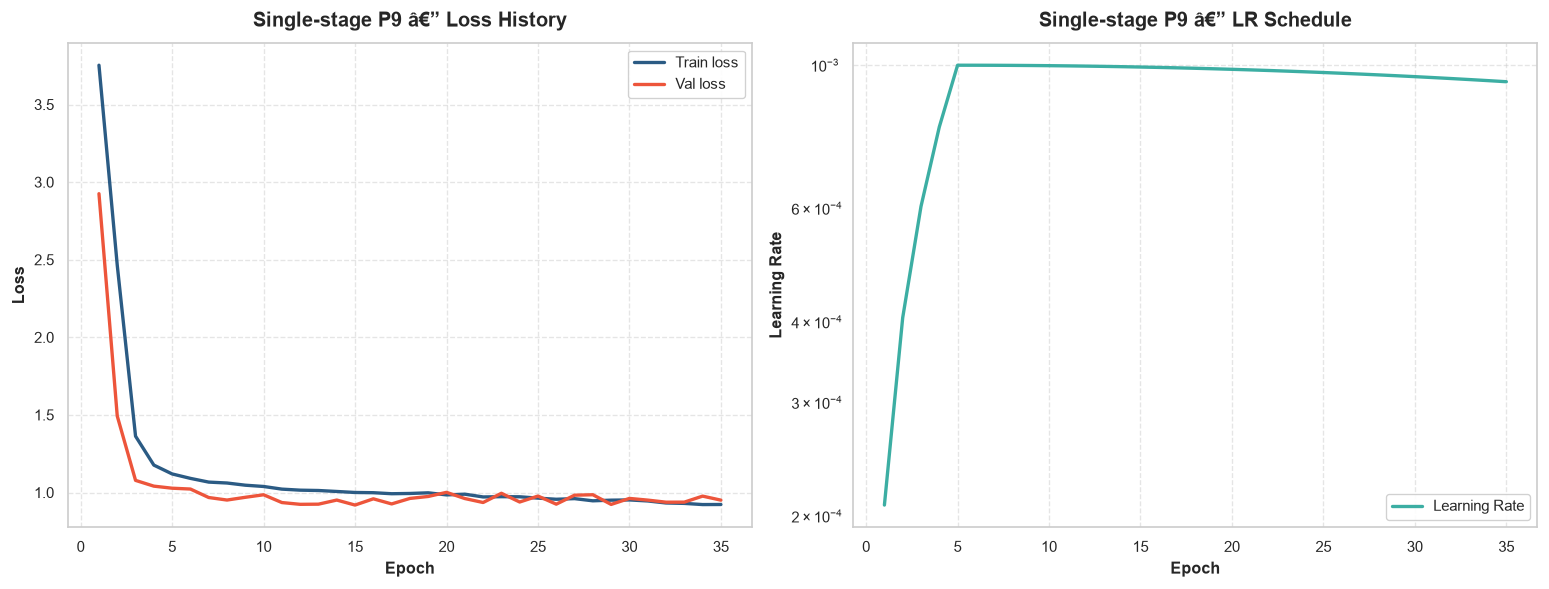


  [P9] Complete in 23.8 min

  TRAINING P10  (fold 10/12)

--- SINGLE-STAGE: Full KG-GT joint training [P10] ---
  Mean-predictor baseline MSE: 3.5540
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P10
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 1386.1 MB
  OK  VRAM reserved   : 2072.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run  (checkpo

  Ep    1 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

...

  Ep   51 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep   51 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

  Ep   52 [train]:   0%|          | 0/71 [00:00<?, ?batch/s]

  Ep   52 [val  ]:   0%|          | 0/8 [00:00<?, ?batch/s]

Early stop at epoch 52 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.6074 (Epoch 32)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_1stage\P10
Metrics & Report saved: outputs\checkpoints_1stage\P10\metrics.json | outputs\checkpoints_1stage\P10\metrics.csv | outputs\checkpoints_1stage\P10\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_1stage\P10\best.pt  (best_val=1.6074)
  Loaded best checkpoint: outputs\checkpoints_1stage\P10\best.pt
  Single-stage final train loss : 0.9773
  Single-stage final val   loss : 1.7410
  Best val loss                 : 1.6074


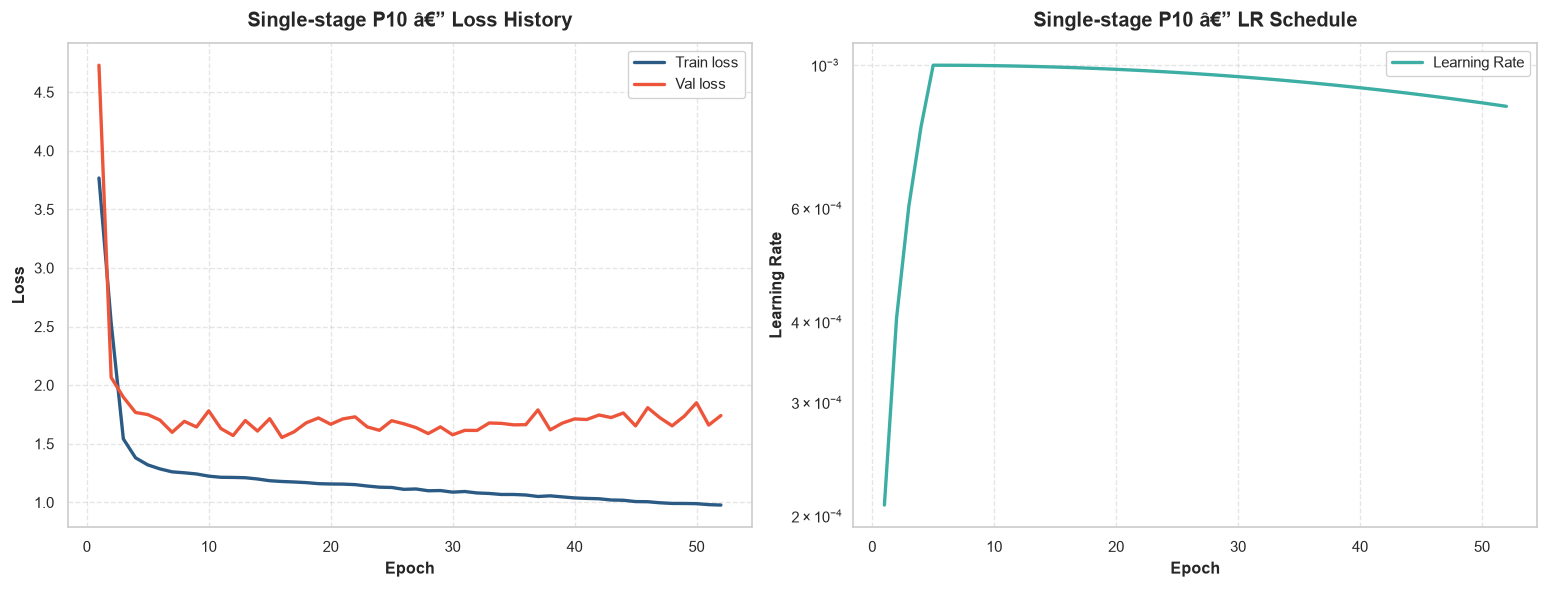


  [P10] Complete in 36.3 min

  TRAINING P11  (fold 11/12)

--- SINGLE-STAGE: Full KG-GT joint training [P11] ---
  Mean-predictor baseline MSE: 3.4558
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P11
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 1890.6 MB
  OK  VRAM reserved   : 2570.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run  (checkp

  Ep    1 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

...

  Ep   43 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   43 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

  Ep   44 [train]:   0%|          | 0/72 [00:00<?, ?batch/s]

  Ep   44 [val  ]:   0%|          | 0/9 [00:00<?, ?batch/s]

Early stop at epoch 44 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.2054 (Epoch 24)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_1stage\P11
Metrics & Report saved: outputs\checkpoints_1stage\P11\metrics.json | outputs\checkpoints_1stage\P11\metrics.csv | outputs\checkpoints_1stage\P11\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_1stage\P11\best.pt  (best_val=1.2054)
  Loaded best checkpoint: outputs\checkpoints_1stage\P11\best.pt
  Single-stage final train loss : 1.0085
  Single-stage final val   loss : 1.3032
  Best val loss                 : 1.2054


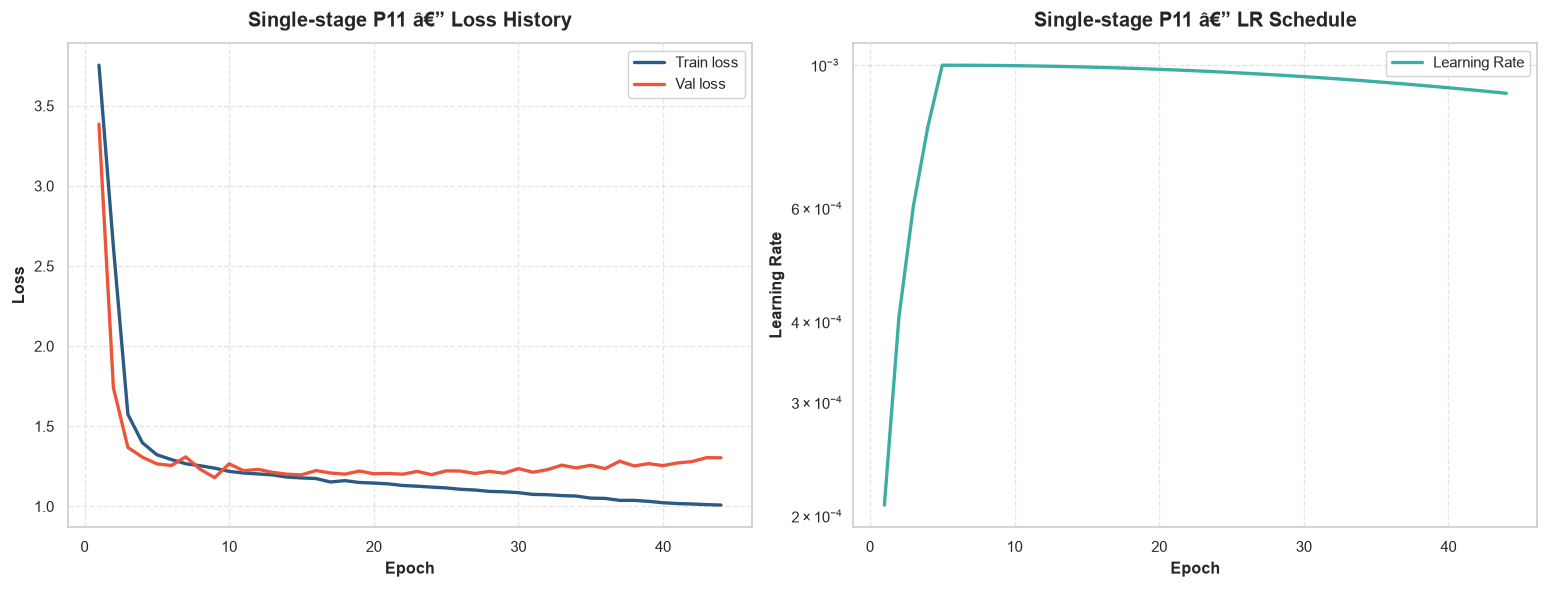


  [P11] Complete in 31.2 min

  TRAINING P12  (fold 12/12)

--- SINGLE-STAGE: Full KG-GT joint training [P12] ---
  Mean-predictor baseline MSE: 3.5026
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 20
  Checkpoints          : outputs\checkpoints_1stage\P12
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 2162.1 MB
  OK  VRAM reserved   : 2944.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Starting fresh training run  (checkp

  Ep    1 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep    1 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep    2 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep    2 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

...

  Ep   42 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep   42 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

  Ep   43 [train]:   0%|          | 0/76 [00:00<?, ?batch/s]

  Ep   43 [val  ]:   0%|          | 0/10 [00:00<?, ?batch/s]

Early stop at epoch 43 (no val improvement for 20 epochs).

Training done.  Best val loss = 1.3502 (Epoch 23)
Checkpoints saved to: E:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\outputs\checkpoints_1stage\P12
Metrics & Report saved: outputs\checkpoints_1stage\P12\metrics.json | outputs\checkpoints_1stage\P12\metrics.csv | outputs\checkpoints_1stage\P12\metrics_report.md

Loaded checkpoint <- outputs\checkpoints_1stage\P12\best.pt  (best_val=1.3502)
  Loaded best checkpoint: outputs\checkpoints_1stage\P12\best.pt
  Single-stage final train loss : 1.1756
  Single-stage final val   loss : 1.3957
  Best val loss                 : 1.3502


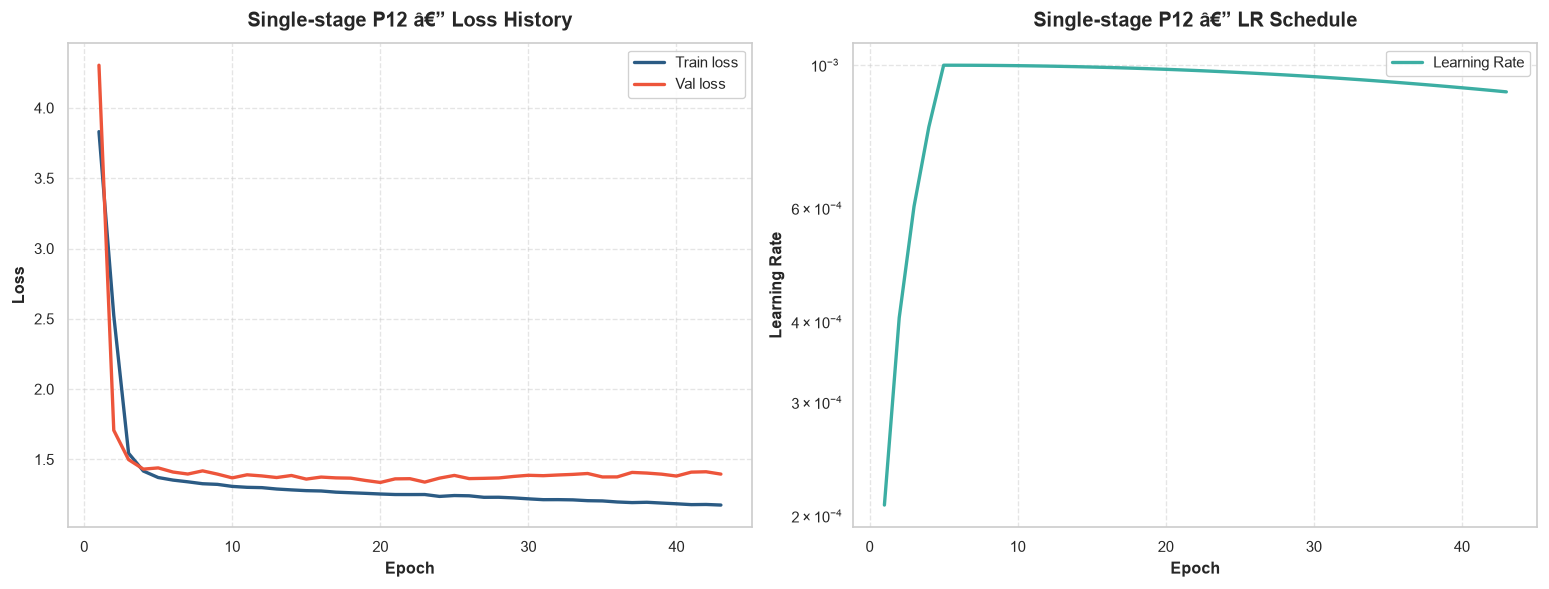


  [P12] Complete in 32.2 min

[!] Global scope updated with last subject (P12) variables.

  ALL SUBJECTS TRAINED (single stage): ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10', 'P11', 'P12']


In [10]:
# ============================================================================
# PER-SUBJECT TRAINING LOOP  (SINGLE STAGE — full KG-GT trained jointly)
# ============================================================================
# Iterates over subject_data (populated by the pre-processing loop above).
# For each subject the full KG-GT model (encoder + node projection + GAT +
# decoder + kin skip highway) is trained ONCE, from scratch, with every
# parameter trainable (see train_single_stage in the helper cell).
#
# Checkpoints are saved to:
#   outputs/checkpoints_1stage/{subject}/   (last.pt + best.pt, resumable)
#
# After the loop, the LAST subject's variables are exported to global scope
# so all downstream single-subject cells (evaluation, interpretability) work
# without modification.
#
# Results are collected in `per_subject_results` dict keyed by "P{id}".
# For compatibility with cells written for the two-stage notebook,
# stage1_model is None and result_stage1 / result_stage2 both hold the single
# training result (also available as result_single).
# ─────────────────────────────────────────────────────────────────────────────
from main.training import compute_mean_baseline_loss
from main.plots import plot_training_history
import gc, time
from pathlib import Path

per_subject_results = {}   # keyed by "P{id}"

for _fold_idx, (_subj, _sd) in enumerate(subject_data.items()):
    _t_fold = time.time()
    print(f"\n{'='*70}")
    print(f"  TRAINING {_subj}  (fold {_fold_idx + 1}/{len(subject_data)})")
    print(f"{'='*70}")

    _cfg          = _sd["cfg"]
    _train_loader = _sd["train_loader"]
    _val_loader   = _sd["val_loader"]
    _test_loader  = _sd["test_loader"]
    _train_ds     = _sd["train_ds"]
    _val_ds       = _sd["val_ds"]
    _test_ds      = _sd["test_ds"]
    _prepare_batch= _sd["prepare_batch"]
    _emg_mean     = _sd["emg_mean"]
    _emg_std      = _sd["emg_std"]
    _kin_mean     = _sd["kin_mean"]
    _kin_std      = _sd["kin_std"]
    _edge_prior   = _sd["edge_prior"]
    _loss_fn      = _sd["loss_fn"]
    _eeg_dim      = _sd["true_eeg_dim"]
    _kin_dim      = _sd["true_kin_dim"]

    # ── SINGLE STAGE: full KG-GT joint training ───────────────────────────
    print(f"\n--- SINGLE-STAGE: Full KG-GT joint training [{_subj}] ---")
    _baseline_mse = compute_mean_baseline_loss(
        _train_loader, loss_fn=_loss_fn, device=device, prepare_batch=_prepare_batch
    )
    print(f"  Mean-predictor baseline MSE: {_baseline_mse:.4f}")

    _model, _bm, _r, _ckpt_dir = train_single_stage(
        _cfg, _subj, _eeg_dim, _kin_dim, _edge_prior,
        _train_loader, _val_loader, _prepare_batch, _loss_fn, device,
    )
    print(f"  Single-stage final train loss : {_r.history['train'][-1]:.4f}")
    print(f"  Single-stage final val   loss : {_r.history['val'][-1]:.4f}")
    print(f"  Best val loss                 : {_r.best_val:.4f}")

    _fig_hist = plot_training_history(_r.history, stage=f"Single-stage {_subj}", cfg=_cfg)
    plt.show()

    # ── Store results ──────────────────────────────────────────────────────
    per_subject_results[_subj] = dict(
        model=_bm,
        stage1_model=None,                 # no Stage 1 in this notebook
        train_ds=_train_ds, val_ds=_val_ds, test_ds=_test_ds,
        train_loader=_train_loader, val_loader=_val_loader, test_loader=_test_loader,
        prepare_batch=_prepare_batch,
        emg_mean=_emg_mean, emg_std=_emg_std,
        kin_mean=_kin_mean, kin_std=_kin_std,
        result_stage1=_r, result_stage2=_r, result_single=_r,
        cfg=_cfg,
        edge_prior=_edge_prior,
        true_eeg_dim=_eeg_dim,
        true_kin_dim=_kin_dim,
        checkpoint_dir=_ckpt_dir,
    )

    elapsed = (time.time() - _t_fold) / 60.0
    print(f"\n  [{_subj}] Complete in {elapsed:.1f} min")

    # ── After last subject: export to global scope for downstream cells ────
    if _fold_idx == len(subject_data) - 1:
        model         = _model
        best_model    = _bm
        stage1_model  = None
        train_ds      = _train_ds
        val_ds        = _val_ds
        test_ds       = _test_ds
        train_loader  = _train_loader
        val_loader    = _val_loader
        test_loader   = _test_loader
        prepare_batch = _prepare_batch
        emg_mean      = _emg_mean
        emg_std       = _emg_std
        kin_mean      = _kin_mean
        kin_std       = _kin_std
        result_single = _r
        result_stage1 = _r
        result_stage2 = _r
        subject_str   = _subj
        edge_prior    = _edge_prior
        true_eeg_dim  = _eeg_dim
        true_kin_dim  = _kin_dim
        notebook_cfg  = _cfg
        print(f"\n[!] Global scope updated with last subject ({_subj}) variables.")
    else:
        # Free GPU memory between subjects
        del _model, _bm
        torch.cuda.empty_cache()
        gc.collect()

print(f"\n{'='*70}")
print(f"  ALL SUBJECTS TRAINED (single stage): {list(per_subject_results.keys())}")
print(f"{'='*70}")


In [11]:
# EVALUATION — Full metric suite: RMSE, nRMSE, MAE, Pearson r, R²,  VAF
#              Per-subject loop  →  saves results/evaluation_report.md
import copy, os, datetime
import torch
import numpy as np
import pandas as pd
from main import collect_predictions, compute_metrics, load_checkpoint
from main.dataloader import emg_channel_names

emg_names_by_subject = {}   # subject -> EMG channel names in the true data order (read from the HS files)
REPORT_PATH = "results/evaluation_report_1stage.md"   # main.ipynb writes evaluation_report.md
os.makedirs("results", exist_ok=True)

# ── Decide which subjects to evaluate ────────────────────────────────────────
# If per_subject_results exists (multi-subject loop was run), evaluate all of them.
# Otherwise fall back to the single-subject global variables.
if "per_subject_results" in dir() and per_subject_results:
    _eval_subjects = per_subject_results
else:
    # Wrap single-subject globals into the same dict structure
    _eval_subjects = {
        subject_str: dict(
            model=best_model,
            test_loader=test_loader,
            prepare_batch=prepare_batch,
            cfg=notebook_cfg,
        )
    }

all_rows   = []   # one row per (subject, channel)
mean_rows  = []   # one row per subject  (mean across channels)
subject_dfs = {}  # full DataFrame per subject

for _subj, _res in _eval_subjects.items():
    _cfg          = _res["cfg"]
    _test_loader  = _res["test_loader"]
    _pb           = _res["prepare_batch"]
    _names        = emg_channel_names(_subj, ROOT / _cfg["data"]["data_root"])
    emg_names_by_subject[_subj] = _names

    # ── Load best checkpoint from disk into a clean model copy ───────────
    _bm = copy.deepcopy(_res["model"])
    _ckpt = os.path.join(_cfg["training"]["checkpoint_dir"], _subj, "best.pt")   # single-stage
    if os.path.exists(_ckpt):
        load_checkpoint(_ckpt, _bm, device)
        print(f"[{_subj}] Loaded best checkpoint: {_ckpt}")
    else:
        print(f"[{_subj}] WARNING: best.pt not found at {_ckpt} — using in-memory weights.")
    _bm.eval()

    # ── Collect predictions ───────────────────────────────────────────────
    P_test, Y_test = collect_predictions(
        _bm, _test_loader, _pb, device,
        n_channels=len(_names),
        use_amp=_cfg["training"].get("use_amp", False),
    )

    # ── Compute metrics ───────────────────────────────────────────────────
    _m = compute_metrics(P_test, Y_test, channel_names=_names)

    # ── Print ASCII table ─────────────────────────────────────────────────
    print(f"\n{'─'*60}")
    print(f"  {_subj}")
    print(f"{'─'*60}")
    print(_m.as_table())

    _vaf_pass = int((_m.vaf >= 80.0).sum())
    print(f"VAF >= 80%: {_vaf_pass}/{len(_names)} channels")

    # ── Build per-subject DataFrame ───────────────────────────────────────
    _rows = list(zip(
        _m.channel_names,
        _m.rmse.tolist(), _m.nrmse.tolist(), _m.mae.tolist(),
        _m.pearson.tolist(), _m.ccc.tolist(), _m.r2.tolist(), _m.vaf.tolist(),
    ))
    _df = pd.DataFrame(
        _rows,
        columns=["Channel", "RMSE", "nRMSE%", "MAE", "Pearson_r", "CCC", "R2", "VAF%"],
    )
    _mean_vals = _df[[c for c in _df.columns if c != "Channel"]].mean()
    _mean_row  = pd.DataFrame([["MEAN"] + _mean_vals.tolist()], columns=_df.columns)
    _df_full   = pd.concat([_df, _mean_row], ignore_index=True)
    subject_dfs[_subj] = _df_full

    # Accumulate for cross-subject summary
    for _, r in _df.iterrows():
        all_rows.append({"Subject": _subj, **r.to_dict()})
    mean_rows.append({
        "Subject": _subj,
        "RMSE":      float(_mean_vals["RMSE"]),
        "nRMSE%":    float(_mean_vals["nRMSE%"]),
        "MAE":       float(_mean_vals["MAE"]),
        "Pearson_r": float(_mean_vals["Pearson_r"]),
        "CCC":       float(_mean_vals["CCC"]),
        "R2":        float(_mean_vals["R2"]),
        "VAF%":      float(_mean_vals["VAF%"]),
        "VAF>=80":   f"{_vaf_pass}/{len(_names)}",
    })

    # Update global scope to last evaluated subject (keeps downstream cells working)
    best_model    = _bm
    test_loader   = _test_loader
    prepare_batch = _pb
    notebook_cfg  = _cfg
    subject_str   = _subj
    EMG_NAMES     = _names
    metrics       = _m
    df            = _df_full

# ── Cross-subject summary ─────────────────────────────────────────────────────
summary_df = pd.DataFrame(mean_rows)
num_cols   = [c for c in summary_df.columns if c not in ("Subject", "VAF>=80")]
_grand     = summary_df[num_cols].mean().to_dict()
_grand.update({"Subject": "GRAND MEAN", "VAF>=80": "—"})
summary_df = pd.concat([summary_df, pd.DataFrame([_grand])], ignore_index=True)

print("\n" + "="*65)
print("  CROSS-SUBJECT SUMMARY (mean across channels per subject)")
print("="*65)
print(summary_df.round(4).to_string(index=False))

# ── Build & save Markdown report ──────────────────────────────────────────────
def _df_to_md(df: pd.DataFrame) -> str:
    """Render a DataFrame as a GitHub-Flavoured Markdown table."""
    header = "| " + " | ".join(str(c) for c in df.columns) + " |"
    sep    = "| " + " | ".join(["---"] * len(df.columns)) + " |"
    rows   = []
    for _, row in df.iterrows():
        cells = []
        for v in row:
            if isinstance(v, float):
                cells.append(f"{v:.4f}")
            else:
                cells.append(str(v))
        rows.append("| " + " | ".join(cells) + " |")
    return "\n".join([header, sep] + rows)

_ts  = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
_md  = f"# EMG Decoding Evaluation Report (single-stage KG-GT)\n\n"
_md += f"**Generated:** {_ts}  \n"
_md += f"**Subjects:** {list(subject_dfs.keys())}  \n"
_md += f"**Channels (data order):** {emg_names_by_subject}  \n\n"
_md += "---\n\n"

# Per-subject tables
for _subj, _df_full in subject_dfs.items():
    _vaf_p = int((_df_full.loc[_df_full["Channel"] != "MEAN", "VAF%"].astype(float) >= 80.0).sum())
    _md += f"## {_subj}\n\n"
    _md += _df_to_md(_df_full.round(4)) + "\n\n"
    _md += f"> VAF ≥ 80%: **{_vaf_p}/{len(emg_names_by_subject[_subj])} channels**\n\n"
    _md += "---\n\n"

# Cross-subject summary
_md += "## Cross-Subject Summary\n\n"
_md += "> One row per subject (mean across all channels). "
_md += "GRAND MEAN is the average over all subjects.\n\n"
_md += _df_to_md(summary_df.round(4)) + "\n"

with open(REPORT_PATH, "w", encoding="utf-8") as _f:
    _f.write(_md)

print(f"\n✓  Markdown report saved → {REPORT_PATH}")


Loaded checkpoint <- outputs/checkpoints_1stage\P1\best.pt  (best_val=1.2548)
[P1] Loaded best checkpoint: outputs/checkpoints_1stage\P1\best.pt

────────────────────────────────────────────────────────────
  P1
────────────────────────────────────────────────────────────
Channel                RMSE   nRMSE%      MAE  Pearson r      CCC      R^2     VAF%
-----------------------------------------------------------------------------------
AD                   0.3545     5.93   0.2194     0.9451   0.9408   0.8763    88.44
BR                   0.4402     4.78   0.2553     0.9145   0.9037   0.8323    83.34
FD                   0.7188     5.39   0.3970     0.7766   0.7278   0.5905    59.80
ED                   0.5297     6.36   0.4190     0.8963   0.8505   0.7644    78.13
FDI                  0.3889     3.10   0.2014     0.9227   0.9209   0.8497    85.08
-----------------------------------------------------------------------------------
 MEAN                0.4864     5.11   0.2984     0.891


──────────────────────────────────────────────────────────────────────────────────────────
  P1 — magnitude per test series (original EMG units)
──────────────────────────────────────────────────────────────────────────────────────────
       group muscle     r   ccc    rmse VAF% height rest_pred rest_tgt  over under  gain VAF%_gain rmse_gain
series 4 (W)     AD 0.914 0.904 0.00723 82.8  0.963   0.00228   0.0015 0.190 0.067 0.900      83.4   0.00668
                 BR 0.881 0.856 0.00256 77.0  0.821   0.00182  0.00164 0.077 0.145 1.078      77.5   0.00248
                 FD 0.764 0.623 0.00387 55.8  0.599   0.00191  0.00164 0.047 0.319 1.341      58.2   0.00336
                 ED 0.863 0.820 0.00332 72.7  0.825   0.00534  0.00315 0.092 0.133 1.065      73.8   0.00323
                FDI 0.920 0.918 0.00556 84.7  0.985   0.00223  0.00162 0.163 0.123 0.974      84.7   0.00554
               MEAN 0.868 0.824 0.00451 74.6  0.839   0.00271  0.00191 0.114 0.158 1.072      75.5   0.00426


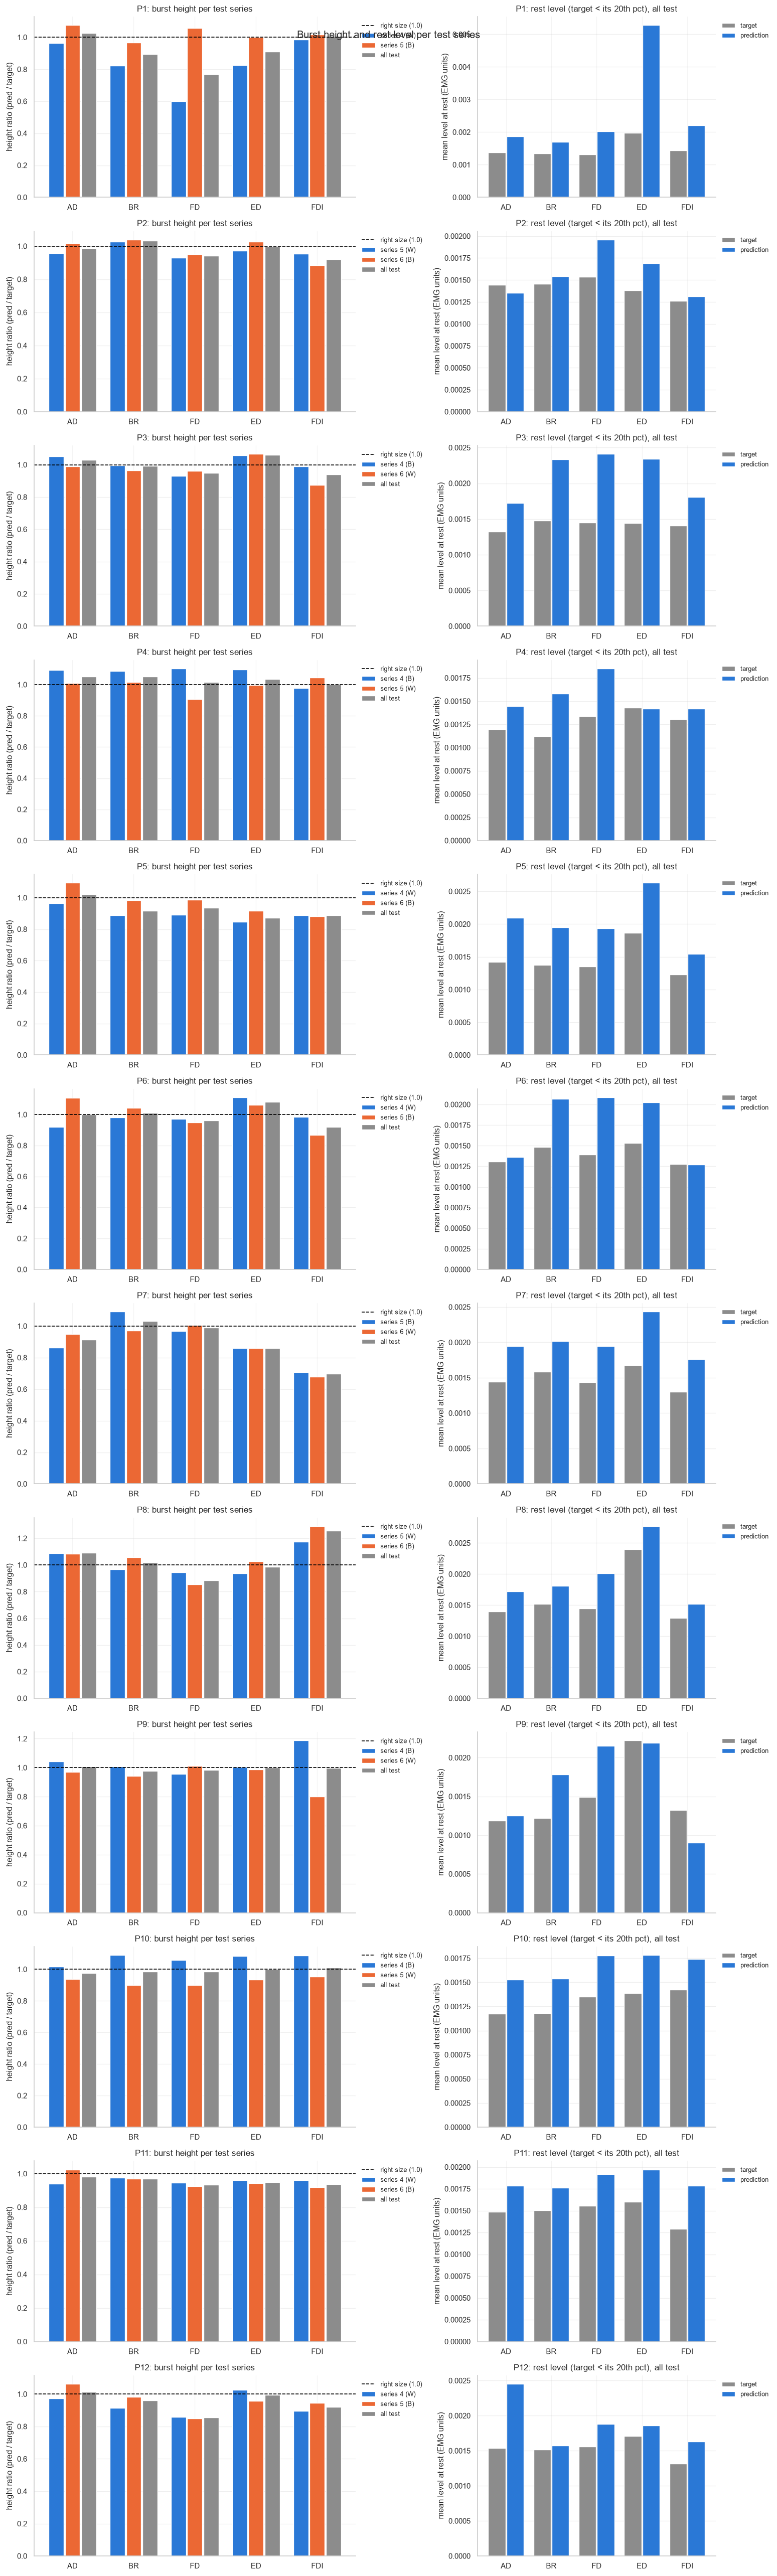

✓  Saved results/magnitude_report_1stage.csv and results/magnitude_report_1stage.png


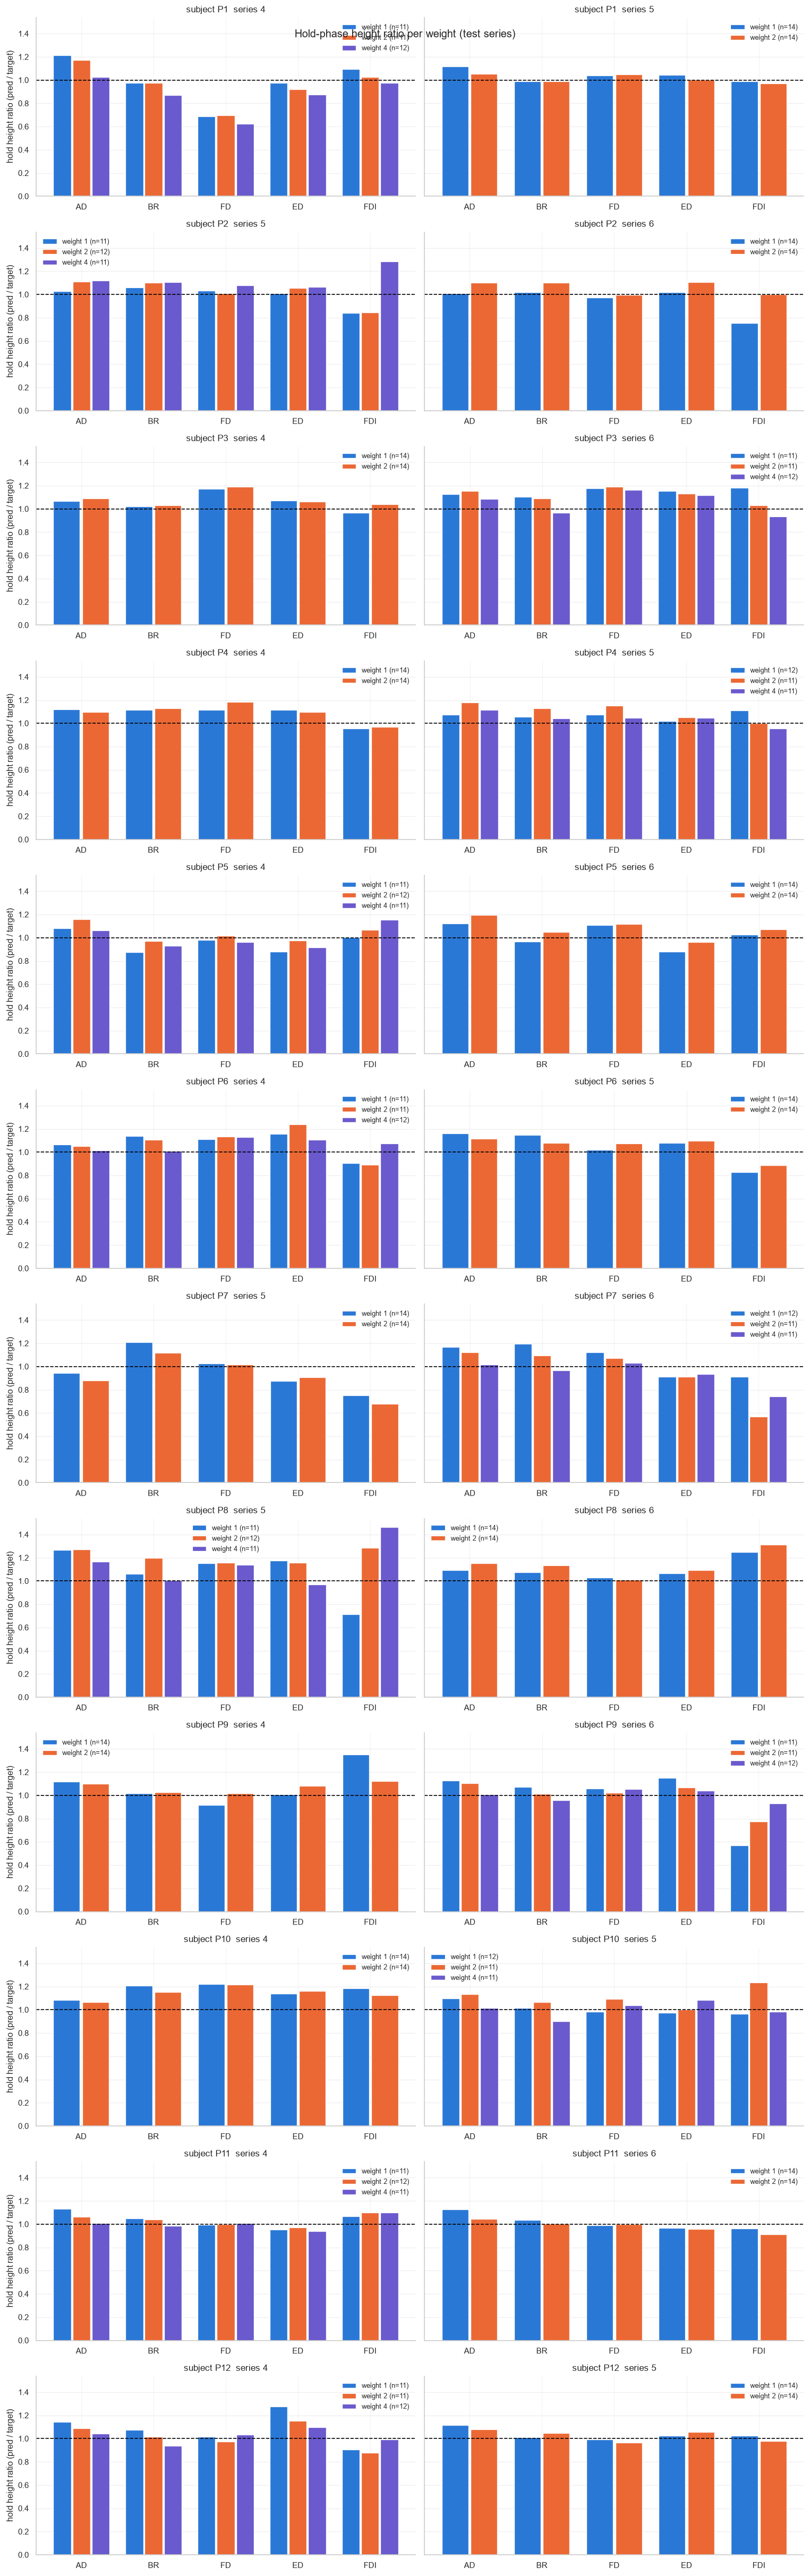

✓  Saved results/magnitude_by_load_1stage.csv and results/magnitude_by_load_1stage.png


In [12]:
# ============================================================================
# MAGNITUDE EVALUATION — per test series and per condition (original EMG units)
# ============================================================================
# Pearson r does not show whether bursts have the right SIZE or whether the
# prediction returns to baseline. For each subject every test series is run
# through the best model in consecutive non-overlapping windows (window_size,
# same prepare_batch / normalisation as training; the tail shorter than one
# window is dropped), stitched and denormalised (x * emg_std + emg_mean). Per muscle:
#   height  Σ(pred·active) / Σ(target·active), active = target > its 70th pct (1 = right size)
#   rest    mean pred where target < its 20th pct, next to the mean target there
#   over    Σ relu(pred − target) / Σ target     under  Σ relu(target − pred) / Σ target
#   plus r, CCC, RMSE, VAF%.
#   gain / VAF%_gain / rmse_gain: ORACLE diagnostic, computed with the TEST TARGET — the
#   least-squares scalar g = Σ(pred·target)/Σ(pred²) per series and muscle and the VAF% /
#   RMSE of g·pred. It shows how much of the error is a series-level amplitude drift;
#   it is not a model result (the model cannot know g).
# Rows: "series 4 (W)", "series 5 (B)", ..., "all test"  (W = weight varies,
# S = surface varies, B = both vary). Saves results/magnitude_report_1stage.csv / .png
# Per weight / per surface: mean level over the HOLD phase of every lift
# (P{p}_AllLifts.mat: lift-off + 0.3 s … replace − 0.3 s): n lifts, target and
# predicted hold level, height ratio Σpred/Σtarget, per-lift r (NaN < 4 lifts).
# Saves results/magnitude_by_load_1stage.csv / .png (height ratio per muscle per weight).
# ─────────────────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from main import (
    get_split_series, series_conditions,
    predict_series, magnitude_report_by_series, format_magnitude_table, plot_magnitude_report,
    format_gain_table,
    lift_hold_segments, magnitude_by_load, format_magnitude_by_load, plot_magnitude_by_load,
)
from main.dataloader import emg_channel_names

MAGNITUDE_CSV = "results/magnitude_report_1stage.csv"   # main.ipynb writes magnitude_report.csv
MAGNITUDE_PNG = "results/magnitude_report_1stage.png"
MAGNITUDE_LOAD_CSV = "results/magnitude_by_load_1stage.csv"   # main.ipynb writes magnitude_by_load.csv
MAGNITUDE_LOAD_PNG = "results/magnitude_by_load_1stage.png"
os.makedirs("results", exist_ok=True)

magnitude_reports = {}
magnitude_names = {}     # subject -> EMG channel names (true order, from the HS files)
load_reports = []
for _subj, _res in per_subject_results.items():
    _cfg = _res["cfg"]
    _bm  = _res["model"]          # best.pt already loaded by the training loop
    _bm.eval()
    _p_id = int(_subj.lstrip("P"))
    _test_ds = _res["test_ds"]
    _names = emg_channel_names(_subj, _test_ds.data_dir)
    magnitude_names[_subj] = _names

    # unique full series, in the dataset's (sorted) test-split order
    _unique, _seen = [], set()
    for _e, _k, _m, _start in _test_ds._windows:
        if id(_e) not in _seen:
            _seen.add(id(_e))
            _unique.append((_e, _k, _m))
    _ids = get_split_series("test", _p_id, _test_ds.data_dir)
    assert len(_ids) == len(_unique), (_ids, len(_unique))

    _series = {}
    for _sid, (_e, _k, _m) in zip(_ids, _unique):
        _series[_sid] = predict_series(
            _bm, _e, _k, _m, _res["prepare_batch"], _res["emg_mean"], _res["emg_std"],
            window=_cfg["dataset"]["window_size"], device=device,
            use_amp=_cfg["training"].get("use_amp", False),
            batch_size=_cfg["training"]["batch_size"],
        )
    _df_mag = magnitude_report_by_series(
        _series, series_conditions(_p_id, _test_ds.data_dir),
        fs=_cfg["data"].get("fs_eeg", 500.0), channel_names=_names,
    )
    _df_mag.insert(0, "subject", _subj)
    magnitude_reports[_subj] = _df_mag
    print(f"\n{'─' * 90}\n  {_subj} — magnitude per test series (original EMG units)\n{'─' * 90}")
    print(format_magnitude_table(_df_mag))
    print("\n  Gain per series — ORACLE diagnostic of series-level amplitude drift, not a model result: "
          "g = Σ(pred·target)/Σ(pred²) uses the test target (1 = no drift, > 1 = prediction too small).")
    print(format_gain_table(_df_mag))

    # ── per weight (CurW) / per surface (CurS) over the hold phase of each lift ──
    _conds = series_conditions(_p_id, _test_ds.data_dir)
    for _sid, (_pred, _tgt) in _series.items():
        _segs = lift_hold_segments(_p_id, _sid, fs=_cfg["data"].get("fs_eeg", 500.0),
                                   data_dir=_test_ds.data_dir, n_samples=len(_tgt))
        for _grp in ("CurW", "CurS"):
            _df_load = magnitude_by_load(_pred, _tgt, _segs, group=_grp, channel_names=_names)
            _df_load.insert(0, "condition", _conds.get(_sid, "?"))
            _df_load.insert(0, "series", _sid)
            _df_load.insert(0, "subject", _subj)
            load_reports.append(_df_load)
            print()
            print(format_magnitude_by_load(_df_load))

magnitude_df = pd.concat(magnitude_reports.values(), ignore_index=True)
magnitude_df.to_csv(MAGNITUDE_CSV, index=False)

# one common label list for the figures (the channel names are identical for P1..P12)
_plot_names = next(iter(magnitude_names.values()))
assert all(v == _plot_names for v in magnitude_names.values()), magnitude_names
fig_mag = plot_magnitude_report(magnitude_reports, _plot_names,
                                title="Burst height and rest level per test series")
fig_mag.savefig(MAGNITUDE_PNG, dpi=200, bbox_inches="tight")
plt.show()
print(f"✓  Saved {MAGNITUDE_CSV} and {MAGNITUDE_PNG}")

magnitude_load_df = pd.concat(load_reports, ignore_index=True)
magnitude_load_df.to_csv(MAGNITUDE_LOAD_CSV, index=False)
fig_load = plot_magnitude_by_load(magnitude_load_df, _plot_names, group="CurW",
                                  title="Hold-phase height ratio per weight (test series)")
fig_load.savefig(MAGNITUDE_LOAD_PNG, dpi=200, bbox_inches="tight")
plt.show()
print(f"✓  Saved {MAGNITUDE_LOAD_CSV} and {MAGNITUDE_LOAD_PNG}")



────────────────────────────────────────────────────────────
  P1
────────────────────────────────────────────────────────────
Pearson r
condition          AD      BR      FD      ED     FDI    mean
-------------------------------------------------------------
full            0.945   0.915   0.777   0.896   0.923   0.891
kin_zero        0.038   0.081  -0.131  -0.102   0.061  -0.010
kin_off         0.036   0.049  -0.110  -0.097   0.060  -0.012
kin_shuffle     0.903   0.865   0.672   0.852   0.790   0.816
eeg_shuffle     0.946   0.916   0.783   0.898   0.925   0.894

Mean level during rest (z-space, target < threshold)
condition          AD      BR      FD      ED     FDI    mean
-------------------------------------------------------------
target         -0.793  -0.822  -0.710  -1.099  -0.571  -0.799
full           -0.727  -0.727  -0.536  -0.473  -0.503  -0.593
kin_zero        0.216   0.214  -0.071   0.241  -0.231   0.074
kin_off         0.223   0.140  -0.026   0.265   0.204   0.161
ki

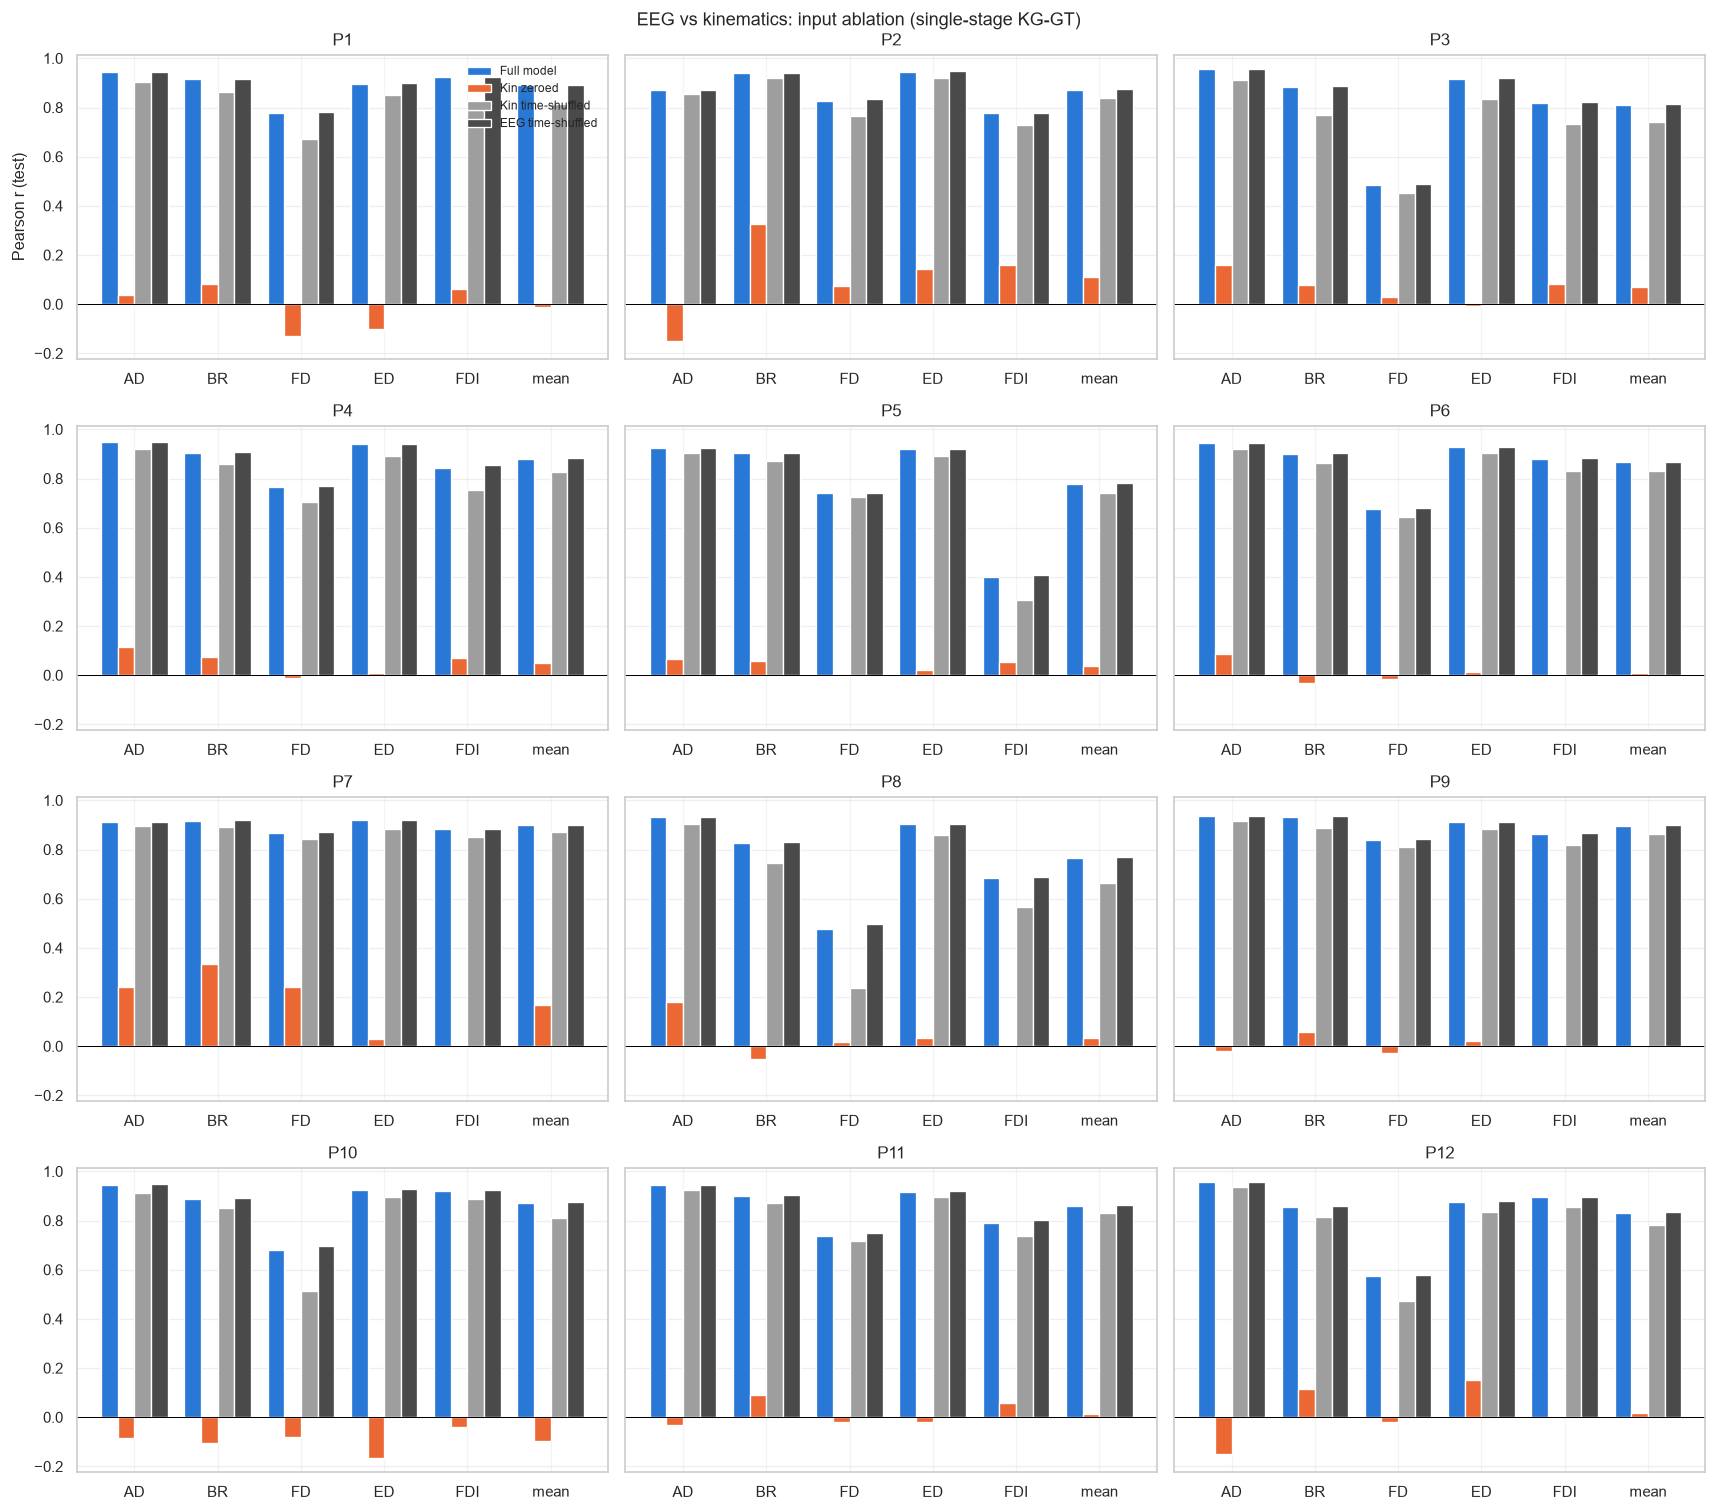

✓  Saved results/input_ablation_1stage.png and results/input_ablation_1stage.csv


In [13]:
# ============================================================================
# HOW MUCH DOES THE MODEL USE EEG vs KINEMATICS?  (test set, input ablation)
# ============================================================================
# For each subject the best model is run on the TEST loader through the same
# prepare_batch (normalisation + kin column drop) as the evaluation above; the
# normalised inputs are then perturbed:
#   full         unchanged
#   kin_zero     kinematics = 0 in z-space (= per-feature training mean)
#   kin_shuffle  kinematics time-shuffled within each window (fixed, seeded permutation)
#   eeg_shuffle  EEG time-shuffled within each window (fixed, seeded permutation)
# Reported: Pearson r per muscle + mean, and the mean predicted level during
# rest (test target below the per-muscle 10th percentile of the TRAINING target;
# the notebook has no absolute rest threshold — the loss uses a per-window
# relative one), full vs kin-zeroed.  All values in normalised (z) units.
# ─────────────────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from main import (
    input_ablation, rest_threshold_from_loader,
    ABLATION_CONDITIONS, ABLATION_LABELS, ABLATION_COLORS,
)
from main.dataloader import emg_channel_names

ABLATION_PNG    = "results/input_ablation_1stage.png"   # main.ipynb writes input_ablation.png
ABLATION_CSV    = "results/input_ablation_1stage.csv"
REST_PERCENTILE = 10.0
ABLATION_SEED   = CONFIG["training"]["seed"]

ablation_results = {}
ablation_names   = {}     # subject -> EMG channel names (true order, from the HS files)
_abl_rows = []
for _subj, _res in per_subject_results.items():
    _cfg = _res["cfg"]
    _pb  = _res["prepare_batch"]
    _bm  = _res["model"]          # best.pt already loaded by the training loop
    _bm.eval()
    _names = emg_channel_names(_subj, _res["test_ds"].data_dir)
    ablation_names[_subj] = _names

    # rest threshold from the training targets (unshuffled, no dropped windows)
    _train_eval_loader = DataLoader(_res["train_ds"], batch_size=_cfg["training"]["batch_size"],
                                    shuffle=False, num_workers=0)
    _rest_thr = rest_threshold_from_loader(_train_eval_loader, _pb, q=REST_PERCENTILE)

    _abl = input_ablation(
        _bm, _res["test_loader"], _pb, device,
        seed=ABLATION_SEED,
        use_amp=_cfg["training"].get("use_amp", False),
        rest_threshold=_rest_thr,
    )
    _abl.predictions.clear()      # keep only the summaries in memory
    ablation_results[_subj] = _abl

    print(f"\n{'─'*60}\n  {_subj}\n{'─'*60}")
    print(_abl.as_table(_names))
    _rf = _abl.r_mean["full"]
    print(f"  Δr (full − kin_zero)    = {_rf - _abl.r_mean['kin_zero']:+.3f}")
    print(f"  Δr (full − kin_shuffle) = {_rf - _abl.r_mean['kin_shuffle']:+.3f}")
    print(f"  Δr (full − eeg_shuffle) = {_rf - _abl.r_mean['eeg_shuffle']:+.3f}")
    _abl_rows.append({
        "Subject": _subj,
        **{f"r_{c}": _abl.r_mean[c] for c in ABLATION_CONDITIONS},
        "rest_target": float(np.nanmean(_abl.rest_target)),
        "rest_pred_full": float(np.nanmean(_abl.rest_pred["full"])),
        "rest_pred_kin_zero": float(np.nanmean(_abl.rest_pred["kin_zero"])),
    })

ablation_df = pd.DataFrame(_abl_rows)
if len(ablation_df) > 1:
    _gm = ablation_df.drop(columns="Subject").mean().to_dict()
    _gm["Subject"] = "GRAND MEAN"
    ablation_df = pd.concat([ablation_df, pd.DataFrame([_gm])], ignore_index=True)
print("\n" + "=" * 65)
print("  INPUT ABLATION SUMMARY (mean Pearson r over muscles; rest level in z units)")
print("=" * 65)
print(ablation_df.round(3).to_string(index=False))

# ── Bar plot: r per muscle, one bar per condition, one panel per subject ────
_n = len(ablation_results)
_ncols = min(3, _n)
_nrows = int(np.ceil(_n / _ncols))
fig_abl, _axes = plt.subplots(_nrows, _ncols, figsize=(4.8 * _ncols, 3.2 * _nrows),
                              squeeze=False, sharey=True, facecolor="white")
_w = 0.8 / len(ABLATION_CONDITIONS)
for _ax, (_subj, _abl) in zip(_axes.flat, ablation_results.items()):
    _names = ablation_names[_subj]
    _x = np.arange(len(_names) + 1)
    for _k, _c in enumerate(ABLATION_CONDITIONS):
        _vals = list(_abl.r[_c]) + [_abl.r_mean[_c]]
        _ax.bar(_x + (_k - (len(ABLATION_CONDITIONS) - 1) / 2) * _w, _vals, _w,
                color=ABLATION_COLORS[_c], label=ABLATION_LABELS[_c])
    _ax.axhline(0, color="black", linewidth=0.6)
    _ax.set_xticks(_x)
    _ax.set_xticklabels(_names + ["mean"])
    _ax.set_title(_subj, fontsize=10)
    _ax.grid(axis="y", alpha=0.3)
for _ax in list(_axes.flat)[_n:]:
    _ax.axis("off")
_axes[0, 0].set_ylabel("Pearson r (test)")
_axes[0, 0].legend(fontsize=7, frameon=False)
fig_abl.suptitle("EEG vs kinematics: input ablation (single-stage KG-GT)", fontsize=11)
fig_abl.tight_layout()
os.makedirs("results", exist_ok=True)
fig_abl.savefig(ABLATION_PNG, dpi=200, bbox_inches="tight")
ablation_df.to_csv(ABLATION_CSV, index=False)
plt.show()
print(f"✓  Saved {ABLATION_PNG} and {ABLATION_CSV}")


### Interpretability figures: what each panel is and is not

The input ablation above is the reference: this model's output is driven by the kinematic inputs (kinematics zeroed → r ≈ 0) and is almost unchanged when the EEG is time-shuffled. An EEG attention map shown as "the explanation" of the prediction would therefore mislead. The two cells below show where the output comes from, and show EEG evidence only when the EEG measurably changes the output.

The model is run exactly as it is trained and evaluated: in windows of `dataset.window_size` = 500 samples = 1 s. Attention exists only inside one such window; nothing below crosses a window border.

**Per-stretch figure** (`plot_interp_window`, one per 10 s stretch, first `MAX_WINDOWS_PER_SERIES` stretches of every test series)

| Panel | What it is | What it is not |
|---|---|---|
| Panel 1 | Actual and predicted EMG envelope per muscle, in original EMG units. Both curves get the same filtering (none by default; `INTERP_SMOOTH_HZ` low-passes both, for display only). r and RMSE are computed on the unfiltered signals. Vertical lines are the task events of `P{p}_AllLifts.mat` (LED on, first digit touch, lift-off, replace, release); the shading marks the time the hand is near the object (gate > 0). | Not a smoothed prediction against a raw target, and the markers are not derived from the EMG. |
| Panel 2 | The exact split of the model output into its two additive paths, in normalised units: **EEG/graph path** `lag(decoder(GAT output))` (it contains the decoder bias) and **kinematic skip path** `lag(decoder(kin skip) − decoder(0))`. The decoder and the lag filter are linear, so the two solid lines sum to the model output (thin blue line) up to float round-off. The dashed line is an occlusion: the graph path recomputed with the kinematic edge bias of the GAT set to 0. | The graph path is not "the EEG contribution": it still depends on the kinematics through the edge bias (the gap between the solid and the dashed purple line), and a large graph path does not show that the EEG drives the output — the ablation and the effect size answer that. The dashed line is not an exact share. |
| Panel 3 | The muscle-graph attention of the GAT **after softmax**, heads averaged, all N×N directed entries: one block per receiving muscle, rows = source muscle, colour = change from the mean during rest (hand away from the object, gate = 0, over the whole series). | Not EEG attention, not the raw kinematic edge-bias logits, and not an amplitude contribution: it shows how the graph mixes the muscle nodes, while amplitude reaches the output mainly through the kinematic skip path of Panel 2. |

**Event-locked figure** (`plot_event_locked`, all test lifts aligned to lift-off and to first digit touch; the event is at the centre of a 1 s model window)

| Column | What it is | What it is not |
|---|---|---|
| (i) | Actual and predicted envelope, mean ± SD over the lifts (`EVENT_BY_WEIGHT = True`: one line per weight). | Not a single trial. |
| (ii) | Mean of the exact decomposition (EEG/graph path, kinematic skip path, ± SD). Three more curves are occlusion effects: force inputs set to 0 N, pose velocities set to 0, kinematic edge bias zeroed. | The occlusion curves are not exact shares: the kin skip is a non-linear MLP, so the force and velocity effects need not add up to the kinematic path. |
| (iii) | EEG evidence, shown only if the EEG effect size (mean absolute change of the output divided by the SD of the output when the EEG is time-shuffled within each window, over the whole test set) is at least `EEG_EFFECT_THRESHOLD` (0.02). Then: the attention rollout row of the encoder for the query at the event sample (heads averaged, residual connection added, layers multiplied; the true attention weights, no temperature, no per-head rescaling), the occlusion attribution over time (output change when a 50 ms EEG bin is replaced by its window mean) and per electrode. The deletion-curve faithfulness score in the title says whether the occlusion map ranks the EEG bins the model really uses (0 = no better than random bins). Below the threshold the column holds a note instead: the EEG has no measurable effect, so no attention map is drawn. | Rollout says how the encoder mixes EEG time steps, not how much the output depends on them; the occlusion maps and the effect size measure that dependence. |

`main.plots.plot_interpretability_triptych` (the old figure) is still in the library but is no longer used by these two cells.

In [14]:
# ─────────────────────────────────────────────────────────────────────────────
# INTERPRETABILITY — Full-Signal Triptych (All Subjects × 10-s Stretches)
# ─────────────────────────────────────────────────────────────────────────────
# Needs only trained models in per_subject_results (no training, no checkpoint loading).
#
# ONE inference path, the same as the evaluation / magnitude cells
# (main.inference.predict_series_stitched): every test series is run through the
# best model in consecutive NON-overlapping windows of exactly the training window
# size (cfg["dataset"]["window_size"] = 500 samples = 1 s) through prepare_batch;
# a last partial second is covered by one extra window aligned to the series end.
#
# For each subject in per_subject_results and EVERY test series, computed once:
#   • stitched prediction (evaluation path) and the exact path decomposition
#     (main.interp.decompose_series, same 1 s windows)
#   • task events of the series (main.interp.lift_events, P{p}_AllLifts.mat) and the
#     hand-near-object gate (raw kin of the HS file)
#   • one main.interp_plots.plot_interp_window per non-overlapping 10-second stretch
#     (first MAX_WINDOWS_PER_SERIES stretches; None = all):
#       Panel 1  actual vs predicted, denormalised (x * emg_std + emg_mean); the same
#                filtering for both (none unless INTERP_SMOOTH_HZ is set), r / RMSE on
#                the unfiltered signals, event markers, gate shading
#       Panel 2  exact split of the model output: EEG/graph path + kinematic skip path
#                (they sum to the output); dashed = graph path with the kinematic edge
#                bias zeroed (occlusion)
#       Panel 3  muscle-graph attention AFTER softmax (heads averaged, all N×N directed
#                entries), change from its mean at rest (gate = 0 over the series)
#     There is no EEG attention heat map here: see the markdown cell above.
#   • Saves to: outputs/interpretability_1stage/{subject}/series{i}_window{w}_{t}s-{t+10}s.png
#
# After the loop the first 10 s of the first test series of `subject_str` are exported
# for the diagnostic cells below: eeg_b / kin_b = stacked 1 s model windows
# (n_windows, window, ·) of normalised inputs, true_np / pred_np (T, C) in original
# EMG units, fs, EMG_NAMES.
# ─────────────────────────────────────────────────────────────────────────────
import os
import torch
import numpy as np
import matplotlib
matplotlib.use("Agg")   # non-interactive backend → safe for batch saving
import matplotlib.pyplot as plt
from main import get_split_series
from main.dataloader import emg_channel_names
from main.inference import predict_series_stitched, window_batch
from main.interp import (
    decompose_series, lift_events, series_gate, kin_column_groups, raw_zero_kin_baseline,
)
from main.interp_plots import plot_interp_window

from main.preprocessing_emg_kin import kin_feature_names

# Names of the kinematic model inputs, derived from CONFIG
# (hand pose 10 + gated F_L, F_G + pose velocity 10 + gated-force velocity 2 = 24 features;
#  the GAT edge bias sees the first 12, the kin skip highway the gated forces + all velocities).
_kin_cfg = CONFIG["preprocessing"]["kinematics"]
KIN_FEATURE_NAMES = kin_feature_names(
    _kin_cfg["include_velocity"], _kin_cfg["include_acceleration"], _kin_cfg["drop_indices"],
    gated_force=_kin_cfg.get("gated_force"),
)
# columns occluded for the force / pose-velocity effects (used by the event-locked cell too)
KIN_GROUPS = kin_column_groups(KIN_FEATURE_NAMES)

# ── USER CONFIG ───────────────────────────────────────────────────────────────
window_sec       = 10.0         # duration of each plotted stretch (seconds); the MODEL window stays dataset.window_size
MAX_WINDOWS_PER_SERIES = None   # None = plot every 10 s stretch of every test series; set a number N to plot only the first N
INTERP_SMOOTH_HZ = None         # None = no filtering; a number low-passes BOTH actual and predicted in Panel 1 (display only)
subjects_to_plot = list(per_subject_results.keys())  # plot all; restrict if needed
# ─────────────────────────────────────────────────────────────────────────────


def _unique_test_series(ds):
    """Full (eeg, kin, emg) arrays of the test series, in the dataset's sorted stratified test order."""
    out, seen = [], set()
    for _e, _k, _m, _start in ds._windows:
        if id(_e) not in seen:
            seen.add(id(_e))
            out.append((_e, _k, _m))
    return out


for _subj in subjects_to_plot:
    _res         = per_subject_results[_subj]
    _bm          = _res["model"];  _bm.eval()
    _test_ds     = _res["test_ds"]
    _pb          = _res["prepare_batch"]
    _cfg         = _res["cfg"]
    _names       = emg_channel_names(_subj, _test_ds.data_dir)   # true channel order, from the HS files
    _p_id        = int(_subj.lstrip("P"))

    _fs      = _cfg["data"].get("fs_eeg", 500.0)
    _win_len = int(window_sec * _fs)                 # plotted stretch (samples)
    _model_win = _cfg["dataset"]["window_size"]      # model window (samples)

    _save_dir = os.path.join("outputs", "interpretability_1stage", _subj)
    os.makedirs(_save_dir, exist_ok=True)

    _emg_mean_np = _res["emg_mean"].cpu().numpy()
    _emg_std_np  = _res["emg_std"].cpu().numpy()

    _unique_series = _unique_test_series(_test_ds)
    _test_ids = get_split_series("test", _p_id, _test_ds.data_dir)
    print(f"\n{'─'*65}")
    print(f"  {_subj} — {len(_unique_series)} test series")

    _total_plots = 0
    for _series_idx, (_eeg_full, _kin_full, _emg_full) in enumerate(_unique_series):
        _real_series = _test_ids[_series_idx]
        _n_windows = _eeg_full.shape[0] // _win_len      # complete 10-s stretches

        if _n_windows == 0:
            print(f"  Series {_real_series}: too short for one {window_sec:.0f}s window, skipping.")
            continue
        _n_plot = _n_windows if MAX_WINDOWS_PER_SERIES is None else min(_n_windows, int(MAX_WINDOWS_PER_SERIES))

        print(f"  Series {_real_series}: {_eeg_full.shape[0]} samples → {_n_windows} windows of {window_sec:.0f}s"
              f" (plotting {_n_plot})")

        # ── the ONE inference path: 1 s model windows, stitched over the whole series ──
        torch.cuda.empty_cache()
        _pred_z = predict_series_stitched(
            _bm, _eeg_full, _kin_full, _pb,
            window=_cfg["dataset"]["window_size"], device=device,
            batch_size=_cfg["training"]["batch_size"],
            use_amp=_cfg["training"].get("use_amp", False),
        )
        _pred_full = _pred_z * _emg_std_np + _emg_mean_np                  # (T, C) original EMG units
        _true_full = np.asarray(_emg_full, dtype=np.float32)               # dataset EMG is in original units

        # ── exact path decomposition over the same windows (normalised units) ──────────
        # occlusion baseline of the force / velocity effects: 0 N and 0 velocity (not z = 0)
        _kin_base = raw_zero_kin_baseline(_pb, _eeg_full.shape[1], _kin_full.shape[1], _emg_full.shape[1])
        _dec = decompose_series(
            _bm, _eeg_full, _kin_full, _pb, window=_model_win,
            batch_size=_cfg["training"]["batch_size"],
            force_cols=KIN_GROUPS["force"], vel_cols=KIN_GROUPS["velocity"], kin_baseline=_kin_base,
        )

        # ── task events + hand-near-object gate (raw files; no model) ──────────────────
        _events = lift_events(_p_id, _real_series, fs=_fs, data_dir=_test_ds.data_dir,
                              n_samples=_eeg_full.shape[0])
        _gate = series_gate(_p_id, _real_series, _test_ds.data_dir, fs=_fs, n_samples=_eeg_full.shape[0],
                            gate_kwargs=_cfg["preprocessing"]["kinematics"].get("gated_force"))
        # Panel 3 reference: mean muscle-graph attention while the hand is away from the object
        _attn_rest = None
        if _dec["gat_attn"] is not None and _gate is not None and int((_gate == 0).sum()) >= _model_win:
            _attn_rest = _dec["gat_attn"][_gate == 0].mean(axis=0)

        for _w in range(_n_plot):
            _start_idx = _w * _win_len
            _end_idx   = _start_idx + _win_len
            _t_start = _w * window_sec
            _t_end   = _t_start + window_sec

            _fig = plot_interp_window(
                pred=_pred_full[_start_idx:_end_idx],
                target=_true_full[_start_idx:_end_idx],
                parts={_k: _dec[_k][_start_idx:_end_idx]
                       for _k in ("total", "graph", "kin", "graph_no_kin_bias")},
                muscle_names=_names,
                fs=_fs,
                start=_start_idx,
                gat_attn=None if _dec["gat_attn"] is None else _dec["gat_attn"][_start_idx:_end_idx],
                attn_baseline=_attn_rest,
                events=_events,
                gate=None if _gate is None else _gate[_start_idx:_end_idx],
                smooth_hz=INTERP_SMOOTH_HZ,
                model_window=_model_win,
                title=(f"{_subj}  |  Series {_real_series}  |  {_t_start:.0f}s – {_t_end:.0f}s"
                       f"  |  model windows of {_model_win / _fs:g} s"),
            )

            _fname = os.path.join(
                _save_dir,
                f"series{_real_series:02d}_window{_w:03d}_{_t_start:.0f}s-{_t_end:.0f}s.png",
            )
            _fig.savefig(_fname, dpi=150, bbox_inches="tight")
            plt.close(_fig)
            _total_plots += 1
        del _pred_full, _true_full, _dec, _gate, _attn_rest

    print(f"  [{_subj}] Saved {_total_plots} interpretability plot(s) → {_save_dir}")

print(f"\n✓  Interpretability figure generation complete.")
print(f"   Plots saved under: outputs/interpretability_1stage/")

# ── Diagnostic stretch for the cells below ───────────────────────────────────
# First 10 s of the first test series of `subject_str` (the subject whose best_model /
# emg_mean / emg_std are in the global scope), as stacked 1 s model windows.
_diag_subj = subject_str if subject_str in per_subject_results else subjects_to_plot[-1]
_res  = per_subject_results[_diag_subj]
_cfg  = _res["cfg"]
fs    = _cfg["data"].get("fs_eeg", 500.0)
_model_win = _cfg["dataset"]["window_size"]
_eeg0, _kin0, _emg0 = _unique_test_series(_res["test_ds"])[0]
_n_diag = (min(int(window_sec * fs), _eeg0.shape[0]) // _model_win) * _model_win
_diag_inputs, _ = window_batch(_eeg0[:_n_diag], _kin0[:_n_diag], _res["prepare_batch"],
                               window=_model_win, emg=_emg0[:_n_diag])
eeg_b     = _diag_inputs["eeg"]                      # (n_windows, window, n_eeg)   normalised model input
kin_b     = _diag_inputs["kin"]                      # (n_windows, window, n_kin)
true_np   = np.asarray(_emg0[:_n_diag], dtype=np.float32)          # (T, C) original EMG units
pred_np   = predict_series_stitched(
    _res["model"], _eeg0[:_n_diag], _kin0[:_n_diag], _res["prepare_batch"], window=_model_win,
    device=device, use_amp=_cfg["training"].get("use_amp", False),
) * _res["emg_std"].cpu().numpy() + _res["emg_mean"].cpu().numpy()
EMG_NAMES = emg_channel_names(_diag_subj, _res["test_ds"].data_dir)
print(f"   Diagnostic stretch: {_diag_subj}, first {_n_diag / fs:.0f} s of its first test series "
      f"→ eeg_b {tuple(eeg_b.shape)}, kin_b {tuple(kin_b.shape)}")


─────────────────────────────────────────────────────────────────
  P1 — 2 test series
  Series 4: 116240 samples → 23 windows of 10s (plotting 23)
  Series 5: 210644 samples → 42 windows of 10s (plotting 42)
  [P1] Saved 65 interpretability plot(s) → outputs\interpretability_1stage\P1

─────────────────────────────────────────────────────────────────
  P2 — 2 test series
  Series 5: 151647 samples → 30 windows of 10s (plotting 30)
  Series 6: 206222 samples → 41 windows of 10s (plotting 41)
  [P2] Saved 71 interpretability plot(s) → outputs\interpretability_1stage\P2

─────────────────────────────────────────────────────────────────
  P3 — 2 test series
  Series 4: 196416 samples → 39 windows of 10s (plotting 39)
  Series 6: 116333 samples → 23 windows of 10s (plotting 23)
  [P3] Saved 62 interpretability plot(s) → outputs\interpretability_1stage\P3

─────────────────────────────────────────────────────────────────
  P4 — 2 test series
  Series 4: 205592 samples → 41 windows of 10s (

In [15]:
# ─────────────────────────────────────────────────────────────────────────────
# Event-locked interpretability (all test lifts)
# ─────────────────────────────────────────────────────────────────────────────
# Needs only trained models in per_subject_results (no training, no checkpoint loading)
# and the interpretability cell above (_unique_test_series, KIN_GROUPS).
#
# For each subject and each event (lift-off, first digit touch; times from
# P{p}_AllLifts.mat via main.interp.lift_events):
#   • one 1 s MODEL window per test lift, centred on the event (the event sample is at
#     the middle of the window; window length = dataset.window_size, as in training)
#   • per lift: prediction, target, exact path decomposition, attention-rollout row of
#     the query at the event sample, EEG occlusion attribution (main.interp.event_locked_windows)
#   • mean ± SD over all test lifts (main.interp.event_locked_summary) →
#     main.interp_plots.plot_event_locked: rows = muscles, columns
#       (i)   actual vs predicted            (ii) decomposition (+ occlusion effects)
#       (iii) EEG evidence — or, if the EEG effect size is below EEG_EFFECT_THRESHOLD,
#             the note that the EEG has no measurable effect and attention is not shown
#   • Saves to: outputs/interpretability_1stage_event/{subject}/event_{event}.png
# Printed per subject: the EEG effect size (mean |Δ output| / SD of the output when the
# EEG is time-shuffled within each window, whole test set) and, per event, the
# deletion-curve faithfulness score of the EEG occlusion map (0 = no better than random).
# ─────────────────────────────────────────────────────────────────────────────
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")   # non-interactive backend → safe for batch saving
import matplotlib.pyplot as plt
from main import get_split_series
from main.dataloader import emg_channel_names
from main.interp import (
    lift_events, event_samples, event_locked_windows, concat_event_locked, event_locked_summary,
    eeg_effect_size, eeg_channel_names, raw_zero_kin_baseline, EVENT_LABELS,
)
from main.interp_plots import plot_event_locked

# ── USER CONFIG ───────────────────────────────────────────────────────────────
EVENT_LOCKED_EVENTS  = ["lift_off", "first_touch"]   # keys of main.interp.EVENT_COLUMNS
EEG_EFFECT_THRESHOLD = 0.02     # below this the figure shows a note instead of EEG maps
EVENT_BY_WEIGHT      = False    # True → column (i) draws one line per weight (CurW) instead of mean ± SD
EVENT_TIME_BIN_MS    = 50.0     # EEG occlusion bin
EVENT_BATCH          = 8        # lifts per forward pass
subjects_to_plot = list(per_subject_results.keys())
# ─────────────────────────────────────────────────────────────────────────────

event_locked_results = {}       # subject -> {"eeg_effect": float, event: summary dict}
for _subj in subjects_to_plot:
    _res     = per_subject_results[_subj]
    _bm      = _res["model"];  _bm.eval()
    _test_ds = _res["test_ds"]
    _pb      = _res["prepare_batch"]
    _cfg     = _res["cfg"]
    _p_id    = int(_subj.lstrip("P"))
    _names   = emg_channel_names(_subj, _test_ds.data_dir)   # true channel order, from the HS files
    _fs      = _cfg["data"].get("fs_eeg", 500.0)
    _model_win = _cfg["dataset"]["window_size"]
    _pre     = _model_win // 2
    _post    = _model_win - _pre
    _time_bin = max(1, int(round(EVENT_TIME_BIN_MS * _fs / 1000.0)))

    _save_dir = os.path.join("outputs", "interpretability_1stage_event", _subj)
    os.makedirs(_save_dir, exist_ok=True)

    _unique_series = _unique_test_series(_test_ds)
    _test_ids = get_split_series("test", _p_id, _test_ds.data_dir)
    _eeg_names = eeg_channel_names(_subj, _test_ds.data_dir)
    if len(_eeg_names) != _unique_series[0][0].shape[1]:      # e.g. a channel subset was selected
        _eeg_names = None

    # ── does the EEG change the output at all?  (whole test set, EEG time-shuffled) ──
    _effect = eeg_effect_size(
        _bm, (_pb(_e, _k, _m)[0] for _e, _k, _m in _res["test_loader"]),
        seed=_cfg["training"]["seed"],
    )
    _shown = _effect >= EEG_EFFECT_THRESHOLD
    print(f"\n{'─'*65}")
    print(f"  {_subj} — EEG effect size = {_effect:.4f}  "
          f"({'≥' if _shown else '<'} threshold {EEG_EFFECT_THRESHOLD:g}: "
          f"{'EEG evidence is shown' if _shown else 'attention is NOT shown as an explanation'})")
    event_locked_results[_subj] = {"eeg_effect": _effect}

    for _ev_key in EVENT_LOCKED_EVENTS:
        _label = EVENT_LABELS[_ev_key]
        _per_series = []
        for _series_idx, (_eeg_full, _kin_full, _emg_full) in enumerate(_unique_series):
            _real_series = _test_ids[_series_idx]
            _events = lift_events(_p_id, _real_series, fs=_fs, data_dir=_test_ds.data_dir,
                                  n_samples=_eeg_full.shape[0])
            _per_series.append(event_locked_windows(
                _bm, _eeg_full, _kin_full, _emg_full, event_samples(_events, _ev_key), _pb,
                pre=_pre, post=_post,
                meta=[dict(_e, series=_real_series) for _e in _events],
                emg_mean=_res["emg_mean"], emg_std=_res["emg_std"],
                force_cols=KIN_GROUPS["force"], vel_cols=KIN_GROUPS["velocity"],
                # occlusion baseline of the force / velocity effects: 0 N and 0 velocity (not z = 0)
                kin_baseline=raw_zero_kin_baseline(_pb, _eeg_full.shape[1], _kin_full.shape[1],
                                                   _emg_full.shape[1]),
                time_bin=_time_bin, batch_size=EVENT_BATCH, seed=_cfg["training"]["seed"],
            ))
        _ev_all = concat_event_locked(_per_series)
        _summary = event_locked_summary(_ev_all, group_by="CurW")
        event_locked_results[_subj][_ev_key] = _summary
        _score = _summary["deletion"]["score"] if _summary["deletion"] else float("nan")
        print(f"  {_label:<18}: {_summary['n']} lifts from series {list(_test_ids)}"
              f" | deletion-curve faithfulness score = {_score:+.3f}")

        _fig = plot_event_locked(
            _summary, _names, fs=_fs, event_label=_label,
            eeg_effect=_effect, effect_threshold=EEG_EFFECT_THRESHOLD,
            eeg_names=_eeg_names, by_group=EVENT_BY_WEIGHT, time_bin_ms=EVENT_TIME_BIN_MS,
            title=(f"{_subj}  |  all test lifts aligned to {_label}  |  n = {_summary['n']}"
                   f"  |  model window {_model_win / _fs:g} s, event at its centre"),
        )
        _fname = os.path.join(_save_dir, f"event_{_ev_key}.png")
        _fig.savefig(_fname, dpi=150, bbox_inches="tight")
        plt.close(_fig)
        del _per_series, _ev_all

    print(f"  [{_subj}] Saved {len(EVENT_LOCKED_EVENTS)} event-locked plot(s) → {_save_dir}")

print(f"\n✓  Event-locked interpretability complete.")
print(f"   Plots saved under: outputs/interpretability_1stage_event/")


─────────────────────────────────────────────────────────────────
  P1 — EEG effect size = 0.0762  (≥ threshold 0.02: EEG evidence is shown)
  lift-off          : 62 lifts from series [4, 5] | deletion-curve faithfulness score = +0.087
  first digit touch : 62 lifts from series [4, 5] | deletion-curve faithfulness score = +0.146
  [P1] Saved 2 event-locked plot(s) → outputs\interpretability_1stage_event\P1

─────────────────────────────────────────────────────────────────
  P2 — EEG effect size = 0.0655  (≥ threshold 0.02: EEG evidence is shown)
  lift-off          : 62 lifts from series [5, 6] | deletion-curve faithfulness score = +0.100
  first digit touch : 62 lifts from series [5, 6] | deletion-curve faithfulness score = +0.116
  [P2] Saved 2 event-locked plot(s) → outputs\interpretability_1stage_event\P2

─────────────────────────────────────────────────────────────────
  P3 — EEG effect size = 0.0988  (≥ threshold 0.02: EEG evidence is shown)
  lift-off          : 62 lifts from 

In [ ]:
# Participant / LOSOCV Setup
# ============================================================================
# Supported values for notebook_cfg["data"]["participant"]:
#   "all"      → LOSOCV over all 12 subjects
#   [1,3,5]    → LOSOCV over a specific list
#   "P2" or 2  → Single-subject training (uses train/val/test series split)
#
# LOSOCV val strategy (Option 2 — scientifically clean):
#   For each fold where p_test is the held-out subject:
#     - val_participant  = last subject in the train list (rotates each fold)
#     - train on remaining N-2 subjects (all their series)
#     - val   on val_participant         (all their series) → early stopping
#     - test  on p_test                  (all their series) → final metric
#   The test subject's data NEVER influences any training decision.
# ─────────────────────────────────────────────────────────────────────────────

participant_spec = notebook_cfg["data"]["participant"]
participant_list = resolve_participants(participant_spec)
is_losocv = isinstance(participant_spec, (list, tuple)) or participant_spec == "all"

if is_losocv:
    print(f"LOSOCV mode: {len(participant_list)} participants -> {participant_list}")
    # Initialise first fold
    p_test = participant_list[0]
    # Use the LAST training subject as val (it rotates each fold naturally)
    _train_candidates = [p for p in participant_list if p != p_test]
    val_participant    = _train_candidates[-1]          # held-out from training for early stopping
    train_participants = _train_candidates[:-1]          # N-2 subjects for actual training
    test_participants  = [p_test]
    split_train = split_val = split_test = "all"
    subject_str = f"LOSO_P{p_test}"
else:
    p_id = participant_list[0]
    train_participants = [p_id]
    val_participant    = p_id          # same subject, different series
    test_participants  = [p_id]
    split_train, split_val, split_test = "train", "val", "test"
    subject_str = f"P{p_id}"

print(f"Active subject string : {subject_str}")
print(f"Train participants    : {train_participants}  ({len(train_participants)} subjects)")
print(f"Val  participant      : [{val_participant}]  (early-stopping signal — clean from test)")
print(f"Test participants     : {test_participants}   (final metric — never seen during training)")
print(f"Dataset splits        : train={split_train!r}  val={split_val!r}  test={split_test!r}")


Active subject string : P1
Train participants    : [1]  (1 subjects)
Val  participant      : [1]  (early-stopping signal — clean from test)
Test participants     : [1]   (final metric — never seen during training)
Dataset splits        : train='train'  val='val'  test='test'


In [ ]:
# [OPTIONAL] Automatic LOSOCV — Run ALL Folds Unattended
# ============================================================================
# Run this cell to automatically iterate over all LOSOCV folds.
# Only runs when is_losocv = True (participant = "all" or a list).
#
# Val strategy (Option 2 — scientifically clean):
#   val_participant = last element of each fold's train list
#   → early stopping never touches the test subject's data
#
# Training: single stage (train_single_stage) — full KG-GT trained jointly per fold.
# Checkpoints saved to: outputs/checkpoints_1stage/LOSO_P{N}/
# Figures saved to:     outputs/figures/
# Summary CSV saved to: outputs/losocv_results_1stage.csv
#
# Note: Variables from the LAST fold are saved to global scope
# so that downstream individual plotting/evaluation cells can run seamlessly!
# ─────────────────────────────────────────────────────────────────────────────
import copy, gc, time, os
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from main import (
    build_kg_gt_from_config,
    train_model, TrainConfig,
    collect_predictions, compute_metrics, load_checkpoint,
    compute_muscle_edge_prior, build_loss_from_config, channel_weights_from_config,
)
from main.dataloader import emg_channel_names
from main.inference import predict_series_stitched, window_batch
from main.plots import plot_interpretability_triptych, plot_kin_skip_over_time
from main.preprocessing_emg_kin import kin_feature_names

if not is_losocv:
    print("Single-subject mode — skipping auto LOSOCV loop.  Run cells below instead.")
else:
    cv_rows = []
    os.makedirs("outputs/figures", exist_ok=True)

    for _fold_idx, _p_test in enumerate(participant_list):
        _t_fold = time.time()

        # ── Option 2: round-robin training subject held-out for val ───────────
        _train_candidates = [p for p in participant_list if p != _p_test]
        val_idx    = _fold_idx % len(_train_candidates)
        _val_p     = _train_candidates[val_idx]
        _train_ps  = [p for i, p in enumerate(_train_candidates) if i != val_idx]
        _test_ps   = [_p_test]
        _subj      = f"LOSO_P{_p_test}"
        # true channel order of the held-out subject (read from its HS files; identical for P1..P12)
        EMG_NAMES  = emg_channel_names(_p_test, ROOT / notebook_cfg["data"]["data_root"])

        print(f"\n{'='*65}")
        print(f"  FOLD {_fold_idx+1}/{len(participant_list)}")
        print(f"  Train  : {_train_ps}  ({len(_train_ps)} subjects)")
        print(f"  Val    : [{_val_p}]  (early-stopping only)")
        print(f"  Test   : [{_p_test}]  (final metric — never seen during training)")
        print(f"{'='*65}")

        # ── Datasets ──────────────────────────────────────────────────────────
        _train_ds = build_dataset_split(notebook_cfg, participants=_train_ps, split="all")
        _val_ds   = build_dataset_split(notebook_cfg, participants=[_val_p],  split="all")
        _test_ds  = build_dataset_split(notebook_cfg, participants=_test_ps,  split="all")

        # ── Normalization stats from training fold only ────────────────────────
        def _unique_arrays(ds):
            seen, kins, emgs = set(), [], []
            for ea, ka, ma, _ in ds._windows:
                k = id(ea)
                if k not in seen:
                    seen.add(k); kins.append(ka); emgs.append(ma)
            return kins, emgs

        _tr_kins, _tr_emgs = _unique_arrays(_train_ds)
        _kin_all = np.concatenate(_tr_kins, axis=0)
        _emg_all = np.concatenate(_tr_emgs, axis=0)

        _emg_mean = torch.tensor(_emg_all.mean(0), dtype=torch.float32, device=device)
        _emg_std  = torch.clamp(torch.tensor(_emg_all.std(0),  dtype=torch.float32, device=device), min=1e-6)
        _kin_mean = torch.tensor(_kin_all.mean(0), dtype=torch.float32, device=device)
        _kin_std  = torch.clamp(torch.tensor(_kin_all.std(0),  dtype=torch.float32, device=device), min=1e-6)

        # ── Edge prior + loss ─────────────────────────────────────────────────
        _prior_np   = compute_muscle_edge_prior(_tr_emgs)
        _edge_prior = torch.from_numpy(_prior_np)
        _cw = channel_weights_from_config(   # loss.channel_weights ("auto": from the training fold)
            notebook_cfg["training"], (_emg_all - _emg_mean.cpu().numpy()) / _emg_std.cpu().numpy())
        _loss_fn    = build_loss_from_config(notebook_cfg["training"], channel_weights=_cw)

        # ── prepare_batch ─────────────────────────────────────────────────────
        _drop_idx = notebook_cfg["preprocessing"]["kinematics"]["drop_indices"]
        def _make_pb(em, es, km, ks, dev, drop_idx):
            def _pb(eeg, kin, emg):
                eeg = eeg.to(dev, non_blocking=True)
                kin = kin.to(dev, non_blocking=True)
                emg = emg.to(dev, non_blocking=True)
                kn  = (kin - km) / ks
                if drop_idx:
                    keep = [i for i in range(kn.shape[-1]) if i not in drop_idx]
                    kn   = kn[..., keep]
                return {"eeg": eeg, "kin": kn}, (emg - em) / es
            return _pb
        _pb = _make_pb(_emg_mean, _emg_std, _kin_mean, _kin_std, device, _drop_idx)

        # ── Dims ──────────────────────────────────────────────────────────────
        _s_eeg, _s_kin, _s_emg = _train_ds[0]
        _bi, _ = _pb(_s_eeg.unsqueeze(0), _s_kin.unsqueeze(0), _s_emg.unsqueeze(0))
        _eeg_dim = _s_eeg.shape[-1]
        _kin_dim = _bi["kin"].shape[-1]

        # ── DataLoaders ───────────────────────────────────────────────────────
        _bs = notebook_cfg["training"]["batch_size"]
        _tr_loader  = DataLoader(_train_ds, batch_size=_bs, shuffle=True,  drop_last=True,  pin_memory=True, num_workers=0)
        _val_loader = DataLoader(_val_ds,   batch_size=_bs, shuffle=False, pin_memory=True, num_workers=0)
        _te_loader  = DataLoader(_test_ds,  batch_size=_bs, shuffle=False, pin_memory=True, num_workers=0)

        # ── SINGLE STAGE: full KG-GT trained jointly (same routine as above) ──
        _ss = notebook_cfg["training"]["single_stage"]
        print(f"  Single-stage: full KG-GT joint training ({_ss['epochs']} epochs, lr={_ss['lr']:.0e}) ...")
        _model, _bm, _r, _ckpt_dir = train_single_stage(
            notebook_cfg, _subj, _eeg_dim, _kin_dim, _edge_prior,
            _tr_loader, _val_loader, _pb, _loss_fn, device,
        )

        # ── Evaluation on held-out TEST subject (best.pt already loaded) ─────
        _P, _Y = collect_predictions(
            _bm, _te_loader, _pb, device,
            n_channels=len(EMG_NAMES), use_amp=notebook_cfg["training"]["use_amp"],
        )
        _m = compute_metrics(_P, _Y, channel_names=EMG_NAMES)
        print(f"\n  [P{_p_test} TEST RESULTS]")
        print(_m.as_table())

        cv_rows.append({
            "Fold":         _subj,
            "val_subject":  f"P{_val_p}",
            "train_n":      len(_train_ps),
            **{f"RMSE_{n}":    float(_m.rmse[i])    for i, n in enumerate(EMG_NAMES)},
            **{f"nRMSE_{n}":   float(_m.nrmse[i])   for i, n in enumerate(EMG_NAMES)},
            **{f"MAE_{n}":     float(_m.mae[i])     for i, n in enumerate(EMG_NAMES)},
            **{f"Pearson_{n}": float(_m.pearson[i])  for i, n in enumerate(EMG_NAMES)},
            **{f"CCC_{n}":     float(_m.ccc[i])      for i, n in enumerate(EMG_NAMES)},
            **{f"R2_{n}":      float(_m.r2[i])       for i, n in enumerate(EMG_NAMES)},
            **{f"VAF_{n}":     float(_m.vaf[i])      for i, n in enumerate(EMG_NAMES)},
            "RMSE_mean":    float(_m.rmse.mean()),
            "nRMSE_mean":   float(_m.nrmse.mean()),
            "MAE_mean":     float(_m.mae.mean()),
            "Pearson_mean": float(_m.pearson.mean()),
            "CCC_mean":     float(_m.ccc.mean()),
            "R2_mean":      float(_m.r2.mean()),
            "VAF_mean":     float(_m.vaf.mean()),
        })

        # ── Save Plots for this fold ──────────────────────────────────────────
        # 1. Training History (single stage)
        fig_hist, ax1 = plt.subplots(1, 1, figsize=(8, 4), facecolor="white")
        ss_epochs = np.arange(1, len(_r.history["train"]) + 1)
        ax1.plot(ss_epochs, _r.history["train"], label="Single-stage Train", color="#4C9BE8", linewidth=1.5)
        ax1.plot(ss_epochs, _r.history["val"],   label="Single-stage Val",   color="#E87B4C", linewidth=1.5)
        ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title(f"Single-stage — {_subj}")
        ax1.legend(); ax1.grid(alpha=0.3)

        plt.suptitle(f"Single-stage Training History — {_subj}", fontweight="bold")
        plt.tight_layout()
        plt.savefig(f"outputs/figures/history_1stage_{_subj}.png", dpi=300)
        plt.close(fig_hist)

        # 2. Interpretability Triptych (first 10 s of the first test series)
        # Same inference path as the evaluation: the model sees consecutive windows of the
        # training window size (dataset.window_size) via predict_series_stitched — not one
        # 10 s window. No attention temperature, no smoothing of the attention.
        fs = notebook_cfg["data"].get("fs_eeg", 500.0)
        _model_win = notebook_cfg["dataset"]["window_size"]
        eeg_full, kin_full, emg_full, block_start_idx = _test_ds._windows[0]
        _n_seg = (min(int(10.0 * fs), eeg_full.shape[0]) // _model_win) * _model_win

        _bm.eval()
        pred_z, _internals = predict_series_stitched(
            _bm, eeg_full[:_n_seg], kin_full[:_n_seg], _pb, window=_model_win, device=device,
            batch_size=_bs, return_internals=True, use_amp=notebook_cfg["training"]["use_amp"],
        )
        emg_mean_np = _emg_mean.cpu().numpy()
        emg_std_np  = _emg_std.cpu().numpy()
        pred_np = pred_z * emg_std_np + emg_mean_np
        true_np = np.asarray(emg_full[:_n_seg], dtype=np.float32)   # dataset EMG is in original units

        # last encoder layer, mean over the queries of each time step's own model window → (H, T)
        eeg_attn_np = _internals["encoder_key_attn_stitched"][:, -1].T
        if "kin_edge_bias_stitched" in _internals:
            kin_edge_np = _internals["kin_edge_bias_stitched"]
        else:
            kin_edge_np = np.zeros((pred_np.shape[0], 4, len(EMG_NAMES), len(EMG_NAMES)))

        # stacked model windows (n_windows, window, ·) for the decomposition plots
        model_inputs, _ = window_batch(eeg_full[:_n_seg], kin_full[:_n_seg], _pb,
                                       window=_model_win, emg=emg_full[:_n_seg])
        eeg_b = model_inputs["eeg"]
        kin_b = model_inputs["kin"]

        _kcfg = notebook_cfg["preprocessing"]["kinematics"]
        KIN_FEATURE_NAMES = kin_feature_names(   # follows CONFIG (24: pose, gated forces, their velocities)
            _kcfg["include_velocity"], _kcfg["include_acceleration"], _kcfg["drop_indices"],
            gated_force=_kcfg.get("gated_force"),
        )

        fig_triptych = plot_interpretability_triptych(
            pred=pred_np,
            target=true_np,
            eeg_attn=eeg_attn_np,
            kin_edge_bias=kin_edge_np,
            muscle_names=EMG_NAMES,
            kin_feature_names=KIN_FEATURE_NAMES,
            fs=fs,
            smooth_hz=5.0,
            cfg=notebook_cfg,
        )
        plt.savefig(f"outputs/figures/interpretability_1stage_{_subj}.png", dpi=300)
        plt.close(fig_triptych)

        # 3. Kinematic Skip Highway Diagnostic Plot
        fig_skip = plot_kin_skip_over_time(
            model=_bm,
            eeg_window=eeg_b,
            kin_window=kin_b,
            emg_target=true_np,
            emg_mean=_emg_mean,
            emg_std=_emg_std,
            smooth_hz=5.0,
            emg_names=EMG_NAMES,
            fs=fs,
            cfg=notebook_cfg,
        )
        plt.savefig(f"outputs/figures/kin_skip_1stage_{_subj}.png", dpi=300)
        plt.close(fig_skip)

        # Save last fold variables to global scope for downstream single-subject cells
        if _fold_idx == len(participant_list) - 1:
            stage1_model = None
            model = _model
            best_model = _bm
            train_loader = _tr_loader
            val_loader = _val_loader
            test_loader = _te_loader
            train_ds = _train_ds
            val_ds = _val_ds
            test_ds = _test_ds
            prepare_batch = _pb
            emg_mean = _emg_mean
            emg_std = _emg_std
            kin_mean = _kin_mean
            kin_std = _kin_std
            result_single = _r
            result_stage1 = _r
            result_stage2 = _r
            subject_str = _subj
            edge_prior = _edge_prior
            true_eeg_dim = _eeg_dim
            true_kin_dim = _kin_dim
            print("\n[!] Saved last fold variables to global scope for downstream analysis cells.")
        else:
            del _model, _bm, _train_ds, _val_ds, _test_ds
            del _tr_loader, _val_loader, _te_loader
            torch.cuda.empty_cache(); gc.collect()

        print(f"  Fold {_fold_idx+1} done in {(time.time()-_t_fold)/60:.1f} min")

    # ── Cross-Validation Summary ──────────────────────────────────────────────
    cv_df = pd.DataFrame(cv_rows)
    _num_cols = cv_df.select_dtypes("number").columns
    mean_row  = cv_df[_num_cols].mean().to_dict()
    mean_row["Fold"] = "CV MEAN"; mean_row["val_subject"] = "—"
    cv_df = pd.concat([cv_df, pd.DataFrame([mean_row])], ignore_index=True)

    print("\n" + "="*65)
    print("  LEAVE-ONE-SUBJECT-OUT CROSS-VALIDATION SUMMARY")
    print("  Val strategy: Option 2 (training-subject held out for early stopping)")
    print("="*65)
    summary_cols = ["Fold","val_subject","train_n","RMSE_mean","nRMSE_mean","Pearson_mean","CCC_mean","VAF_mean"]
    print(cv_df[summary_cols].to_string(index=False))
    print("="*65)

    os.makedirs("outputs", exist_ok=True)
    cv_df.to_csv("outputs/losocv_results_1stage.csv", index=False)
    print("Full results exported to: outputs/losocv_results_1stage.csv")
    print("DataFrame available as: cv_df")

Single-subject mode — skipping auto LOSOCV loop.  Run cells below instead.


In [ ]:
# ============================================================================
# [LOSOCV ONLY] Advance to the next fold
# ============================================================================
# When running LOSOCV, run this cell to advance to the next held-out subject,
# then re-run cells B through Q to train & evaluate that fold.
# ─────────────────────────────────────────────────────────────────────────────
if is_losocv:
    # Find current fold index and advance
    _current_idx = participant_list.index(p_test)
    _next_idx = _current_idx + 1
    if _next_idx < len(participant_list):
        p_test = participant_list[_next_idx]
        train_participants = [p for p in participant_list if p != p_test]
        test_participants  = [p_test]
        subject_str = f"LOSO_P{p_test}"
        print(f"Advanced to fold {_next_idx + 1}/{len(participant_list)}: Test = P{p_test}")
        print(f"  Train participants : {train_participants}")
    else:
        print("All LOSOCV folds completed!")
else:
    print("Not in LOSOCV mode — this cell is a no-op.")


Not in LOSOCV mode — this cell is a no-op.


In [ ]:
# ── DIAGNOSTIC: Residual Decomposition (GAT vs Kinematic Skip) ────────────
from main.plots import plot_residual_decomposition
from main.dataloader import emg_channel_names

# eeg_b / kin_b / true_np / fs come from the interpretability cell (or the LOSOCV cell): the first
# 10 s of the first test series as stacked 1 s MODEL windows (n_windows, window, ·), so the model
# sees windows of the training size here too; the plot shows them as one stretch.
EMG_NAMES = emg_channel_names(subject_str, ROOT / notebook_cfg["data"]["data_root"])   # true channel order

if "KIN_FEATURE_NAMES" in globals():   # defined in the interpretability cell
    print("GAT edge-bias inputs :", best_model.gat_kin_feature_names(KIN_FEATURE_NAMES))
    print("Kin skip inputs      :", best_model.skip_kin_feature_names(KIN_FEATURE_NAMES))

fig = plot_residual_decomposition(
    model      = best_model,
    eeg_window = eeg_b,          # Tensor (n_windows, window, 32)
    kin_window = kin_b,          # Tensor (n_windows, window, 24) — hand pose, gated forces and their velocities
    emg_target = true_np,        # np.ndarray (n_windows * window, 5) — physical scale
    emg_mean   = emg_mean,       # ← NEW: un-normalizes model outputs to physical scale
    emg_std    = emg_std,        # ← NEW
    smooth_hz  = 5.0,           # optional low-pass Hz (set None to disable smoothing)
    emg_names  = EMG_NAMES,
    fs         = fs,
    cfg        = CONFIG,
)
plt.show()


GAT edge-bias inputs : ['p_wrist_x', 'p_wrist_y', 'p_wrist_z', 'p_index_x', 'p_index_y', 'p_index_z', 'p_thumb_x', 'p_thumb_y', 'p_thumb_z', 'd_grip', 'F_L_gated', 'F_G_gated']
Kin skip inputs      : ['F_L_gated', 'F_G_gated', 'v_p_wrist_x', 'v_p_wrist_y', 'v_p_wrist_z', 'v_p_index_x', 'v_p_index_y', 'v_p_index_z', 'v_p_thumb_x', 'v_p_thumb_y', 'v_p_thumb_z', 'v_d_grip', 'v_F_L_gated', 'v_F_G_gated']


C:\Users\The_Death\AppData\Local\Temp\ipykernel_16724\149834889.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# STATIC EDGE BIAS + MUSCLE SYNERGY MATRIX + KINEMATIC WEIGHT HEATMAP
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from main import plot_muscle_synergy_matrix, plot_kin_edge_linear_weights
from main.dataloader import emg_channel_names

EMG_NAMES = emg_channel_names(subject_str, ROOT / notebook_cfg["data"]["data_root"])   # true channel order
# (the model is run on the test loader below = windows of the training size, the evaluation path)

# ── 1. Biological prior vs. learned static edge bias ──────────────────────
gat = best_model.gat
learned_bias = gat.edge_bias.detach().cpu().numpy()    # (H, N, N)
prior_anchor  = gat.edge_prior_anchor.cpu().numpy()    # (H, N, N)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor="white")
kw = dict(
    annot=True, fmt=".3f", cmap="mako",
    xticklabels=EMG_NAMES, yticklabels=EMG_NAMES,
    cbar_kws={"shrink": 0.85}, linewidths=0.8, linecolor="white",
)
sns.heatmap(prior_anchor.mean(0), ax=axes[0], **kw)
axes[0].set_title(
    "Biological Prior  (log-prior, mean over heads)\n"
    "= log(EMG Pearson correlation + eps)", fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("From Muscle"); axes[0].set_ylabel("To Muscle")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha="right")

sns.heatmap(learned_bias.mean(0), ax=axes[1], **kw)
axes[1].set_title(
    "Learned Static Edge Bias  (after training, mean over heads)\n"
    "Deviation from prior = knowledge beyond raw correlation",
    fontsize=11, fontweight="bold",
)
axes[1].set_xlabel("From Muscle"); axes[1].set_ylabel("To Muscle")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha="right")

plt.suptitle(
    "Edge Bias: Biological Prior  vs.  Learned Muscle Synergy",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.show()

# ── 2. GAT attention synergy matrix (full test set) ───────────────────────
all_attn = []
best_model.eval()
with torch.no_grad():
    for raw_eeg, raw_kin, raw_emg in test_loader:
        # IMPORTANT: Pass through prepare_batch to drop the force channels (26->20) and normalize!
        model_inputs, _ = prepare_batch(raw_eeg, raw_kin, raw_emg)
        
        # Now pass the properly processed inputs to the model
        best_model(
            model_inputs["eeg"],
            model_inputs["kin"],
        )
        if hasattr(best_model.gat, "last_attn_weights"):
            all_attn.append(best_model.gat.last_attn_weights.cpu().numpy())

if all_attn:
    all_attn_np = np.concatenate(all_attn, axis=0)   # (B*T, H, N, N)
    fig_syn = plot_muscle_synergy_matrix(all_attn_np, EMG_NAMES, cfg=CONFIG)
    plt.show()

# ── DIAGNOSTIC: Predicted vs Actual Inter-Muscle Correlation ──────────────
from main.plots import plot_channel_correlation_matrix

# Collect all predictions and targets from the test loader
all_preds_list, all_targets_list = [], []
best_model.eval()
with torch.no_grad():
    for raw_eeg, raw_kin, raw_emg in test_loader:
        model_inputs, emg_norm = prepare_batch(raw_eeg, raw_kin, raw_emg)
        pred = best_model(model_inputs["eeg"], model_inputs["kin"])
        all_preds_list.append(pred.cpu().float().numpy())
        all_targets_list.append(emg_norm.cpu().float().numpy())

all_preds_flat   = np.concatenate(all_preds_list,   axis=0).reshape(-1, len(EMG_NAMES))
all_targets_flat = np.concatenate(all_targets_list, axis=0).reshape(-1, len(EMG_NAMES))

fig = plot_channel_correlation_matrix(
    y_pred     = all_preds_flat,
    y_true     = all_targets_flat,
    emg_names  = EMG_NAMES,
    cfg        = CONFIG,
)
plt.show()

# ── DIAGNOSTIC: EMG Error Analysis (Bias / Canopy / Temporal Hotspots) ────
from main.plots import plot_emg_error_analysis

fig = plot_emg_error_analysis(
    y_pred    = all_preds_flat,
    y_true    = all_targets_flat,
    emg_names = EMG_NAMES,
    fs        = fs,
    cfg       = CONFIG,
)
plt.show()



# ── 3. Transparent kinematic -> edge weight matrix ────────────────────────
if hasattr(best_model.gat, "kin_edge_linear"):
    W = best_model.gat.kin_edge_linear.weight.detach().cpu().numpy()
    gat_cfg = CONFIG["model"]["gat"]
    fig_kin = plot_kin_edge_linear_weights(
        weight_matrix=W,
        muscle_names=EMG_NAMES,                       
        kin_feature_names=KIN_FEATURE_NAMES[:W.shape[1]],   # GAT edge bias sees the first kin_gat_dim features (pose + gated forces)
        num_heads=gat_cfg["heads"],
        n_nodes=5,
        cfg=CONFIG,
    )
    plt.show()
    print("\nInspect high |weight| columns on d_grip and the finger/wrist positions for key insights.")
else:
    print("kin_edge_linear not found (use_kinematic_guidance may be False).")


C:\Users\The_Death\AppData\Local\Temp\ipykernel_16724\562225701.py:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
findfont: Failed to find font weight semibold, now using 700.
C:\Users\The_Death\AppData\Local\Temp\ipykernel_16724\562225701.py:67: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\The_Death\AppData\Local\Temp\ipykernel_16724\562225701.py:91: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\The_Death\AppData\Local\Temp\ipykernel_16724\562225701.py:103: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\The_Death\AppData\Local\Temp\ipykernel_16724\562225701.py:119: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()



Inspect high |weight| columns on d_grip and the finger/wrist positions for key insights.


In [ ]:
import matplotlib.pyplot as plt
from main import (
    plot_neural_mechanical_latency_lag,
    plot_spectral_power_decomposition,
    plot_kinematic_velocity_acceleration_density,
)

from main.dataloader import emg_channel_names

best_model.eval()
EMG_NAMES = emg_channel_names(subject_str, ROOT / notebook_cfg["data"]["data_root"])   # true channel order
# eeg_b / kin_b: stacked 1 s model windows (n_windows, window, ·) from the interpretability cell;
# true_np: (n_windows * window, 5) EMG in original units.

# ── PLOT 1: Neural-Mechanical Latency Lag (Time-Shifted Cross-Correlation) ──
print("Generating Plot 1: Neural-Mechanical Latency Lag Analysis...")
fig_lat = plot_neural_mechanical_latency_lag(
    model=best_model,
    eeg_window=eeg_b,               # model_inputs["eeg"], shape: (n_windows, window, 32)
    kin_window=kin_b,               # model_inputs["kin"], shape: (n_windows, window, 24)
    emg_target=true_np,             # un-normalized ground truth array, shape: (n_windows * window, 5)
    emg_names=EMG_NAMES,
    fs=500,
    max_lag_ms=250,                 # check delays from -250ms to +250ms
    emg_mean=emg_mean,              # un-normalize internal components to match true_np
    emg_std=emg_std,
    cfg=CONFIG
)
plt.show()

# ── PLOT 2: Spectral Power Decomposition (PSD Bandwidth & Canopy Check) ──
print("\nGenerating Plot 2: Spectral Power Decomposition (Welch's PSD)...")
fig_spec = plot_spectral_power_decomposition(
    model=best_model,
    eeg_window=eeg_b,
    kin_window=kin_b,
    emg_target=true_np,
    emg_names=EMG_NAMES,
    fs=500,
    max_freq_hz=20.0,
    emg_mean=emg_mean,
    emg_std=emg_std,
    cfg=CONFIG
)
plt.show()

# ── PLOT 3: Kinematic Velocity & Acceleration Density Alignment ──
print("\nGenerating Plot 3: Kinematic State Separation Density Grid...")
fig_kin_dens = plot_kinematic_velocity_acceleration_density(
    kin_window=kin_b,               # shape: (n_windows, window, 24) or (T, 24); uses the 9 position columns,
                                    # derives velocity/acceleration itself (acc is not a model input)
    emg_target=true_np,
    emg_names=EMG_NAMES,
    fs=500,
    cfg=CONFIG
)
plt.show()


Generating Plot 1: Neural-Mechanical Latency Lag Analysis...


C:\Users\The_Death\AppData\Local\Temp\ipykernel_16724\602685932.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()



Generating Plot 2: Spectral Power Decomposition (Welch's PSD)...


C:\Users\The_Death\AppData\Local\Temp\ipykernel_16724\602685932.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()



Generating Plot 3: Kinematic State Separation Density Grid...


C:\Users\The_Death\AppData\Local\Temp\ipykernel_16724\602685932.py:57: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
